In [1]:
import shutil
import os

working_dir = "/kaggle/working"

for item in os.listdir(working_dir):
    item_path = os.path.join(working_dir, item)

    if os.path.isdir(item_path):
        shutil.rmtree(item_path)
    else:
        os.remove(item_path)

print("✅ /kaggle/working has been cleared.")

✅ /kaggle/working has been cleared.


In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# ==========================================================
# Single Scale Retinex
# ==========================================================
def single_scale_retinex(img, sigma=30):

    img = img.astype(np.float32) + 1

    blur = cv2.GaussianBlur(img, (0,0), sigma)

    retinex = np.log(img) - np.log(blur + 1)

    retinex = cv2.normalize(
        retinex,
        None,
        0,
        255,
        cv2.NORM_MINMAX
    )

    return retinex.astype(np.uint8)


# ==========================================================
# Multi-scale TopHat
# ==========================================================
def multiscale_tophat(img):

    result = img.astype(np.int16)

    for s in [5,9,13]:

        kernel = cv2.getStructuringElement(
            cv2.MORPH_ELLIPSE,
            (s,s)
        )

        white = cv2.morphologyEx(
            img,
            cv2.MORPH_TOPHAT,
            kernel
        )

        black = cv2.morphologyEx(
            img,
            cv2.MORPH_BLACKHAT,
            kernel
        )

        result += white
        result -= black

    result = np.clip(result,0,255)

    return result.astype(np.uint8)


# ==========================================================
# Guided Filter
# ==========================================================
def guided(img):

    return cv2.ximgproc.guidedFilter(
        guide=img,
        src=img,
        radius=7,
        eps=1e-3
    )


from skimage.filters import frangi

def frangi_filter(img):

    vessel = frangi(
        img/255.0,
        sigmas=range(1,8),
        black_ridges=False
    )

    vessel = cv2.normalize(
        vessel,
        None,
        0,
        255,
        cv2.NORM_MINMAX
    )

    return vessel.astype(np.uint8)



def gamma_correction(img, gamma=0.8):

    table = np.array([
        ((i / 255.0) ** gamma) * 255
        for i in np.arange(256)
    ]).astype("uint8")

    return cv2.LUT(img, table)



from skimage.filters import sato

def sato_filter(img):

    vessel = sato(
        img/255.0,
        sigmas=range(1,8),
        black_ridges=False
    )

    vessel = cv2.normalize(
        vessel,
        None,
        0,
        255,
        cv2.NORM_MINMAX
    )

    return vessel.astype(np.uint8)


from skimage.filters import hessian

def hessian_filter(img):

    vessel = hessian(
        img/255.0,
        sigmas=range(1,8),
        black_ridges=False
    )

    vessel = cv2.normalize(
        vessel,
        None,
        0,
        255,
        cv2.NORM_MINMAX
    )

    return vessel.astype(np.uint8)


def edge_preserving(img):

    img_bgr = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)

    out = cv2.edgePreservingFilter(
        img_bgr,
        flags=1,
        sigma_s=60,
        sigma_r=0.4
    )

    return cv2.cvtColor(out, cv2.COLOR_BGR2GRAY)


# ==========================================================
# Complete Pipeline
# ==========================================================
def preprocess_xca(img):

    # CLAHE
    clahe = cv2.createCLAHE(
        clipLimit=2,
        tileGridSize=(8,8)
    )

    img1 = clahe.apply(img)

    # Circular Gaussian
    img2 = cv2.GaussianBlur(
        img1,
        (7,7),
        1.5
    )

    # Guided Filter
    img3 = guided(img2)

    # Multi-scale TopHat
    img4 = multiscale_tophat(img3)

    # edge preserving
    img5 = edge_preserving(
        img4,
    )

    # Retinex instead of Homomorphic
    img6 = single_scale_retinex(
        img5,
        sigma = 30
    )

    return img6

Found 1 annotation(s) for image_id 100


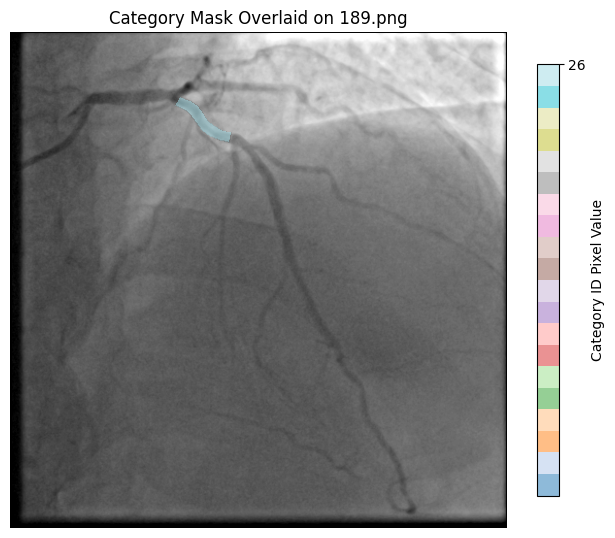

In [3]:
import json
import os
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import numpy as np

# 1. Base directory setups
base_dir = '/kaggle/input/datasets/nirmalgaud/arcade-dataset/arcade/stenosis/test/'
json_path = os.path.join(base_dir, 'annotations/test.json')

with open(json_path, 'r') as file:
    data = json.load(file)

# 2. Pick the target image ID
target_image_id = 100

# 3. Find ALL annotations matching this image_id
image_annotations = [ann for ann in data['annotations'] if ann['image_id'] == target_image_id]
print(f"Found {len(image_annotations)} annotation(s) for image_id {target_image_id}")

# 4. Find the image filename and load it (converting to grayscale for standard medical rendering)
image_filename = next((img['file_name'] for img in data['images'] if img['id'] == target_image_id), f"{target_image_id}.png")
full_image_path = os.path.join(base_dir, 'images', image_filename)
img = Image.open(full_image_path).convert('L')
width, height = img.size

# ----------------------------------------------------
# 5. Create a Single-Channel Integer Mask (0 to 26)
# ----------------------------------------------------
mask_image = Image.new('L', (width, height), 0)
draw = ImageDraw.Draw(mask_image)

for ann in image_annotations:
    category_id = ann['category_id']        # Single integer value (e.g., 23)
    segmentation_polygon = ann['segmentation'][0]
    draw.polygon(segmentation_polygon, fill=category_id)

semantic_mask_np = np.array(mask_image)
# ----------------------------------------------------

# 6. Mask out the background (0) for visualization purposes
# This tells matplotlib to hide the background 0s completely so the original image shows through
masked_labels = np.ma.masked_where(semantic_mask_np == 0, semantic_mask_np)

# 7. Set up the plot to visualize the overlay
fig, ax = plt.subplots(figsize=(8, 8))

# Layer 1: Plot the base original image
ax.imshow(img, cmap='gray')

# Layer 2: Overlay the color-mapped category indices where values > 0
# alpha=0.5 lets you see the structures underneath the mask colors
im = ax.imshow(masked_labels, cmap='tab20', alpha=0.5, vmin=1, vmax=26)

# Add a colorbar for verification (only showing ticks for categories that exist on this image)
unique_cats = np.unique(semantic_mask_np)
present_cats = unique_cats[unique_cats > 0] # Filter out the background 0

if len(present_cats) > 0:
    cbar = plt.colorbar(im, ax=ax, label="Category ID Pixel Value", shrink=0.7)
    cbar.set_ticks(present_cats)

plt.title(f"Category Mask Overlaid on {image_filename}")
plt.axis('off')
plt.show()

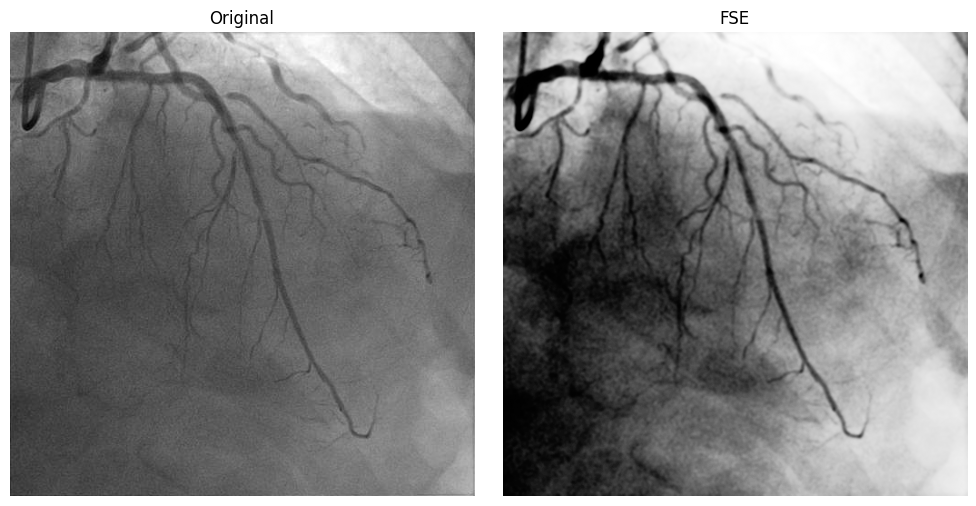

In [4]:
import cv2
import numpy as np


# ==========================================================
# FSE: Filtering Smoothing Equalization
# (Chen et al., "SFAG-DeepLabv3+", Neurocomputing 2025)
#
# Pipeline:
#     Original
#       -> Gaussian smoothing filter   (denoise, Eq. 1-2 in paper)
#       -> CDF-based histogram equalization (contrast, Eq. 3-4 in paper)
# ==========================================================

def _cdf_histogram_equalization(img):
    """
    CDF-based global histogram equalization, matching the paper's
    H(a) = round( (CDF(a) - CDF(min)) / (M*N - CDF(min)) * (L-1) )
    where CDF is the cumulative pixel COUNT (not probability).

    Implemented manually for transparency / fidelity to the paper.
    Mathematically equivalent to cv2.equalizeHist.
    """
    L = 256
    M_N = img.size  # total pixel count

    # Histogram (raw counts) and CDF
    hist = cv2.calcHist([img], [0], None, [L], [0, L]).flatten()
    cdf = np.cumsum(hist)

    # First non-zero CDF value (CDF(min))
    nonzero = cdf[cdf > 0]
    cdf_min = nonzero.min() if nonzero.size > 0 else 0

    # Mapping table H(a)
    denom = max(M_N - cdf_min, 1)  # avoid div-by-zero
    mapping = np.round((cdf - cdf_min) / denom * (L - 1))
    mapping = np.clip(mapping, 0, L - 1).astype(np.uint8)

    return mapping[img]


def fse_preprocess(img, kernel_size=5, sigma=1.5, use_cv2_equalize=True):
    """
    Apply FSE (Filtering Smoothing Equalization) enhancement to a
    coronary angiography image.

    Parameters
    ----------
    img : np.ndarray
        Input image, grayscale (H,W) or BGR (H,W,3).
    kernel_size : int
        Gaussian smoothing window size (paper uses 5x5).
    sigma : float
        Standard deviation for the Gaussian filter.
    use_cv2_equalize : bool
        If True, use cv2.equalizeHist (fast, C-optimized, numerically
        identical algorithm). If False, use the manual CDF implementation
        above (useful if you want to inspect/modify the mapping).

    Returns
    -------
    np.ndarray
        FSE-enhanced grayscale image (uint8).
    """
    if img is None:
        raise ValueError("fse_preprocess received a None image")

    # Ensure single-channel grayscale input
    if len(img.shape) == 3:
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    else:
        gray = img.copy()

    if gray.dtype != np.uint8:
        gray = cv2.normalize(gray, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

    # ---- Step 1: Gaussian smoothing filter (denoise) ----
    smoothed = cv2.GaussianBlur(
        gray,
        (kernel_size, kernel_size),
        sigmaX=sigma,
        sigmaY=sigma
    )

    # ---- Step 2: Histogram equalization via CDF remapping (contrast) ----
    if use_cv2_equalize:
        equalized = cv2.equalizeHist(smoothed)
    else:
        equalized = _cdf_histogram_equalization(smoothed)

    return equalized


# ==========================================================
# Quick sanity check / visualization
# ==========================================================
if __name__ == "__main__":
    sample_path = "/kaggle/input/datasets/nirmalgaud/arcade-dataset/arcade/stenosis/train/images/2.png"
    img = cv2.imread(sample_path, cv2.IMREAD_GRAYSCALE)

    fse_out = fse_preprocess(img)

    fig, ax = plt.subplots(1, 2, figsize=(10, 5))
    ax[0].imshow(img, cmap="gray"); ax[0].set_title("Original"); ax[0].axis("off")
    ax[1].imshow(fse_out, cmap="gray"); ax[1].set_title("FSE"); ax[1].axis("off")
    plt.tight_layout()
    plt.show()

In [5]:
!pip install opencv-contrib-python-headless -q

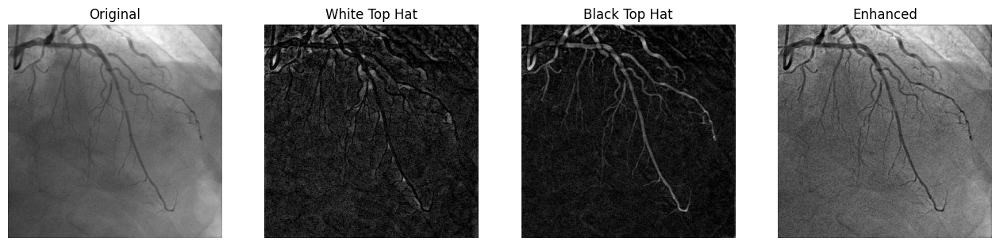

In [6]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# ----------------------------
# Read image
# ----------------------------
img = cv2.imread("/kaggle/input/datasets/nirmalgaud/arcade-dataset/arcade/stenosis/train/images/2.png", cv2.IMREAD_GRAYSCALE)

# ----------------------------
# Structuring Element
# ----------------------------
kernel = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE,
    (15,15)          # Try 9,11,15,21
)

# ----------------------------
# White Top Hat
# ----------------------------
white_tophat = cv2.morphologyEx(
    img,
    cv2.MORPH_TOPHAT,
    kernel
)

# ----------------------------
# Black Top Hat
# ----------------------------
black_tophat = cv2.morphologyEx(
    img,
    cv2.MORPH_BLACKHAT,
    kernel
)

# ----------------------------
# Enhanced image
# F + Fw - Fb
# ----------------------------
enhanced = cv2.add(img, white_tophat)
enhanced = cv2.subtract(enhanced, black_tophat)

# ----------------------------
# Display
# ----------------------------
plt.figure(figsize=(16,4))

plt.subplot(141)
plt.imshow(img,cmap='gray')
plt.title("Original")
plt.axis("off")

plt.subplot(142)
plt.imshow(white_tophat,cmap='gray')
plt.title("White Top Hat")
plt.axis("off")

plt.subplot(143)
plt.imshow(black_tophat,cmap='gray')
plt.title("Black Top Hat")
plt.axis("off")

plt.subplot(144)
plt.imshow(enhanced,cmap='gray')
plt.title("Enhanced")
plt.axis("off")

plt.show()

In [7]:
import os
import json
import shutil
import cv2
from PIL import Image, ImageDraw
# ==========================================================
# Root directories
# ==========================================================
INPUT_ROOT = "/kaggle/input/datasets/nirmalgaud/arcade-dataset/arcade/syntax"
OUTPUT_ROOT = "/kaggle/working/arcade-stenosis"
splits = ["train", "val", "test"]
# ==========================================================
# Process each split
# ==========================================================
for split in splits:
    print(f"\nProcessing {split}...")
    base_dir = os.path.join(INPUT_ROOT, split)
    image_dir = os.path.join(base_dir, "images")
    json_path = os.path.join(base_dir, "annotations", f"{split}.json")
    output_image_dir = os.path.join(OUTPUT_ROOT, split, "images")
    output_mask_dir = os.path.join(OUTPUT_ROOT, split, "masks")
    os.makedirs(output_image_dir, exist_ok=True)
    os.makedirs(output_mask_dir, exist_ok=True)
    # ------------------------------------------------------
    # Load annotations
    # ------------------------------------------------------
    with open(json_path, "r") as f:
        data = json.load(f)
    # Group annotations by image_id
    annotations_by_image = {}
    for ann in data["annotations"]:
        annotations_by_image.setdefault(ann["image_id"], []).append(ann)
    # Map image_id -> image information
    images = {img["id"]: img for img in data["images"]}
    # ------------------------------------------------------
    # Process images (iterate using JSON)
    # ------------------------------------------------------
    for image_id, img_info in images.items():
        image_file = img_info["file_name"]
        image_path = os.path.join(image_dir, image_file)
        if not os.path.exists(image_path):
            continue
        # Get image size
        with Image.open(image_path) as img:
            width, height = img.size
        # Create blank mask
        mask = Image.new("L", (width, height), 0)
        draw = ImageDraw.Draw(mask)
        # Draw all stenosis polygons
        for ann in annotations_by_image.get(image_id, []):
            for polygon in ann["segmentation"]:
                if len(polygon) >= 6:
                    draw.polygon(polygon, fill=255)
        # ------------------------------------------------------
        # Read and preprocess image
        # ------------------------------------------------------
        image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
        if image is None:
            continue
        processed_image = fse_preprocess(image)        # Save processed image
        cv2.imwrite(
            os.path.join(output_image_dir, image_file),
            processed_image
        )
        # Save mask
        mask.save(
            os.path.join(output_mask_dir, image_file)
        )
    print(f"✓ Finished {split}: {len(images)} images")
    print("\nDataset creation complete!")


Processing train...
✓ Finished train: 1000 images

Dataset creation complete!

Processing val...
✓ Finished val: 200 images

Dataset creation complete!

Processing test...
✓ Finished test: 300 images

Dataset creation complete!


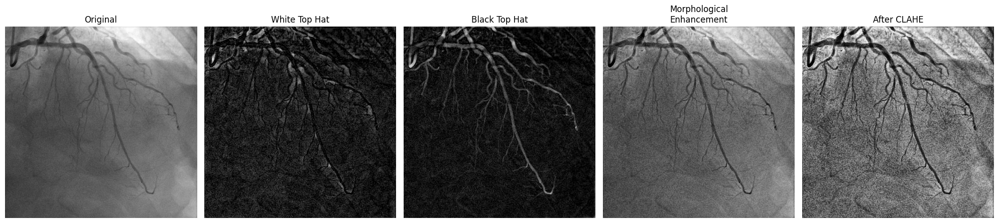

In [8]:
import cv2
import matplotlib.pyplot as plt

# ----------------------------
# Read image
# ----------------------------
img = cv2.imread("/kaggle/input/datasets/nirmalgaud/arcade-dataset/arcade/stenosis/train/images/2.png", cv2.IMREAD_GRAYSCALE)

# ----------------------------
# Morphological Enhancement
# ----------------------------
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))

white_tophat = cv2.morphologyEx(img, cv2.MORPH_TOPHAT, kernel)
black_tophat = cv2.morphologyEx(img, cv2.MORPH_BLACKHAT, kernel)

enhanced = cv2.add(img, white_tophat)
enhanced = cv2.subtract(enhanced, black_tophat)

# ----------------------------
# CLAHE
# ----------------------------
clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

clahe_img = clahe.apply(enhanced)

# ----------------------------
# Display
# ----------------------------
plt.figure(figsize=(20,5))

plt.subplot(1,5,1)
plt.imshow(img, cmap='gray')
plt.title("Original")
plt.axis("off")

plt.subplot(1,5,2)
plt.imshow(white_tophat, cmap='gray')
plt.title("White Top Hat")
plt.axis("off")

plt.subplot(1,5,3)
plt.imshow(black_tophat, cmap='gray')
plt.title("Black Top Hat")
plt.axis("off")

plt.subplot(1,5,4)
plt.imshow(enhanced, cmap='gray')
plt.title("Morphological\nEnhancement")
plt.axis("off")

plt.subplot(1,5,5)
plt.imshow(clahe_img, cmap='gray')
plt.title("After CLAHE")
plt.axis("off")

plt.tight_layout()
plt.show()

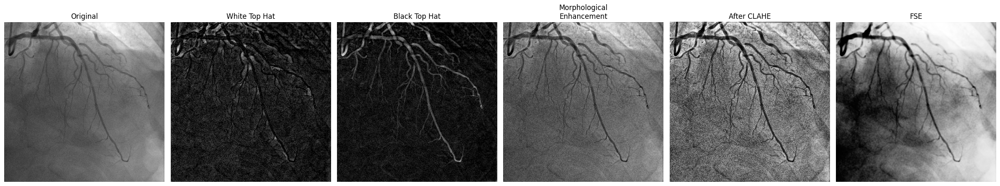

Standard deviation (higher = more contrast, per SFAG paper Table 4/5):
  Original:     27.817
  TopHat+CLAHE: 40.867
  FSE:          73.030


In [9]:
import cv2
import matplotlib.pyplot as plt

# ----------------------------
# Read image
# ----------------------------
img = cv2.imread("/kaggle/input/datasets/nirmalgaud/arcade-dataset/arcade/stenosis/train/images/2.png", cv2.IMREAD_GRAYSCALE)

# ----------------------------
# Morphological Enhancement
# ----------------------------
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))
white_tophat = cv2.morphologyEx(img, cv2.MORPH_TOPHAT, kernel)
black_tophat = cv2.morphologyEx(img, cv2.MORPH_BLACKHAT, kernel)
enhanced = cv2.add(img, white_tophat)
enhanced = cv2.subtract(enhanced, black_tophat)

# ----------------------------
# CLAHE
# ----------------------------
clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)
clahe_img = clahe.apply(enhanced)

# ----------------------------
# FSE (Filtering Smoothing Equalization)
# ----------------------------
fse_img = fse_preprocess(img)   # requires fse_preprocess to be defined in an earlier cell

# ----------------------------
# Display
# ----------------------------
plt.figure(figsize=(24,5))

plt.subplot(1,6,1)
plt.imshow(img, cmap='gray')
plt.title("Original")
plt.axis("off")

plt.subplot(1,6,2)
plt.imshow(white_tophat, cmap='gray')
plt.title("White Top Hat")
plt.axis("off")

plt.subplot(1,6,3)
plt.imshow(black_tophat, cmap='gray')
plt.title("Black Top Hat")
plt.axis("off")

plt.subplot(1,6,4)
plt.imshow(enhanced, cmap='gray')
plt.title("Morphological\nEnhancement")
plt.axis("off")

plt.subplot(1,6,5)
plt.imshow(clahe_img, cmap='gray')
plt.title("After CLAHE")
plt.axis("off")

plt.subplot(1,6,6)
plt.imshow(fse_img, cmap='gray')
plt.title("FSE")
plt.axis("off")

plt.tight_layout()
plt.show()

# ----------------------------
# Quick quantitative check (matches the SFAG paper's std-dev comparison)
# ----------------------------
import numpy as np

print("Standard deviation (higher = more contrast, per SFAG paper Table 4/5):")
print(f"  Original:     {np.std(img):.3f}")
print(f"  TopHat+CLAHE: {np.std(clahe_img):.3f}")
print(f"  FSE:          {np.std(fse_img):.3f}")

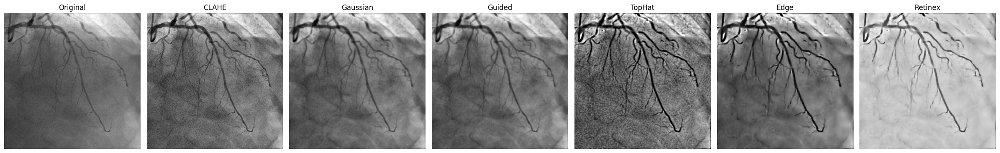

In [10]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# ==========================================================
# Single Scale Retinex
# ==========================================================
def single_scale_retinex(img, sigma=30):

    img = img.astype(np.float32) + 1

    blur = cv2.GaussianBlur(img, (0,0), sigma)

    retinex = np.log(img) - np.log(blur + 1)

    retinex = cv2.normalize(
        retinex,
        None,
        0,
        255,
        cv2.NORM_MINMAX
    )

    return retinex.astype(np.uint8)


# ==========================================================
# Multi-scale TopHat
# ==========================================================
def multiscale_tophat(img):

    result = img.astype(np.int16)

    for s in [5,9,13]:

        kernel = cv2.getStructuringElement(
            cv2.MORPH_ELLIPSE,
            (s,s)
        )

        white = cv2.morphologyEx(
            img,
            cv2.MORPH_TOPHAT,
            kernel
        )

        black = cv2.morphologyEx(
            img,
            cv2.MORPH_BLACKHAT,
            kernel
        )

        result += white
        result -= black

    result = np.clip(result,0,255)

    return result.astype(np.uint8)


# ==========================================================
# Guided Filter
# ==========================================================
def guided(img):

    return cv2.ximgproc.guidedFilter(
        guide=img,
        src=img,
        radius=7,
        eps=1e-3
    )


from skimage.filters import frangi

def frangi_filter(img):

    vessel = frangi(
        img/255.0,
        sigmas=range(1,8),
        black_ridges=False
    )

    vessel = cv2.normalize(
        vessel,
        None,
        0,
        255,
        cv2.NORM_MINMAX
    )

    return vessel.astype(np.uint8)



def gamma_correction(img, gamma=0.8):

    table = np.array([
        ((i / 255.0) ** gamma) * 255
        for i in np.arange(256)
    ]).astype("uint8")

    return cv2.LUT(img, table)



from skimage.filters import sato

def sato_filter(img):

    vessel = sato(
        img/255.0,
        sigmas=range(1,8),
        black_ridges=False
    )

    vessel = cv2.normalize(
        vessel,
        None,
        0,
        255,
        cv2.NORM_MINMAX
    )

    return vessel.astype(np.uint8)


from skimage.filters import hessian

def hessian_filter(img):

    vessel = hessian(
        img/255.0,
        sigmas=range(1,8),
        black_ridges=False
    )

    vessel = cv2.normalize(
        vessel,
        None,
        0,
        255,
        cv2.NORM_MINMAX
    )

    return vessel.astype(np.uint8)


def edge_preserving(img):

    img_bgr = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)

    out = cv2.edgePreservingFilter(
        img_bgr,
        flags=1,
        sigma_s=60,
        sigma_r=0.4
    )

    return cv2.cvtColor(out, cv2.COLOR_BGR2GRAY)


# ==========================================================
# Complete Pipeline
# ==========================================================
def preprocess(img):

    # CLAHE
    clahe = cv2.createCLAHE(
        clipLimit=2,
        tileGridSize=(8,8)
    )

    img1 = clahe.apply(img)

    # Circular Gaussian
    img2 = cv2.GaussianBlur(
        img1,
        (7,7),
        1.5
    )

    # Guided Filter
    img3 = guided(img2)

    # Multi-scale TopHat
    img4 = multiscale_tophat(img3)

    # edge preserving
    img5 = edge_preserving(
        img4,
    )

    # Retinex instead of Homomorphic
    img6 = single_scale_retinex(
        img5,
        sigma = 30
    )

    return img1,img2,img3,img4,img5, img6


# ==========================================================
# Read image
# ==========================================================
img = cv2.imread(
    "/kaggle/input/datasets/nirmalgaud/arcade-dataset/arcade/stenosis/train/images/2.png",
    cv2.IMREAD_GRAYSCALE
)

clahe, gaussian, guided_img, tophat, edge, retinex = preprocess(img)

# ==========================================================
# Display
# ==========================================================
titles = [
    "Original",
    "CLAHE",
    "Gaussian",
    "Guided",
    "TopHat",
    "Edge",
    "Retinex"
]

images = [
    img,
    clahe,
    gaussian,
    guided_img,
    tophat,
    edge,
    retinex
]

plt.figure(figsize=(24,5))

for i in range(len(images)):
    plt.subplot(1,7,i+1)
    plt.imshow(images[i], cmap="gray")
    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()
plt.show()

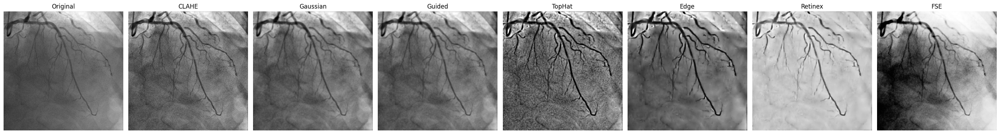

Standard deviation of each stage (higher ≈ more contrast/detail spread):
  Original  : 27.817
  CLAHE     : 31.909
  Gaussian  : 30.001
  Guided    : 30.001
  TopHat    : 41.045
  Edge      : 34.378
  Retinex   : 24.853
  FSE       : 73.030


In [11]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# ==========================================================
# Single Scale Retinex
# ==========================================================
def single_scale_retinex(img, sigma=30):

    img = img.astype(np.float32) + 1

    blur = cv2.GaussianBlur(img, (0,0), sigma)

    retinex = np.log(img) - np.log(blur + 1)

    retinex = cv2.normalize(
        retinex,
        None,
        0,
        255,
        cv2.NORM_MINMAX
    )

    return retinex.astype(np.uint8)


# ==========================================================
# Multi-scale TopHat
# ==========================================================
def multiscale_tophat(img):

    result = img.astype(np.int16)

    for s in [5,9,13]:

        kernel = cv2.getStructuringElement(
            cv2.MORPH_ELLIPSE,
            (s,s)
        )

        white = cv2.morphologyEx(
            img,
            cv2.MORPH_TOPHAT,
            kernel
        )

        black = cv2.morphologyEx(
            img,
            cv2.MORPH_BLACKHAT,
            kernel
        )

        result += white
        result -= black

    result = np.clip(result,0,255)

    return result.astype(np.uint8)


# ==========================================================
# Guided Filter
# ==========================================================
def guided(img):

    return cv2.ximgproc.guidedFilter(
        guide=img,
        src=img,
        radius=7,
        eps=1e-3
    )


from skimage.filters import frangi

def frangi_filter(img):

    vessel = frangi(
        img/255.0,
        sigmas=range(1,8),
        black_ridges=False
    )

    vessel = cv2.normalize(
        vessel,
        None,
        0,
        255,
        cv2.NORM_MINMAX
    )

    return vessel.astype(np.uint8)



def gamma_correction(img, gamma=0.8):

    table = np.array([
        ((i / 255.0) ** gamma) * 255
        for i in np.arange(256)
    ]).astype("uint8")

    return cv2.LUT(img, table)



from skimage.filters import sato

def sato_filter(img):

    vessel = sato(
        img/255.0,
        sigmas=range(1,8),
        black_ridges=False
    )

    vessel = cv2.normalize(
        vessel,
        None,
        0,
        255,
        cv2.NORM_MINMAX
    )

    return vessel.astype(np.uint8)


from skimage.filters import hessian

def hessian_filter(img):

    vessel = hessian(
        img/255.0,
        sigmas=range(1,8),
        black_ridges=False
    )

    vessel = cv2.normalize(
        vessel,
        None,
        0,
        255,
        cv2.NORM_MINMAX
    )

    return vessel.astype(np.uint8)


def edge_preserving(img):

    img_bgr = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)

    out = cv2.edgePreservingFilter(
        img_bgr,
        flags=1,
        sigma_s=60,
        sigma_r=0.4
    )

    return cv2.cvtColor(out, cv2.COLOR_BGR2GRAY)


# ==========================================================
# Complete Pipeline
# ==========================================================
def preprocess(img):

    # CLAHE
    clahe = cv2.createCLAHE(
        clipLimit=2,
        tileGridSize=(8,8)
    )

    img1 = clahe.apply(img)

    # Circular Gaussian
    img2 = cv2.GaussianBlur(
        img1,
        (7,7),
        1.5
    )

    # Guided Filter
    img3 = guided(img2)

    # Multi-scale TopHat
    img4 = multiscale_tophat(img3)

    # edge preserving
    img5 = edge_preserving(
        img4,
    )

    # Retinex instead of Homomorphic
    img6 = single_scale_retinex(
        img5,
        sigma = 30
    )

    # FSE (Filtering Smoothing Equalization) — applied independently to the
    # original image, for a fair side-by-side comparison against this pipeline
    img7 = fse_preprocess(img)   # requires fse_preprocess defined in an earlier cell

    return img1, img2, img3, img4, img5, img6, img7


# ==========================================================
# Read image
# ==========================================================
img = cv2.imread(
    "/kaggle/input/datasets/nirmalgaud/arcade-dataset/arcade/stenosis/train/images/2.png",
    cv2.IMREAD_GRAYSCALE
)

clahe, gaussian, guided_img, tophat, edge, retinex, fse = preprocess(img)

# ==========================================================
# Display
# ==========================================================
titles = [
    "Original",
    "CLAHE",
    "Gaussian",
    "Guided",
    "TopHat",
    "Edge",
    "Retinex",
    "FSE"
]

images = [
    img,
    clahe,
    gaussian,
    guided_img,
    tophat,
    edge,
    retinex,
    fse
]

plt.figure(figsize=(28,5))

for i in range(len(images)):
    plt.subplot(1,8,i+1)
    plt.imshow(images[i], cmap="gray")
    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()
plt.show()

# ==========================================================
# Quick quantitative comparison (std dev, as used in SFAG paper)
# ==========================================================
print("Standard deviation of each stage (higher ≈ more contrast/detail spread):")
for name, im in zip(titles, images):
    print(f"  {name:10s}: {np.std(im):.3f}")

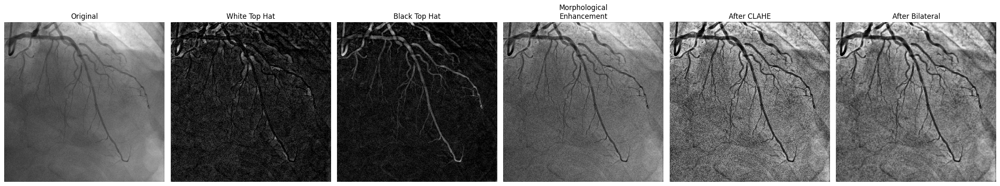

True

In [12]:
import cv2
import matplotlib.pyplot as plt
# ==========================================================
# Read image
# ==========================================================
img = cv2.imread(
    "/kaggle/input/datasets/nirmalgaud/arcade-dataset/arcade/stenosis/train/images/2.png",
    cv2.IMREAD_GRAYSCALE
)
# ==========================================================
# Morphological Enhancement
# F + WhiteTopHat - BlackTopHat
# ==========================================================
kernel = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE,
    (15, 15)
)
white_tophat = cv2.morphologyEx(
    img,
    cv2.MORPH_TOPHAT,
    kernel
)
black_tophat = cv2.morphologyEx(
    img,
    cv2.MORPH_BLACKHAT,
    kernel
)
enhanced = cv2.add(img, white_tophat)
enhanced = cv2.subtract(enhanced, black_tophat)
# ==========================================================
# CLAHE
# ==========================================================
clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)
clahe_img = clahe.apply(enhanced)
# ==========================================================
# Bilateral Filter
# (Removes noise while preserving vessel edges)
# ==========================================================
denoised = cv2.bilateralFilter(
    clahe_img,
    d=5,
    sigmaColor=40,
    sigmaSpace=40
)
# ==========================================================
# Display
# ==========================================================
plt.figure(figsize=(24,5))
plt.subplot(1,6,1)
plt.imshow(img, cmap='gray')
plt.title("Original")
plt.axis("off")
plt.subplot(1,6,2)
plt.imshow(white_tophat, cmap='gray')
plt.title("White Top Hat")
plt.axis("off")
plt.subplot(1,6,3)
plt.imshow(black_tophat, cmap='gray')
plt.title("Black Top Hat")
plt.axis("off")
plt.subplot(1,6,4)
plt.imshow(enhanced, cmap='gray')
plt.title("Morphological\nEnhancement")
plt.axis("off")
plt.subplot(1,6,5)
plt.imshow(clahe_img, cmap='gray')
plt.title("After CLAHE")
plt.axis("off")
plt.subplot(1,6,6)
plt.imshow(denoised, cmap='gray')
plt.title("After Bilateral")
plt.axis("off")
plt.tight_layout()
plt.show()
# ==========================================================
# Save Final Image
# ==========================================================
cv2.imwrite("enhanced_denoised.png", denoised)



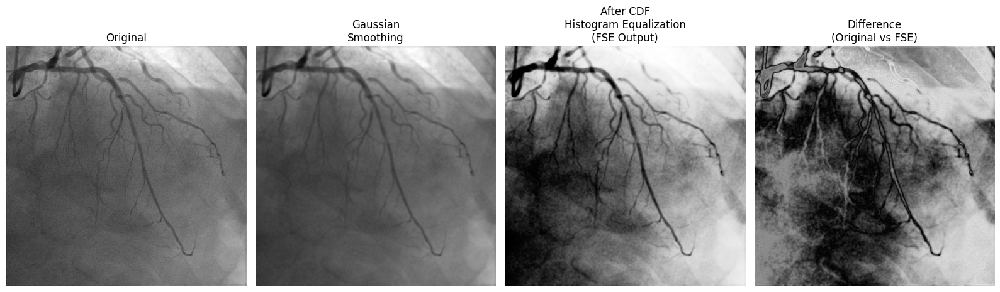

True

In [13]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# ==========================================================
# Read image
# ==========================================================
img = cv2.imread(
    "/kaggle/input/datasets/nirmalgaud/arcade-dataset/arcade/stenosis/train/images/2.png",
    cv2.IMREAD_GRAYSCALE
)

# ==========================================================
# FSE: Filtering Smoothing Equalization
# (Chen et al., "SFAG-DeepLabv3+", Neurocomputing 2025)
#
# Step 1: Gaussian Smoothing Filter (denoise)
# Step 2: CDF-based Histogram Equalization (contrast enhancement)
# ==========================================================

# ----------------------------
# Step 1: Gaussian Smoothing Filter
# ----------------------------
smoothed = cv2.GaussianBlur(
    img,
    (5, 5),
    sigmaX=1.5,
    sigmaY=1.5
)

# ----------------------------
# Step 2: CDF-based Histogram Equalization
# H(a) = round( (CDF(a) - CDF(min)) / (M*N - CDF(min)) * (L-1) )
# ----------------------------
def cdf_histogram_equalization(image):
    L = 256
    M_N = image.size

    hist = cv2.calcHist([image], [0], None, [L], [0, L]).flatten()
    cdf = np.cumsum(hist)

    nonzero = cdf[cdf > 0]
    cdf_min = nonzero.min() if nonzero.size > 0 else 0

    denom = max(M_N - cdf_min, 1)
    mapping = np.round((cdf - cdf_min) / denom * (L - 1))
    mapping = np.clip(mapping, 0, L - 1).astype(np.uint8)

    return mapping[image]

equalized = cdf_histogram_equalization(smoothed)

# ==========================================================
# Display
# ==========================================================
plt.figure(figsize=(16, 5))

plt.subplot(1, 4, 1)
plt.imshow(img, cmap='gray')
plt.title("Original")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(smoothed, cmap='gray')
plt.title("Gaussian\nSmoothing")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(equalized, cmap='gray')
plt.title("After CDF\nHistogram Equalization\n(FSE Output)")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(cv2.absdiff(img, equalized), cmap='gray')
plt.title("Difference\n(Original vs FSE)")
plt.axis("off")

plt.tight_layout()
plt.show()

# ==========================================================
# Save Final Image
# ==========================================================
cv2.imwrite("fse_enhanced.png", equalized)

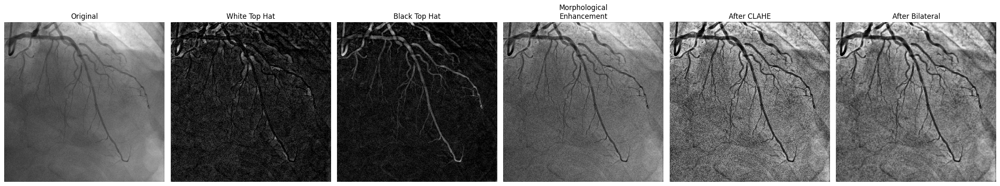

True

In [14]:
import cv2
import matplotlib.pyplot as plt

# ==========================================================
# Read image
# ==========================================================
img = cv2.imread(
    "/kaggle/input/datasets/nirmalgaud/arcade-dataset/arcade/stenosis/train/images/2.png",
    cv2.IMREAD_GRAYSCALE
)

# ==========================================================
# Morphological Enhancement
# F + WhiteTopHat - BlackTopHat
# ==========================================================
kernel = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE,
    (15, 15)
)

white_tophat = cv2.morphologyEx(
    img,
    cv2.MORPH_TOPHAT,
    kernel
)

black_tophat = cv2.morphologyEx(
    img,
    cv2.MORPH_BLACKHAT,
    kernel
)

enhanced = cv2.add(img, white_tophat)
enhanced = cv2.subtract(enhanced, black_tophat)

# ==========================================================
# CLAHE
# ==========================================================
clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

clahe_img = clahe.apply(enhanced)

# ==========================================================
# Bilateral Filter
# (Removes noise while preserving vessel edges)
# ==========================================================
denoised = cv2.bilateralFilter(
    clahe_img,
    d=5,
    sigmaColor=40,
    sigmaSpace=40
)

# ==========================================================
# Display
# ==========================================================
plt.figure(figsize=(24,5))

plt.subplot(1,6,1)
plt.imshow(img, cmap='gray')
plt.title("Original")
plt.axis("off")

plt.subplot(1,6,2)
plt.imshow(white_tophat, cmap='gray')
plt.title("White Top Hat")
plt.axis("off")

plt.subplot(1,6,3)
plt.imshow(black_tophat, cmap='gray')
plt.title("Black Top Hat")
plt.axis("off")

plt.subplot(1,6,4)
plt.imshow(enhanced, cmap='gray')
plt.title("Morphological\nEnhancement")
plt.axis("off")

plt.subplot(1,6,5)
plt.imshow(clahe_img, cmap='gray')
plt.title("After CLAHE")
plt.axis("off")

plt.subplot(1,6,6)
plt.imshow(denoised, cmap='gray')
plt.title("After Bilateral")
plt.axis("off")

plt.tight_layout()
plt.show()

# ==========================================================
# Save Final Image
# ==========================================================
cv2.imwrite("enhanced_denoised.png", denoised)

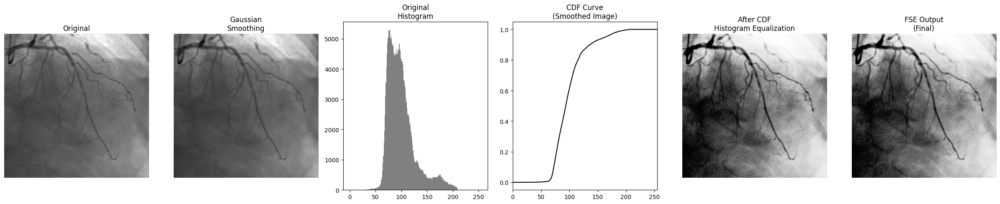

True

In [15]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# ==========================================================
# Read image
# ==========================================================
img = cv2.imread(
    "/kaggle/input/datasets/nirmalgaud/arcade-dataset/arcade/stenosis/train/images/2.png",
    cv2.IMREAD_GRAYSCALE
)

# ==========================================================
# FSE: Filtering Smoothing Equalization
# (Chen et al., "SFAG-DeepLabv3+", Neurocomputing 2025)
#
# Step 1: Gaussian Smoothing Filter (denoise)
# Step 2: CDF-based Histogram Equalization (contrast enhancement)
# ==========================================================

# ----------------------------
# Step 1: Gaussian Smoothing Filter
# ----------------------------
smoothed = cv2.GaussianBlur(
    img,
    (5, 5),
    sigmaX=1.5,
    sigmaY=1.5
)

# ----------------------------
# Step 2: CDF-based Histogram Equalization
# H(a) = round( (CDF(a) - CDF(min)) / (M*N - CDF(min)) * (L-1) )
# ----------------------------
def cdf_histogram_equalization(image):
    L = 256
    M_N = image.size

    hist = cv2.calcHist([image], [0], None, [L], [0, L]).flatten()
    cdf = np.cumsum(hist)

    nonzero = cdf[cdf > 0]
    cdf_min = nonzero.min() if nonzero.size > 0 else 0

    denom = max(M_N - cdf_min, 1)
    mapping = np.round((cdf - cdf_min) / denom * (L - 1))
    mapping = np.clip(mapping, 0, L - 1).astype(np.uint8)

    return mapping[image], cdf, mapping

equalized, cdf_curve, mapping_table = cdf_histogram_equalization(smoothed)

# ==========================================================
# Display
# ==========================================================
plt.figure(figsize=(24, 5))

plt.subplot(1, 6, 1)
plt.imshow(img, cmap='gray')
plt.title("Original")
plt.axis("off")

plt.subplot(1, 6, 2)
plt.imshow(smoothed, cmap='gray')
plt.title("Gaussian\nSmoothing")
plt.axis("off")

plt.subplot(1, 6, 3)
plt.hist(img.ravel(), bins=256, range=(0, 255), color='gray')
plt.title("Original\nHistogram")

plt.subplot(1, 6, 4)
plt.plot(cdf_curve / cdf_curve.max(), color='black')
plt.title("CDF Curve\n(Smoothed Image)")
plt.xlim([0, 255])

plt.subplot(1, 6, 5)
plt.imshow(equalized, cmap='gray')
plt.title("After CDF\nHistogram Equalization")
plt.axis("off")

plt.subplot(1, 6, 6)
plt.imshow(equalized, cmap='gray')
plt.title("FSE Output\n(Final)")
plt.axis("off")

plt.tight_layout()
plt.show()

# ==========================================================
# Save Final Image
# ==========================================================
cv2.imwrite("fse_enhanced.png", equalized)

In [16]:
IMG_SIZE = [512, 512]

In [17]:
import os
import cv2
import numpy as np
import pandas as pd
import random
import matplotlib.pyplot as plt
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import albumentations as album
from sklearn.model_selection import train_test_split

from albumentations.pytorch import ToTensorV2

# Set device
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

Using device: cuda


**usual evaluation**

In [18]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ===============================
# 1. Dataset Path
# ===============================
DATA_DIR = "/kaggle/working/arcade-stenosis"

TRAIN_IMG_DIR = os.path.join(DATA_DIR, "train", "images")
TRAIN_MASK_DIR = os.path.join(DATA_DIR, "train", "masks")

VALID_IMG_DIR = os.path.join(DATA_DIR, "val", "images")
VALID_MASK_DIR = os.path.join(DATA_DIR, "val", "masks")

TEST_IMG_DIR = os.path.join(DATA_DIR, "test", "images")
TEST_MASK_DIR = os.path.join(DATA_DIR, "test", "masks")


# ===============================
# 2. Create DataFrame
# ===============================
def create_df(img_dir, mask_dir):

    image_files = sorted(os.listdir(img_dir))
    mask_files = sorted(os.listdir(mask_dir))

    # Ensure image-mask pairs are aligned
    common_files = sorted(list(set(image_files) & set(mask_files)))

    df = pd.DataFrame({
        "image_path": [os.path.join(img_dir, f) for f in common_files],
        "mask_path": [os.path.join(mask_dir, f) for f in common_files]
    })

    return df


# ===============================
# 3. Create Train / Val / Test DataFrames
# ===============================
train_df = create_df(TRAIN_IMG_DIR, TRAIN_MASK_DIR)
valid_df = create_df(VALID_IMG_DIR, VALID_MASK_DIR)
test_df = create_df(TEST_IMG_DIR, TEST_MASK_DIR)

print("Train size:", len(train_df))
print("Valid size:", len(valid_df))
print("Test size:", len(test_df))


# ===============================
# 4. Class Definitions
# ===============================
class_names = ['background', 'stenosis']

class_rgb_values = np.array([
    [0, 0, 0],        # background
    [255, 255, 255]   # ulcer
])

select_classes = ['background', 'stenosis']
select_class_indices = [class_names.index(cls) for cls in select_classes]
select_class_rgb_values = class_rgb_values[select_class_indices]


# ===============================
# 5. Visualization
# ===============================
def visualize(**images):
    plt.figure(figsize=(20, 8))

    for i, (name, image) in enumerate(images.items()):
        plt.subplot(1, len(images), i + 1)
        plt.title(name)
        plt.axis("off")
        plt.imshow(image)

    plt.show()


# ===============================
# 6. One-hot Encoding
# ===============================
def one_hot_encode(mask, label_values):
    semantic_map = []

    for colour in label_values:
        class_map = np.all(mask == colour, axis=-1)
        semantic_map.append(class_map)

    return np.stack(semantic_map, axis=-1).astype(np.float32)


# ===============================
# 7. Reverse One-hot
# ===============================
def reverse_one_hot(mask):
    return np.argmax(mask, axis=-1)


# ===============================
# 8. Colour Code
# ===============================
def colour_code_segmentation(mask, label_values):
    return label_values[mask.astype(int)]

Train size: 1000
Valid size: 200
Test size: 300


Image shape: (512, 512, 3)
Mask shape: (512, 512, 3)
Unique pixels:
 [[  0   0   0]
 [255 255 255]]
Mask Encoder shape: (512, 512, 2)


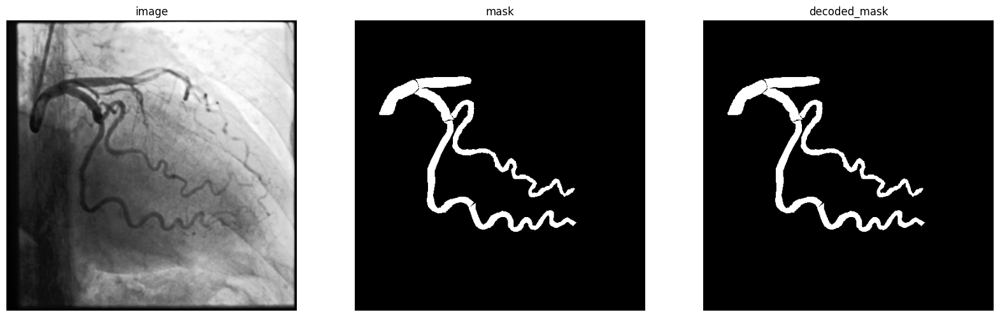

In [19]:
# ===============================
# 9. Test One Sample
# ===============================
sample = valid_df.iloc[100]

# Load image
image = cv2.imread(sample["image_path"])
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Load mask
mask = cv2.imread(sample["mask_path"])
mask = cv2.cvtColor(mask, cv2.COLOR_BGR2RGB)

print("Image shape:", image.shape)
print("Mask shape:", mask.shape)

# Unique pixel check
unique_pixels = np.unique(mask.reshape(-1, 3), axis=0)
print("Unique pixels:\n", unique_pixels)

# Encode
mask_encoded = one_hot_encode(mask, class_rgb_values)
print("Mask Encoder shape:", mask_encoded.shape)

# Decode
mask_decoded = reverse_one_hot(mask_encoded)
mask_colored = colour_code_segmentation(mask_decoded, class_rgb_values)

# Visualize
visualize(
    image=image,
    mask=mask,
    decoded_mask=mask_colored
)

**for cross dataset evaluation**

In [20]:
class AZDataGenerator(Dataset):
    def __init__(self, df, class_rgb_values, augmentation=None, preprocessing=None):
        self.image_paths = df['image_path'].tolist()
        self.mask_paths = df['mask_path'].tolist()
        self.class_rgb_values = class_rgb_values
        self.augmentation = augmentation
        self.preprocessing = preprocessing

    def __getitem__(self, i):
        image = cv2.cvtColor(cv2.imread(self.image_paths[i]), cv2.COLOR_BGR2RGB)
        mask = cv2.cvtColor(cv2.imread(self.mask_paths[i]), cv2.COLOR_BGR2RGB)
        mask = one_hot_encode(mask, self.class_rgb_values).astype('float')

        if self.augmentation:
            sample = self.augmentation(image=image, mask=mask)
            image, mask = sample['image'], sample['mask']

        if self.preprocessing:
            sample = self.preprocessing(image=image, mask=mask)
            image, mask = sample['image'], sample['mask']

        return image, mask

    def __len__(self):
        return len(self.image_paths)

# Augmentations
def get_training_augmentation():
    return album.Compose([
        album.HorizontalFlip(p=0.5),  # Existing: Randomly flip horizontally
        # album.VerticalFlip(p=0.5),    # Randomly flip vertically (polyps can appear in any orientation) 
        album.Rotate(limit=10, p=0.5),
        album.ShiftScaleRotate(shift_limit=0.05,scale_limit=0.10,rotate_limit=10,border_mode=cv2.BORDER_CONSTANT,p=0.5),
        # album.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, p=0.5),
        # album.ElasticTransform(alpha=120, sigma=120 * 0.05, p=0.3),
        album.RandomBrightnessContrast(brightness_limit=0.2,contrast_limit=0.2,p=0.5),
        album.RandomGamma(gamma_limit=(80,120),p=0.3),
        # album.CLAHE(clip_limit=2,p=0.3),
        album.RandomResizedCrop(size=IMG_SIZE,scale=(0.8,1.0),ratio=(0.95,1.05),p=0.3),
        album.CoarseDropout(num_holes_range=(1,4),hole_height_range=(20,40),hole_width_range=(20,40),fill=0,p=0.2),
        album.Resize(IMG_SIZE[0], IMG_SIZE[1]),  # Adjust to your input size
    ])

def get_validation_augmentation():
    return album.Compose([
        album.PadIfNeeded(min_height=IMG_SIZE[0], min_width=IMG_SIZE[1], always_apply=True, border_mode=cv2.BORDER_CONSTANT, value=0)
    ])

def to_tensor(x, **kwargs):
    return x.transpose(2, 0, 1).astype('float32')

def get_preprocessing():
    return album.Compose([
        album.Resize(height=IMG_SIZE[0], width=IMG_SIZE[1], always_apply=True),  # Resize to 256x256
        album.Lambda(image=to_tensor, mask=to_tensor)  # Convert to tensor
    ])


# def get_preprocessing():
#     return album.Compose([
#         album.Resize(height=IMG_SIZE[0], width=IMG_SIZE[1], always_apply=True),  # Resize to 256x256
#         album.Equalize(always_apply=True),  # Histogram equalization
#         album.Lambda(image=to_tensor, mask=to_tensor)  # Convert to tensor
#     ])

In [21]:
# import cv2
# import matplotlib.pyplot as plt
# import albumentations as album

# # Load image using OpenCV
# image_path = '/kaggle/input/colon-datasets/Colon Datasets/clinicdb/PNG/Original/1.png'  # Replace with your image path
# image = cv2.imread(image_path)
# image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)  # Convert BGR to RGB

# # Equalization transform
# equalize_transform = album.Compose([
#     album.Equalize(always_apply=True)
# ])

# # Apply equalization
# equalized = equalize_transform(image=image)['image']

# # Plot original and equalized images side by side
# plt.figure(figsize=(10, 5))

# plt.subplot(1, 2, 1)
# plt.imshow(image)
# plt.title('Original')
# plt.axis('off')

# plt.subplot(1, 2, 2)
# plt.imshow(equalized)
# plt.title('Equalized')
# plt.axis('off')

# plt.tight_layout()
# plt.show()

In [22]:
###################################################
# Copyright (c) 2019                              #
# Authors: @iArunava <iarunavaofficial@gmail.com> #
#          @AvivSham <mista2311@gmail.com>        #
#                                                 #
# License: BSD License 3.0                        #
#                                                 #
# The Code in this file is distributed for free   #
# usage and modification with proper linkage back #
# to this repository.                             #
###################################################

import torch
import torch.nn as nn

class InitialBlock(nn.Module):
    def __init__ (self,in_channels = 3,out_channels = 13):
        super().__init__()


        self.maxpool = nn.MaxPool2d(kernel_size=2, 
                                      stride = 2, 
                                      padding = 0)

        self.conv = nn.Conv2d(in_channels, 
                                out_channels,
                                kernel_size = 3,
                                stride = 2, 
                                padding = 1)

        self.prelu = nn.PReLU(16)

        self.batchnorm = nn.BatchNorm2d(out_channels)
  
    def forward(self, x):
        
        main = self.conv(x)
        main = self.batchnorm(main)
        
        side = self.maxpool(x)
        
        x = torch.cat((main, side), dim=1)
        x = self.prelu(x)
        
        return x

In [23]:
###################################################
# Copyright (c) 2019                              #
# Authors: @iArunava <iarunavaofficial@gmail.com> #
#          @AvivSham <mista2311@gmail.com>        #
#                                                 #
# License: BSD License 3.0                        #
#                                                 #
# The Code in this file is distributed for free   #
# usage and modification with proper linkage back #
# to this repository.                             #
###################################################

import torch
import torch.nn as nn


class RDDNeck(nn.Module):
    def __init__(self, dilation, in_channels, out_channels, down_flag, relu=False, projection_ratio=4, p=0.1):
        
        super().__init__()
        
        # Define class variables
        self.in_channels = in_channels
        
        self.out_channels = out_channels
        self.dilation = dilation
        self.down_flag = down_flag

        if down_flag:
            self.stride = 2
            self.reduced_depth = int(in_channels // projection_ratio)
        else:
            self.stride = 1
            self.reduced_depth = int(out_channels // projection_ratio)
        
        if relu:
            activation = nn.ReLU()
        else:
            activation = nn.PReLU()
        
        self.maxpool = nn.MaxPool2d(kernel_size = 2,
                                      stride = 2,
                                      padding = 0, return_indices=True)
        

        
        self.dropout = nn.Dropout2d(p=p)

        self.conv1 = nn.Conv2d(in_channels = self.in_channels,
                               out_channels = self.reduced_depth,
                               kernel_size = 1,
                               stride = 1,
                               padding = 0,
                               bias = False,
                               dilation = 1)
        
        self.prelu1 = activation
        
        self.conv2 = nn.Conv2d(in_channels = self.reduced_depth,
                                  out_channels = self.reduced_depth,
                                  kernel_size = 3,
                                  stride = self.stride,
                                  padding = self.dilation,
                                  bias = True,
                                  dilation = self.dilation)
                                  
        self.prelu2 = activation
        
        self.conv3 = nn.Conv2d(in_channels = self.reduced_depth,
                                  out_channels = self.out_channels,
                                  kernel_size = 1,
                                  stride = 1,
                                  padding = 0,
                                  bias = False,
                                  dilation = 1)
        
        self.prelu3 = activation
        
        self.batchnorm1 = nn.BatchNorm2d(self.reduced_depth)
        self.batchnorm2 = nn.BatchNorm2d(self.reduced_depth)
        self.batchnorm3 = nn.BatchNorm2d(self.out_channels)
        
        
    def forward(self, x):
        
        bs = x.size()[0]
        x_copy = x
        
        # Side Branch
        x = self.conv1(x)
        x = self.batchnorm1(x)
        x = self.prelu1(x)
        
        x = self.conv2(x)
        x = self.batchnorm2(x)
        x = self.prelu2(x)
        
        x = self.conv3(x)
        x = self.batchnorm3(x)
                
        x = self.dropout(x)
        
        # Main Branch
        if self.down_flag:
            x_copy, indices = self.maxpool(x_copy)
          
        if self.in_channels != self.out_channels:
            out_shape = self.out_channels - self.in_channels
            extras = torch.zeros((bs, out_shape, x.shape[2], x.shape[3]))
            if torch.cuda.is_available():
                extras = extras.cuda()
            x_copy = torch.cat((x_copy, extras), dim = 1)

        # Sum of main and side branches
        x = x + x_copy
        x = self.prelu3(x)
        
        if self.down_flag:
            return x, indices
        else:
            return x

In [24]:
import torch
import torch.nn as nn

class UBNeck(nn.Module):
    def __init__(self, in_channels, out_channels, relu=False, projection_ratio=4):
        
        super().__init__()
        
        # Define class variables
        self.in_channels = in_channels
        self.reduced_depth = int(in_channels / projection_ratio)
        self.out_channels = out_channels
        
        
        if relu:
            activation = nn.ReLU()
        else:
            activation = nn.PReLU()
        
        self.unpool = nn.MaxUnpool2d(kernel_size = 2,
                                     stride = 2)
        
        self.main_conv = nn.Conv2d(in_channels = self.in_channels,
                                    out_channels = self.out_channels,
                                    kernel_size = 1)
        
        self.dropout = nn.Dropout2d(p=0.1)
        
        self.convt1 = nn.ConvTranspose2d(in_channels = self.in_channels,
                               out_channels = self.reduced_depth,
                               kernel_size = 1,
                               padding = 0,
                               bias = False)
        
        
        self.prelu1 = activation
        
        self.convt2 = nn.ConvTranspose2d(in_channels = self.reduced_depth,
                                  out_channels = self.reduced_depth,
                                  kernel_size = 3,
                                  stride = 2,
                                  padding = 1,
                                  output_padding = 1,
                                  bias = False)
        
        self.prelu2 = activation
        
        self.convt3 = nn.ConvTranspose2d(in_channels = self.reduced_depth,
                                  out_channels = self.out_channels,
                                  kernel_size = 1,
                                  padding = 0,
                                  bias = False)
        
        self.prelu3 = activation
        
        self.batchnorm1 = nn.BatchNorm2d(self.reduced_depth)
        self.batchnorm2 = nn.BatchNorm2d(self.reduced_depth)
        self.batchnorm3 = nn.BatchNorm2d(self.out_channels)
        
    def forward(self, x, indices):
        x_copy = x
        
        # Side Branch
        x = self.convt1(x)
        x = self.batchnorm1(x)
        x = self.prelu1(x)
        
        x = self.convt2(x)
        x = self.batchnorm2(x)
        x = self.prelu2(x)
        
        x = self.convt3(x)
        x = self.batchnorm3(x)
        
        x = self.dropout(x)
        
        # Main Branch
        
        x_copy = self.main_conv(x_copy)
        x_copy = self.unpool(x_copy, indices, output_size=x.size())
        
        # Concat
        x = x + x_copy
        x = self.prelu3(x)
        
        return x

In [25]:
###################################################
# Copyright (c) 2019                              #
# Authors: @iArunava <iarunavaofficial@gmail.com> #
#          @AvivSham <mista2311@gmail.com>        #
#                                                 #
# License: BSD License 3.0                        #
#                                                 #
# The Code in this file is distributed for free   #
# usage and modification with proper linkage back #
# to this repository.                             #
###################################################

import torch
import torch.nn as nn

class ASNeck(nn.Module):
    def __init__(self, in_channels, out_channels, projection_ratio=4):
        
        super().__init__()
        
        # Define class variables
        self.in_channels = in_channels
        self.reduced_depth = int(in_channels / projection_ratio)
        self.out_channels = out_channels
        
        self.dropout = nn.Dropout2d(p=0.1)
        
        self.conv1 = nn.Conv2d(in_channels = self.in_channels,
                               out_channels = self.reduced_depth,
                               kernel_size = 1,
                               stride = 1,
                               padding = 0,
                               bias = False)
        
        self.prelu1 = nn.PReLU()
        
        self.conv21 = nn.Conv2d(in_channels = self.reduced_depth,
                                  out_channels = self.reduced_depth,
                                  kernel_size = (1, 5),
                                  stride = 1,
                                  padding = (0, 2),
                                  bias = False)
        
        self.conv22 = nn.Conv2d(in_channels = self.reduced_depth,
                                  out_channels = self.reduced_depth,
                                  kernel_size = (5, 1),
                                  stride = 1,
                                  padding = (2, 0),
                                  bias = False)
        
        self.prelu2 = nn.PReLU()
        
        self.conv3 = nn.Conv2d(in_channels = self.reduced_depth,
                                  out_channels = self.out_channels,
                                  kernel_size = 1,
                                  stride = 1,
                                  padding = 0,
                                  bias = False)
        
        self.prelu3 = nn.PReLU()
        
        self.batchnorm1 = nn.BatchNorm2d(self.reduced_depth)
        self.batchnorm2 = nn.BatchNorm2d(self.reduced_depth)
        self.batchnorm3 = nn.BatchNorm2d(self.out_channels)
        
    def forward(self, x):
        bs = x.size()[0]
        x_copy = x
        
        # Side Branch
        x = self.conv1(x)
        x = self.batchnorm1(x)
        x = self.prelu1(x)
        
        x = self.conv21(x)
        x = self.conv22(x)
        x = self.batchnorm2(x)
        x = self.prelu2(x)
        
        x = self.conv3(x)
                
        x = self.dropout(x)
        x = self.batchnorm3(x)
        
        # Main Branch
        
        if self.in_channels != self.out_channels:
            out_shape = self.out_channels - self.in_channels
            extras = torch.zeros((bs, out_shape, x.shape[2], x.shape[3]))
            if torch.cuda.is_available():
                extras = extras.cuda()
            x_copy = torch.cat((x_copy, extras), dim = 1)
        
        # Sum of main and side branches
        x = x + x_copy
        x = self.prelu3(x)
        
        return x

In [26]:
##################################################################
# Reproducing the paper                                          #
# ENet - Real Time Semantic Segmentation                         #
# Paper: https://arxiv.org/pdf/1606.02147.pdf                    #
#                                                                #
# Copyright (c) 2019                                             #
# Authors: @iArunava <iarunavaofficial@gmail.com>                #
#          @AvivSham <mista2311@gmail.com>                       #
#                                                                #
# License: BSD License 3.0                                       #
#                                                                #
# The Code in this file is distributed for free                  #
# usage and modification with proper credits                     #
# directing back to this repository.                             #
##################################################################

import torch
import torch.nn as nn

class ENet(nn.Module):
    def __init__(self, C):
        super().__init__()
        
        # Define class variables
        self.C = C
        
        # The initial block
        self.init = InitialBlock()
        
        
        # The first bottleneck
        self.b10 = RDDNeck(dilation=1, 
                           in_channels=16, 
                           out_channels=64, 
                           down_flag=True, 
                           p=0.01)
        
        self.b11 = RDDNeck(dilation=1, 
                           in_channels=64, 
                           out_channels=64, 
                           down_flag=False, 
                           p=0.01)
        
        self.b12 = RDDNeck(dilation=1, 
                           in_channels=64, 
                           out_channels=64, 
                           down_flag=False, 
                           p=0.01)
        
        self.b13 = RDDNeck(dilation=1, 
                           in_channels=64, 
                           out_channels=64, 
                           down_flag=False, 
                           p=0.01)
        
        self.b14 = RDDNeck(dilation=1, 
                           in_channels=64, 
                           out_channels=64, 
                           down_flag=False, 
                           p=0.01)
        
        
        # The second bottleneck
        self.b20 = RDDNeck(dilation=1, 
                           in_channels=64, 
                           out_channels=128, 
                           down_flag=True)
        
        self.b21 = RDDNeck(dilation=1, 
                           in_channels=128, 
                           out_channels=128, 
                           down_flag=False)
        
        self.b22 = RDDNeck(dilation=2, 
                           in_channels=128, 
                           out_channels=128, 
                           down_flag=False)
        
        self.b23 = ASNeck(in_channels=128, 
                          out_channels=128)
        
        self.b24 = RDDNeck(dilation=4, 
                           in_channels=128, 
                           out_channels=128, 
                           down_flag=False)
        
        self.b25 = RDDNeck(dilation=1, 
                           in_channels=128, 
                           out_channels=128, 
                           down_flag=False)
        
        self.b26 = RDDNeck(dilation=8, 
                           in_channels=128, 
                           out_channels=128, 
                           down_flag=False)
        
        self.b27 = ASNeck(in_channels=128, 
                          out_channels=128)
        
        self.b28 = RDDNeck(dilation=16, 
                           in_channels=128, 
                           out_channels=128, 
                           down_flag=False)
        
        
        # The third bottleneck
        self.b31 = RDDNeck(dilation=1, 
                           in_channels=128, 
                           out_channels=128, 
                           down_flag=False)
        
        self.b32 = RDDNeck(dilation=2, 
                           in_channels=128, 
                           out_channels=128, 
                           down_flag=False)
        
        self.b33 = ASNeck(in_channels=128, 
                          out_channels=128)
        
        self.b34 = RDDNeck(dilation=4, 
                           in_channels=128, 
                           out_channels=128, 
                           down_flag=False)
        
        self.b35 = RDDNeck(dilation=1, 
                           in_channels=128, 
                           out_channels=128, 
                           down_flag=False)
        
        self.b36 = RDDNeck(dilation=8, 
                           in_channels=128, 
                           out_channels=128, 
                           down_flag=False)
        
        self.b37 = ASNeck(in_channels=128, 
                          out_channels=128)
        
        self.b38 = RDDNeck(dilation=16, 
                           in_channels=128, 
                           out_channels=128, 
                           down_flag=False)
        
        
        # The fourth bottleneck
        self.b40 = UBNeck(in_channels=128, 
                          out_channels=64, 
                          relu=True)
        
        self.b41 = RDDNeck(dilation=1, 
                           in_channels=64, 
                           out_channels=64, 
                           down_flag=False, 
                           relu=True)
        
        self.b42 = RDDNeck(dilation=1, 
                           in_channels=64, 
                           out_channels=64, 
                           down_flag=False, 
                           relu=True)
        
        
        # The fifth bottleneck
        self.b50 = UBNeck(in_channels=64, 
                          out_channels=16, 
                          relu=True)
        
        self.b51 = RDDNeck(dilation=1, 
                           in_channels=16, 
                           out_channels=16, 
                           down_flag=False, 
                           relu=True)
        
        
        # Final ConvTranspose Layer
        self.fullconv = nn.ConvTranspose2d(in_channels=16, 
                                           out_channels=self.C, 
                                           kernel_size=3, 
                                           stride=2, 
                                           padding=1, 
                                           output_padding=1,
                                           bias=False)

        self.sigmoid = nn.Sigmoid()
        
        
    def forward(self, x):
        
        # The initial block
        x = self.init(x)
        
        # The first bottleneck
        x, i1 = self.b10(x)
        x = self.b11(x)
        x = self.b12(x)
        x = self.b13(x)
        x = self.b14(x)
        
        # The second bottleneck
        x, i2 = self.b20(x)
        x = self.b21(x)
        x = self.b22(x)
        x = self.b23(x)
        x = self.b24(x)
        x = self.b25(x)
        x = self.b26(x)
        x = self.b27(x)
        x = self.b28(x)
        
        # The third bottleneck
        x = self.b31(x)
        x = self.b32(x)
        x = self.b33(x)
        x = self.b34(x)
        x = self.b35(x)
        x = self.b36(x)
        x = self.b37(x)
        x = self.b38(x)
        
        # The fourth bottleneck
        x = self.b40(x, i2)
        x = self.b41(x)
        x = self.b42(x)
        
        # The fifth bottleneck
        x = self.b50(x, i1)
        x = self.b51(x)
        
        # Final ConvTranspose Layer
        x = self.fullconv(x)
        #x = self.sigmoid(x)
        
        return x

In [27]:
!pip install -U segmentation-models-pytorch

import segmentation_models_pytorch as smp

In [28]:
!pip install thop

In [29]:
"""
ENet for thin-vessel segmentation — bug-fixed and extended.

Based on the ENet implementation by @iArunava / @AvivSham (BSD-3), which is the
file you are using. Paper: https://arxiv.org/pdf/1606.02147.pdf

Every change is behind a flag, all defaulting to the original behaviour, so you
can turn them on one at a time and attribute the Dice movement.

    ENet(C=1)                                  # original behaviour + bug fixes
    ENet(C=1, shortcut="project", skips=True)  # recommended starting point
    ENet(C=1, output_stride=4, ...)            # for vessels < 6 px wide

The model returns LOGITS. Do not add a sigmoid — see `final_activation`.
"""

from __future__ import annotations

import torch
import torch.nn as nn
import torch.nn.functional as F


# =============================================================================
# Shortcut helper
#
# The upstream code widens the identity branch with
#     extras = torch.zeros(...); if torch.cuda.is_available(): extras.cuda()
# which has three problems:
#   1. torch.zeros() is always float32, so under torch.amp.autocast the concat
#      silently upcasts the residual path back to fp32 -- AMP stops paying off.
#   2. torch.cuda.is_available() is not "is x on cuda". Multi-GPU or CPU-tensor
#      code paths land on the wrong device.
#   3. A fresh host allocation every forward pass.
# x.new_zeros() fixes all three at once (correct dtype, correct device, no
# host round-trip).
#
# "project" replaces zero-padding with a 1x1 conv (ResNet option B). Zero-padded
# channels contribute nothing to the residual signal; a projection lets every
# output channel see the input. This is usually worth 1-3 Dice points on thin
# structures and costs very little.
# =============================================================================

class Shortcut(nn.Module):
    def __init__(self, in_channels: int, out_channels: int, mode: str = "project"):
        super().__init__()
        assert mode in {"project", "zeropad"}
        self.mode = mode
        self.in_channels = in_channels
        self.out_channels = out_channels
        if mode == "project" and in_channels != out_channels:
            self.proj = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=1, bias=False),
                nn.BatchNorm2d(out_channels),
            )

    def forward(self, x_copy, ref):
        if self.in_channels == self.out_channels:
            return x_copy
        if self.mode == "project":
            return self.proj(x_copy)
        pad = ref.new_zeros(
            (x_copy.shape[0], self.out_channels - self.in_channels,
             ref.shape[2], ref.shape[3])
        )
        return torch.cat((x_copy, pad), dim=1)


def _act(relu: bool, channels: int):
    """
    BUG FIX. The upstream RDDNeck and UBNeck do:

        activation = nn.PReLU()
        self.prelu1 = activation
        self.prelu2 = activation
        self.prelu3 = activation

    All three names bind to the SAME module, so one scalar parameter is shared
    across all three activation positions in the block. On top of that,
    nn.PReLU() defaults to num_parameters=1, so it is a single scalar rather
    than the per-channel slope the ENet paper specifies. A 128-channel block
    ends up with 1 activation parameter instead of 384.

    (ASNeck already constructs three separate nn.PReLU() objects, so the
    inconsistency is inside the original file too.)
    """
    return nn.ReLU(inplace=True) if relu else nn.PReLU(channels)


# =============================================================================
# Blocks
# =============================================================================

class InitialBlock(nn.Module):
    def __init__(self, in_channels: int = 3, out_channels: int = 13):
        super().__init__()
        self.maxpool = nn.MaxPool2d(kernel_size=2, stride=2, padding=0)
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size=3,
                              stride=2, padding=1, bias=False)
        self.batchnorm = nn.BatchNorm2d(out_channels)
        # Upstream hardcodes nn.PReLU(16), which only happens to be right for
        # in_channels=3. Derived here so in_channels=1 works.
        self.prelu = nn.PReLU(out_channels + in_channels)

    def forward(self, x):
        main = self.batchnorm(self.conv(x))
        side = self.maxpool(x)
        return self.prelu(torch.cat((main, side), dim=1))


class RDDNeck(nn.Module):
    """Regular / Dilated / Downsampling bottleneck."""

    def __init__(self, dilation, in_channels, out_channels, down_flag,
                 relu=False, projection_ratio=4, p=0.1, shortcut="project"):
        super().__init__()
        self.in_channels = in_channels
        self.out_channels = out_channels
        self.dilation = dilation
        self.down_flag = down_flag

        if down_flag:
            self.stride = 2
            self.reduced_depth = int(in_channels // projection_ratio)
        else:
            self.stride = 1
            self.reduced_depth = int(out_channels // projection_ratio)

        self.maxpool = nn.MaxPool2d(kernel_size=2, stride=2, padding=0,
                                    return_indices=True)
        self.dropout = nn.Dropout2d(p=p)

        self.conv1 = nn.Conv2d(in_channels, self.reduced_depth, 1,
                               stride=1, padding=0, bias=False)
        self.conv2 = nn.Conv2d(self.reduced_depth, self.reduced_depth, 3,
                               stride=self.stride, padding=dilation,
                               bias=False,           # BN follows: bias is dead
                               dilation=dilation)
        self.conv3 = nn.Conv2d(self.reduced_depth, out_channels, 1,
                               stride=1, padding=0, bias=False)

        self.batchnorm1 = nn.BatchNorm2d(self.reduced_depth)
        self.batchnorm2 = nn.BatchNorm2d(self.reduced_depth)
        self.batchnorm3 = nn.BatchNorm2d(out_channels)

        # Three independent activations (see _act docstring)
        self.prelu1 = _act(relu, self.reduced_depth)
        self.prelu2 = _act(relu, self.reduced_depth)
        self.prelu3 = _act(relu, out_channels)

        self.shortcut = Shortcut(in_channels, out_channels, shortcut)

    def forward(self, x):
        x_copy = x

        x = self.prelu1(self.batchnorm1(self.conv1(x)))
        x = self.prelu2(self.batchnorm2(self.conv2(x)))
        x = self.batchnorm3(self.conv3(x))
        x = self.dropout(x)

        indices = None
        if self.down_flag:
            x_copy, indices = self.maxpool(x_copy)

        x = self.prelu3(x + self.shortcut(x_copy, x))
        return (x, indices) if self.down_flag else x


class ASNeck(nn.Module):
    """Asymmetric bottleneck: 5x1 then 1x5."""

    def __init__(self, in_channels, out_channels, projection_ratio=4,
                 p=0.1, shortcut="project"):
        super().__init__()
        self.in_channels = in_channels
        self.out_channels = out_channels
        self.reduced_depth = int(in_channels / projection_ratio)

        self.dropout = nn.Dropout2d(p=p)
        self.conv1 = nn.Conv2d(in_channels, self.reduced_depth, 1, bias=False)
        self.conv21 = nn.Conv2d(self.reduced_depth, self.reduced_depth,
                                (1, 5), padding=(0, 2), bias=False)
        self.conv22 = nn.Conv2d(self.reduced_depth, self.reduced_depth,
                                (5, 1), padding=(2, 0), bias=False)
        self.conv3 = nn.Conv2d(self.reduced_depth, out_channels, 1, bias=False)

        self.batchnorm1 = nn.BatchNorm2d(self.reduced_depth)
        self.batchnorm2 = nn.BatchNorm2d(self.reduced_depth)
        self.batchnorm3 = nn.BatchNorm2d(out_channels)

        self.prelu1 = nn.PReLU(self.reduced_depth)
        self.prelu2 = nn.PReLU(self.reduced_depth)
        self.prelu3 = nn.PReLU(out_channels)

        self.shortcut = Shortcut(in_channels, out_channels, shortcut)

    def forward(self, x):
        x_copy = x

        x = self.prelu1(self.batchnorm1(self.conv1(x)))
        x = self.prelu2(self.batchnorm2(self.conv22(self.conv21(x))))
        # BUG FIX. Upstream ASNeck runs conv3 -> dropout -> batchnorm3, while
        # RDDNeck runs conv3 -> batchnorm3 -> dropout. Dropout before BN means
        # BN accumulates running statistics over dropout-zeroed activations
        # during training but sees undropped ones at eval, so the stored
        # mean/var are wrong at inference. Ordering matched to RDDNeck here.
        x = self.batchnorm3(self.conv3(x))
        x = self.dropout(x)

        return self.prelu3(x + self.shortcut(x_copy, x))


class UBNeck(nn.Module):
    """Upsampling bottleneck driven by max-unpool indices."""

    def __init__(self, in_channels, out_channels, relu=False,
                 projection_ratio=4, p=0.1):
        super().__init__()
        self.reduced_depth = int(in_channels / projection_ratio)

        self.unpool = nn.MaxUnpool2d(kernel_size=2, stride=2)
        self.main_conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=1, bias=False),
            nn.BatchNorm2d(out_channels),
        )
        self.dropout = nn.Dropout2d(p=p)

        self.convt1 = nn.ConvTranspose2d(in_channels, self.reduced_depth, 1,
                                         padding=0, bias=False)
        self.convt2 = nn.ConvTranspose2d(self.reduced_depth, self.reduced_depth,
                                         3, stride=2, padding=1,
                                         output_padding=1, bias=False)
        self.convt3 = nn.ConvTranspose2d(self.reduced_depth, out_channels, 1,
                                         padding=0, bias=False)

        self.batchnorm1 = nn.BatchNorm2d(self.reduced_depth)
        self.batchnorm2 = nn.BatchNorm2d(self.reduced_depth)
        self.batchnorm3 = nn.BatchNorm2d(out_channels)

        self.prelu1 = _act(relu, self.reduced_depth)
        self.prelu2 = _act(relu, self.reduced_depth)
        self.prelu3 = _act(relu, out_channels)

    def forward(self, x, indices):
        x_copy = x

        x = self.prelu1(self.batchnorm1(self.convt1(x)))
        x = self.prelu2(self.batchnorm2(self.convt2(x)))
        x = self.batchnorm3(self.convt3(x))
        x = self.dropout(x)

        x_copy = self.unpool(self.main_conv(x_copy), indices, output_size=x.size())
        return self.prelu3(x + x_copy)


# =============================================================================
# Network
# =============================================================================

class ENet(nn.Module):
    """
    Args
    ----
    C               : output channels. Use 1 for binary vessel segmentation.
    in_channels     : 1 for grayscale XCA (saves a little compute over 3).
    shortcut        : "project" (1x1 conv) or "zeropad" (upstream behaviour).
    skips           : add encoder->decoder feature fusion. ENet's decoder
                      normally receives only max-unpool INDICES, which carry
                      *where* the maxima were but none of their feature content.
                      At 1/8 resolution a 4 px vessel is half a pixel, and
                      indices alone cannot reconstruct it. This is the single
                      biggest architectural win for thin structures.
    output_stride   : 8 (upstream) or 4. At 4 the second downsample is replaced
                      by dilation, so stages 2-3 run at 1/4. Roughly 3x the
                      compute and memory but noticeably better on sub-6 px
                      vessels.
    max_dilation    : upstream uses dilations up to 16. On a 512 input at 1/8
                      that is a 64x64 map, and a 3x3 kernel at dilation 16
                      spans 33 px -- over half the feature map, which produces
                      gridding artifacts and samples mostly background. Capping
                      at 8 usually helps vessels.
    refine_head     : upstream jumps straight from 16 channels at 1/2 resolution
                      to C classes at full resolution via one ConvTranspose,
                      giving the boundary almost no capacity. This adds a small
                      full-resolution refinement stage.
    deep_supervision: return an auxiliary logit map from the 1/4 decoder stage
                      for an extra loss term. Helps gradient flow to the encoder.
    final_activation: MUST stay None if your loss expects logits (DiceLoss with
                      an internal sigmoid, BCEWithLogitsLoss, DiceFocalLoss...).
                      The file you are using has `x = self.sigmoid(x)` ACTIVE in
                      forward(); combined with those losses the sigmoid is
                      applied twice, squashing outputs into [0.50, 0.73] and
                      weakening gradients ~4x. Exactly one sigmoid, always.
    """

    def __init__(self, C: int = 1, in_channels: int = 3,
                 shortcut: str = "project", skips: bool = True,
                 output_stride: int = 8, max_dilation: int = 8,
                 refine_head: bool = True, deep_supervision: bool = False,
                 final_activation=None):
        super().__init__()
        assert output_stride in (4, 8)
        assert final_activation is None, (
            "ENet returns logits. Applying a sigmoid here double-squashes the "
            "output when paired with DiceLoss/BCEWithLogitsLoss/DiceFocalLoss."
        )

        self.C = C
        self.skips = skips
        self.output_stride = output_stride
        self.deep_supervision = deep_supervision

        # Stage 2/3 downsample becomes dilation when output_stride == 4
        s2_down = output_stride == 8
        s23_mult = 1 if s2_down else 2

        def d(rate):
            return min(rate * s23_mult, max_dilation)

        sc = dict(shortcut=shortcut)

        self.init = InitialBlock(in_channels=in_channels, out_channels=13)
        stem_ch = 13 + in_channels

        # ---- stage 1 : 1/4 ----
        self.b10 = RDDNeck(1, stem_ch, 64, down_flag=True, p=0.01, **sc)
        self.b11 = RDDNeck(1, 64, 64, down_flag=False, p=0.01, **sc)
        self.b12 = RDDNeck(1, 64, 64, down_flag=False, p=0.01, **sc)
        self.b13 = RDDNeck(1, 64, 64, down_flag=False, p=0.01, **sc)
        self.b14 = RDDNeck(1, 64, 64, down_flag=False, p=0.01, **sc)

        # ---- stage 2 : 1/8 (or 1/4 with dilation) ----
        self.b20 = RDDNeck(1 if s2_down else 2, 64, 128,
                           down_flag=s2_down, **sc)
        self.b21 = RDDNeck(d(1), 128, 128, down_flag=False, **sc)
        self.b22 = RDDNeck(d(2), 128, 128, down_flag=False, **sc)
        self.b23 = ASNeck(128, 128, **sc)
        self.b24 = RDDNeck(d(4), 128, 128, down_flag=False, **sc)
        self.b25 = RDDNeck(d(1), 128, 128, down_flag=False, **sc)
        self.b26 = RDDNeck(d(8), 128, 128, down_flag=False, **sc)
        self.b27 = ASNeck(128, 128, **sc)
        self.b28 = RDDNeck(d(16), 128, 128, down_flag=False, **sc)

        # ---- stage 3 : repeat ----
        self.b31 = RDDNeck(d(1), 128, 128, down_flag=False, **sc)
        self.b32 = RDDNeck(d(2), 128, 128, down_flag=False, **sc)
        self.b33 = ASNeck(128, 128, **sc)
        self.b34 = RDDNeck(d(4), 128, 128, down_flag=False, **sc)
        self.b35 = RDDNeck(d(1), 128, 128, down_flag=False, **sc)
        self.b36 = RDDNeck(d(8), 128, 128, down_flag=False, **sc)
        self.b37 = ASNeck(128, 128, **sc)
        self.b38 = RDDNeck(d(16), 128, 128, down_flag=False, **sc)

        # ---- decoder ----
        if s2_down:
            self.b40 = UBNeck(128, 64, relu=True)
        else:
            self.b40 = RDDNeck(1, 128, 64, down_flag=False, relu=True, **sc)
        self.b41 = RDDNeck(1, 64, 64, down_flag=False, relu=True, **sc)
        self.b42 = RDDNeck(1, 64, 64, down_flag=False, relu=True, **sc)

        self.b50 = UBNeck(64, 16, relu=True)
        self.b51 = RDDNeck(1, 16, 16, down_flag=False, relu=True, **sc)

        # ---- lateral fusion ----
        if skips:
            self.fuse_q = self._fuse(64 + 64, 64)        # 1/4
            self.fuse_h = self._fuse(16 + stem_ch, 16)   # 1/2

        # ---- output head ----
        self.fullconv = nn.ConvTranspose2d(16, 16 if refine_head else C,
                                           kernel_size=3, stride=2, padding=1,
                                           output_padding=1, bias=not refine_head)
        if refine_head:
            self.refine = nn.Sequential(
                nn.BatchNorm2d(16),
                nn.PReLU(16),
                nn.Conv2d(16, 16, kernel_size=3, padding=1, bias=False),
                nn.BatchNorm2d(16),
                nn.PReLU(16),
                nn.Conv2d(16, C, kernel_size=1),
            )
        else:
            self.refine = None

        if deep_supervision:
            self.aux_head = nn.Conv2d(64, C, kernel_size=1)

    @staticmethod
    def _fuse(in_ch, out_ch):
        return nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.PReLU(out_ch),
        )

    def forward(self, x):
        x = self.init(x)
        skip_half = x                        # stem_ch, 1/2

        x, i1 = self.b10(x)
        x = self.b11(x); x = self.b12(x); x = self.b13(x); x = self.b14(x)
        skip_quarter = x                     # 64ch, 1/4

        i2 = None
        if self.output_stride == 8:
            x, i2 = self.b20(x)
        else:
            x = self.b20(x)
        x = self.b21(x); x = self.b22(x); x = self.b23(x); x = self.b24(x)
        x = self.b25(x); x = self.b26(x); x = self.b27(x); x = self.b28(x)

        x = self.b31(x); x = self.b32(x); x = self.b33(x); x = self.b34(x)
        x = self.b35(x); x = self.b36(x); x = self.b37(x); x = self.b38(x)

        x = self.b40(x, i2) if i2 is not None else self.b40(x)
        if self.skips:
            x = self.fuse_q(torch.cat([x, skip_quarter], dim=1))
        x = self.b41(x); x = self.b42(x)

        aux = self.aux_head(x) if self.deep_supervision else None

        x = self.b50(x, i1)
        if self.skips:
            x = self.fuse_h(torch.cat([x, skip_half], dim=1))
        x = self.b51(x)

        x = self.fullconv(x)
        if self.refine is not None:
            x = self.refine(x)

        if self.deep_supervision:
            aux = F.interpolate(aux, size=x.shape[-2:], mode="bilinear",
                                align_corners=False)
            return x, aux
        return x                              # LOGITS


# =============================================================================
# Loss with optional deep supervision
# =============================================================================

class DiceBCELoss(nn.Module):
    def __init__(self, dice_w=1.0, bce_w=1.0, aux_w=0.4, smooth=1e-6):
        super().__init__()
        self.dice_w, self.bce_w, self.aux_w = dice_w, bce_w, aux_w
        self.smooth = smooth
        self.bce = nn.BCEWithLogitsLoss()

    def _dice(self, logits, target):
        prob = torch.sigmoid(logits)
        b, c = prob.shape[:2]
        prob, target = prob.reshape(b, c, -1), target.reshape(b, c, -1)
        inter = (prob * target).sum(2)
        denom = prob.sum(2) + target.sum(2)
        return 1 - ((2 * inter + self.smooth) / (denom + self.smooth)).mean()

    def forward(self, outputs, target):
        if isinstance(outputs, tuple):
            main, aux = outputs
            return (self._single(main, target)
                    + self.aux_w * self._single(aux, target))
        return self._single(outputs, target)

    def _single(self, logits, target):
        return self.dice_w * self._dice(logits, target) + \
               self.bce_w * self.bce(logits, target)


if __name__ == "__main__":
    configs = [
        ("upstream-equivalent", dict(shortcut="zeropad", skips=False,
                                     max_dilation=16, refine_head=False)),
        ("+ projection shortcut", dict(shortcut="project", skips=False,
                                       max_dilation=16, refine_head=False)),
        ("+ skips",              dict(shortcut="project", skips=True,
                                      max_dilation=16, refine_head=False)),
        ("+ dilation cap",       dict(shortcut="project", skips=True,
                                      max_dilation=8, refine_head=False)),
        ("+ refine head",        dict(shortcut="project", skips=True,
                                      max_dilation=8, refine_head=True)),
        ("+ stride 4",           dict(shortcut="project", skips=True,
                                      max_dilation=8, refine_head=True,
                                      output_stride=4)),
    ]
    x = torch.randn(2, 3, 512, 512)
    print(f"{'config':<24}{'params':>10}{'output':>22}")
    for name, cfg in configs:
        m = ENet(C=1, **cfg).eval()
        with torch.no_grad():
            y = m(x)
        n = sum(p.numel() for p in m.parameters())
        print(f"{name:<24}{n/1e6:>9.3f}M{str(tuple(y.shape)):>22}")

config                      params                output
upstream-equivalent         0.356M      (2, 1, 512, 512)
+ projection shortcut       0.365M      (2, 1, 512, 512)
+ skips                     0.374M      (2, 1, 512, 512)
+ dilation cap              0.374M      (2, 1, 512, 512)
+ refine head               0.379M      (2, 1, 512, 512)
+ stride 4                  0.379M      (2, 1, 512, 512)


In [30]:
"""
ENet for thin-vessel segmentation — bug-fixed and extended.

Based on the ENet implementation by @iArunava / @AvivSham (BSD-3).
Paper: https://arxiv.org/pdf/1606.02147.pdf

Every change is behind a flag. All defaults reproduce the previous file exactly,
so you can turn changes on one at a time and attribute the Dice movement.

NEW in this version (thin-vessel preservation):

    upsample="interp"   Replace max-unpool + transposed-conv upsampling with
                        interpolation (bilinear or bicubic) + 3x3 conv.
                        Transposed convs leave checkerboard artifacts along
                        1-2 px structures; unpooling only restores the single
                        pixel that won the max.

    downsample="spd"    Replace strided conv / max-pool downsampling with
                        space-to-depth + stride-1 conv (SPD-Conv,
                        arXiv:2208.03641). Lossless: every input pixel reaches
                        the next stage. Also removes the raw-image max-pool in
                        the InitialBlock, which keeps the BRIGHT background and
                        erases DARK 1-2 px vessels. Requires upsample="interp"
                        (SPD produces no unpool indices).

    fullres_ch=32       Add a full-resolution stream (FR-UNet / HRNet idea):
                        a stride-1 branch that never downsamples, exchanges
                        features with the encoder at 1/4 resolution in both
                        directions, and is fused with the decoder output just
                        before the classifier. 0 = off. 16 halves its compute.

Suggested ablation order (one change per run):
    ENet(C=2, shortcut="project", skips=True, max_dilation=8, refine_head=False)   # your 0.8722 baseline
    ... + upsample="interp"
    ... + upsample="interp", downsample="spd"
    ... + upsample="interp", downsample="spd", fullres_ch=32

The model returns LOGITS. Do not add a sigmoid — see `final_activation`.
"""

from __future__ import annotations

import torch
import torch.nn as nn
import torch.nn.functional as F


# =============================================================================
# Helpers
# =============================================================================

class Shortcut(nn.Module):
    """Residual shortcut: identity, 1x1 projection ("project") or zero-padding ("zeropad")."""

    def __init__(self, in_channels: int, out_channels: int, mode: str = "project"):
        super().__init__()
        assert mode in {"project", "zeropad"}
        self.mode = mode
        self.in_channels = in_channels
        self.out_channels = out_channels
        if mode == "project" and in_channels != out_channels:
            self.proj = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=1, bias=False),
                nn.BatchNorm2d(out_channels),
            )

    def forward(self, x_copy, ref):
        if self.in_channels == self.out_channels:
            return x_copy
        if self.mode == "project":
            return self.proj(x_copy)
        pad = ref.new_zeros(
            (x_copy.shape[0], self.out_channels - self.in_channels,
             ref.shape[2], ref.shape[3])
        )
        return torch.cat((x_copy, pad), dim=1)


def _act(relu: bool, channels: int):
    """Independent, per-channel activation (fixes the shared scalar PReLU of the upstream code)."""
    return nn.ReLU(inplace=True) if relu else nn.PReLU(channels)


def _interp(x, size, mode):
    return F.interpolate(x, size=size, mode=mode,
                         align_corners=False if mode in ("bilinear", "bicubic") else None)


class ConvBNAct(nn.Sequential):
    def __init__(self, cin, cout, k=3, dilation=1):
        super().__init__(
            nn.Conv2d(cin, cout, k, padding=dilation * (k // 2), dilation=dilation, bias=False),
            nn.BatchNorm2d(cout),
            nn.PReLU(cout),
        )


class ResBlock(nn.Module):
    """Two 3x3 conv-BN-PReLU layers with an identity shortcut (used in the full-res stream)."""

    def __init__(self, ch, dilation=1):
        super().__init__()
        self.body = nn.Sequential(
            ConvBNAct(ch, ch, dilation=dilation),
            nn.Conv2d(ch, ch, 3, padding=dilation, dilation=dilation, bias=False),
            nn.BatchNorm2d(ch),
        )
        self.act = nn.PReLU(ch)

    def forward(self, x):
        return self.act(x + self.body(x))


# =============================================================================
# Blocks
# =============================================================================

class InitialBlock(nn.Module):
    """Original ENet stem: strided 3x3 conv concatenated with a max-pooled copy of the input."""

    def __init__(self, in_channels: int = 3, out_channels: int = 13):
        super().__init__()
        self.maxpool = nn.MaxPool2d(kernel_size=2, stride=2, padding=0)
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size=3,
                              stride=2, padding=1, bias=False)
        self.batchnorm = nn.BatchNorm2d(out_channels)
        self.prelu = nn.PReLU(out_channels + in_channels)

    def forward(self, x):
        main = self.batchnorm(self.conv(x))
        side = self.maxpool(x)
        return self.prelu(torch.cat((main, side), dim=1))


class SPDInitialBlock(nn.Module):
    """
    NEW. Lossless stem: space-to-depth (each 2x2 patch -> 4 channels) then a stride-1 3x3 conv.
    Same output shape as InitialBlock (out_channels + in_channels channels at 1/2), so the rest
    of the network is unchanged. No pixel is discarded and no max-pool on raw intensities.
    """

    def __init__(self, in_channels: int = 3, out_channels: int = 13):
        super().__init__()
        cout = out_channels + in_channels
        self.conv = nn.Conv2d(4 * in_channels, cout, kernel_size=3, padding=1, bias=False)
        self.batchnorm = nn.BatchNorm2d(cout)
        self.prelu = nn.PReLU(cout)

    def forward(self, x):
        return self.prelu(self.batchnorm(self.conv(F.pixel_unshuffle(x, 2))))


class RDDNeck(nn.Module):
    """
    Regular / Dilated / Downsampling bottleneck.

    downsample="maxpool" (original): strided 3x3 conv on the main branch, max-pool (with
    indices) on the shortcut.
    downsample="spd" (NEW): 1x1 reduce -> space-to-depth -> stride-1 3x3 conv on the main
    branch; space-to-depth -> 1x1 projection on the shortcut. Returns indices=None.
    """

    def __init__(self, dilation, in_channels, out_channels, down_flag,
                 relu=False, projection_ratio=4, p=0.1, shortcut="project",
                 downsample="maxpool"):
        super().__init__()
        assert downsample in {"maxpool", "spd"}
        self.in_channels = in_channels
        self.out_channels = out_channels
        self.dilation = dilation
        self.down_flag = down_flag
        self.spd = down_flag and downsample == "spd"

        if down_flag:
            self.stride = 2
            self.reduced_depth = int(in_channels // projection_ratio)
        else:
            self.stride = 1
            self.reduced_depth = int(out_channels // projection_ratio)

        self.dropout = nn.Dropout2d(p=p)

        self.conv1 = nn.Conv2d(in_channels, self.reduced_depth, 1,
                               stride=1, padding=0, bias=False)
        if self.spd:
            self.conv2 = nn.Conv2d(4 * self.reduced_depth, self.reduced_depth, 3,
                                   stride=1, padding=dilation, dilation=dilation, bias=False)
            self.spd_shortcut = nn.Sequential(
                nn.Conv2d(4 * in_channels, out_channels, kernel_size=1, bias=False),
                nn.BatchNorm2d(out_channels),
            )
            self.shortcut = None
        else:
            self.maxpool = nn.MaxPool2d(kernel_size=2, stride=2, padding=0,
                                        return_indices=True)
            self.conv2 = nn.Conv2d(self.reduced_depth, self.reduced_depth, 3,
                                   stride=self.stride, padding=dilation,
                                   bias=False, dilation=dilation)
            self.shortcut = Shortcut(in_channels, out_channels, shortcut)
        self.conv3 = nn.Conv2d(self.reduced_depth, out_channels, 1,
                               stride=1, padding=0, bias=False)

        self.batchnorm1 = nn.BatchNorm2d(self.reduced_depth)
        self.batchnorm2 = nn.BatchNorm2d(self.reduced_depth)
        self.batchnorm3 = nn.BatchNorm2d(out_channels)

        self.prelu1 = _act(relu, self.reduced_depth)
        self.prelu2 = _act(relu, self.reduced_depth)
        self.prelu3 = _act(relu, out_channels)

    def forward(self, x):
        x_copy = x

        x = self.prelu1(self.batchnorm1(self.conv1(x)))
        if self.spd:
            x = F.pixel_unshuffle(x, 2)
        x = self.prelu2(self.batchnorm2(self.conv2(x)))
        x = self.batchnorm3(self.conv3(x))
        x = self.dropout(x)

        if self.spd:
            x = self.prelu3(x + self.spd_shortcut(F.pixel_unshuffle(x_copy, 2)))
            return x, None

        indices = None
        if self.down_flag:
            x_copy, indices = self.maxpool(x_copy)

        x = self.prelu3(x + self.shortcut(x_copy, x))
        return (x, indices) if self.down_flag else x


class ASNeck(nn.Module):
    """Asymmetric bottleneck: 5x1 then 1x5."""

    def __init__(self, in_channels, out_channels, projection_ratio=4,
                 p=0.1, shortcut="project"):
        super().__init__()
        self.in_channels = in_channels
        self.out_channels = out_channels
        self.reduced_depth = int(in_channels / projection_ratio)

        self.dropout = nn.Dropout2d(p=p)
        self.conv1 = nn.Conv2d(in_channels, self.reduced_depth, 1, bias=False)
        self.conv21 = nn.Conv2d(self.reduced_depth, self.reduced_depth,
                                (1, 5), padding=(0, 2), bias=False)
        self.conv22 = nn.Conv2d(self.reduced_depth, self.reduced_depth,
                                (5, 1), padding=(2, 0), bias=False)
        self.conv3 = nn.Conv2d(self.reduced_depth, out_channels, 1, bias=False)

        self.batchnorm1 = nn.BatchNorm2d(self.reduced_depth)
        self.batchnorm2 = nn.BatchNorm2d(self.reduced_depth)
        self.batchnorm3 = nn.BatchNorm2d(out_channels)

        self.prelu1 = nn.PReLU(self.reduced_depth)
        self.prelu2 = nn.PReLU(self.reduced_depth)
        self.prelu3 = nn.PReLU(out_channels)

        self.shortcut = Shortcut(in_channels, out_channels, shortcut)

    def forward(self, x):
        x_copy = x
        x = self.prelu1(self.batchnorm1(self.conv1(x)))
        x = self.prelu2(self.batchnorm2(self.conv22(self.conv21(x))))
        x = self.batchnorm3(self.conv3(x))
        x = self.dropout(x)
        return self.prelu3(x + self.shortcut(x_copy, x))


class UBNeck(nn.Module):
    """Original upsampling bottleneck driven by max-unpool indices and transposed convs."""

    def __init__(self, in_channels, out_channels, relu=False,
                 projection_ratio=4, p=0.1):
        super().__init__()
        self.reduced_depth = int(in_channels / projection_ratio)

        self.unpool = nn.MaxUnpool2d(kernel_size=2, stride=2)
        self.main_conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=1, bias=False),
            nn.BatchNorm2d(out_channels),
        )
        self.dropout = nn.Dropout2d(p=p)

        self.convt1 = nn.ConvTranspose2d(in_channels, self.reduced_depth, 1,
                                         padding=0, bias=False)
        self.convt2 = nn.ConvTranspose2d(self.reduced_depth, self.reduced_depth,
                                         3, stride=2, padding=1,
                                         output_padding=1, bias=False)
        self.convt3 = nn.ConvTranspose2d(self.reduced_depth, out_channels, 1,
                                         padding=0, bias=False)

        self.batchnorm1 = nn.BatchNorm2d(self.reduced_depth)
        self.batchnorm2 = nn.BatchNorm2d(self.reduced_depth)
        self.batchnorm3 = nn.BatchNorm2d(out_channels)

        self.prelu1 = _act(relu, self.reduced_depth)
        self.prelu2 = _act(relu, self.reduced_depth)
        self.prelu3 = _act(relu, out_channels)

    def forward(self, x, indices):
        x_copy = x
        x = self.prelu1(self.batchnorm1(self.convt1(x)))
        x = self.prelu2(self.batchnorm2(self.convt2(x)))
        x = self.batchnorm3(self.convt3(x))
        x = self.dropout(x)
        x_copy = self.unpool(self.main_conv(x_copy), indices, output_size=x.size())
        return self.prelu3(x + x_copy)


class InterpUpNeck(nn.Module):
    """
    NEW. Drop-in replacement for UBNeck that upsamples x2 by interpolation.
      main branch: 1x1 conv -> interpolate
      side branch: 1x1 reduce -> interpolate -> 3x3 conv -> 1x1 expand
    Ignores pooling indices, so it works with SPD downsampling.
    """

    def __init__(self, in_channels, out_channels, relu=False,
                 projection_ratio=4, p=0.1, mode="bilinear"):
        super().__init__()
        self.mode = mode
        r = int(in_channels / projection_ratio)

        self.main_conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=1, bias=False),
            nn.BatchNorm2d(out_channels),
        )
        self.conv1 = nn.Conv2d(in_channels, r, 1, bias=False)
        self.conv2 = nn.Conv2d(r, r, 3, padding=1, bias=False)
        self.conv3 = nn.Conv2d(r, out_channels, 1, bias=False)
        self.batchnorm1 = nn.BatchNorm2d(r)
        self.batchnorm2 = nn.BatchNorm2d(r)
        self.batchnorm3 = nn.BatchNorm2d(out_channels)
        self.dropout = nn.Dropout2d(p=p)

        self.prelu1 = _act(relu, r)
        self.prelu2 = _act(relu, r)
        self.prelu3 = _act(relu, out_channels)

    def forward(self, x, indices=None):
        size = (x.shape[-2] * 2, x.shape[-1] * 2)
        main = _interp(self.main_conv(x), size, self.mode)

        y = self.prelu1(self.batchnorm1(self.conv1(x)))
        y = _interp(y, size, self.mode)
        y = self.prelu2(self.batchnorm2(self.conv2(y)))
        y = self.dropout(self.batchnorm3(self.conv3(y)))
        return self.prelu3(y + main)


class InterpOut(nn.Module):
    """NEW. Replaces the final ConvTranspose2d: interpolate x2, then a 3x3 conv."""

    def __init__(self, cin, cout, bias, mode="bilinear"):
        super().__init__()
        self.mode = mode
        self.conv = nn.Conv2d(cin, cout, 3, padding=1, bias=bias)

    def forward(self, x):
        return self.conv(_interp(x, (x.shape[-2] * 2, x.shape[-1] * 2), self.mode))


# =============================================================================
# Network
# =============================================================================

class ENet(nn.Module):
    """
    Args
    ----
    C               : output channels (2 for your one-hot background/vessel setup).
    in_channels     : input channels.
    shortcut        : "project" (1x1 conv) or "zeropad" (upstream behaviour).
    skips           : encoder->decoder feature fusion at 1/4 and 1/2.
    output_stride   : 8 (upstream) or 4 (stages 2-3 dilated at 1/4).
    max_dilation    : cap on dilation rates in stages 2-3.
    refine_head     : small full-resolution refinement stage before the classifier.
    deep_supervision: also return an auxiliary logit map from the 1/4 decoder stage.
    final_activation: must stay None -- the model returns logits.

    NEW
    downsample      : "maxpool" (original) or "spd" (space-to-depth, lossless).
    upsample        : "unpool" (original max-unpool + transposed convs) or "interp".
    interp_mode     : "bilinear" or "bicubic" (used when upsample="interp").
    fullres_ch      : channels of the full-resolution stream; 0 disables it.
                      When on, it replaces refine_head as the final full-res stage.
    """

    def __init__(self, C: int = 1, in_channels: int = 3,
                 shortcut: str = "project", skips: bool = True,
                 output_stride: int = 8, max_dilation: int = 8,
                 refine_head: bool = True, deep_supervision: bool = False,
                 final_activation=None,
                 downsample: str = "maxpool", upsample: str = "unpool",
                 interp_mode: str = "bilinear", fullres_ch: int = 0):
        super().__init__()
        assert output_stride in (4, 8)
        assert downsample in ("maxpool", "spd")
        assert upsample in ("unpool", "interp")
        assert interp_mode in ("bilinear", "bicubic")
        assert final_activation is None, (
            "ENet returns logits. Applying a sigmoid here double-squashes the "
            "output when paired with DiceLoss/BCEWithLogitsLoss/DiceFocalLoss."
        )
        if downsample == "spd" and upsample != "interp":
            raise ValueError('downsample="spd" produces no max-pool indices; use upsample="interp".')

        self.C = C
        self.skips = skips
        self.output_stride = output_stride
        self.deep_supervision = deep_supervision
        self.fullres_ch = fullres_ch
        self.interp_mode = interp_mode

        s2_down = output_stride == 8
        s23_mult = 1 if s2_down else 2

        def d(rate):
            return min(rate * s23_mult, max_dilation)

        sc = dict(shortcut=shortcut)
        ds = dict(downsample=downsample)

        def up_block(cin, cout):
            if upsample == "interp":
                return InterpUpNeck(cin, cout, relu=True, mode=interp_mode)
            return UBNeck(cin, cout, relu=True)

        # ---- stem : 1/2 ----
        if downsample == "spd":
            self.init = SPDInitialBlock(in_channels=in_channels, out_channels=13)
        else:
            self.init = InitialBlock(in_channels=in_channels, out_channels=13)
        stem_ch = 13 + in_channels

        # ---- stage 1 : 1/4 ----
        self.b10 = RDDNeck(1, stem_ch, 64, down_flag=True, p=0.01, **sc, **ds)
        self.b11 = RDDNeck(1, 64, 64, down_flag=False, p=0.01, **sc)
        self.b12 = RDDNeck(1, 64, 64, down_flag=False, p=0.01, **sc)
        self.b13 = RDDNeck(1, 64, 64, down_flag=False, p=0.01, **sc)
        self.b14 = RDDNeck(1, 64, 64, down_flag=False, p=0.01, **sc)

        # ---- stage 2 : 1/8 (or 1/4 with dilation) ----
        self.b20 = RDDNeck(1 if s2_down else 2, 64, 128, down_flag=s2_down, **sc, **ds)
        self.b21 = RDDNeck(d(1), 128, 128, down_flag=False, **sc)
        self.b22 = RDDNeck(d(2), 128, 128, down_flag=False, **sc)
        self.b23 = ASNeck(128, 128, **sc)
        self.b24 = RDDNeck(d(4), 128, 128, down_flag=False, **sc)
        self.b25 = RDDNeck(d(1), 128, 128, down_flag=False, **sc)
        self.b26 = RDDNeck(d(8), 128, 128, down_flag=False, **sc)
        self.b27 = ASNeck(128, 128, **sc)
        self.b28 = RDDNeck(d(16), 128, 128, down_flag=False, **sc)

        # ---- stage 3 ----
        self.b31 = RDDNeck(d(1), 128, 128, down_flag=False, **sc)
        self.b32 = RDDNeck(d(2), 128, 128, down_flag=False, **sc)
        self.b33 = ASNeck(128, 128, **sc)
        self.b34 = RDDNeck(d(4), 128, 128, down_flag=False, **sc)
        self.b35 = RDDNeck(d(1), 128, 128, down_flag=False, **sc)
        self.b36 = RDDNeck(d(8), 128, 128, down_flag=False, **sc)
        self.b37 = ASNeck(128, 128, **sc)
        self.b38 = RDDNeck(d(16), 128, 128, down_flag=False, **sc)

        # ---- decoder ----
        if s2_down:
            self.b40 = up_block(128, 64)
        else:
            self.b40 = RDDNeck(1, 128, 64, down_flag=False, relu=True, **sc)
        self.b41 = RDDNeck(1, 64, 64, down_flag=False, relu=True, **sc)
        self.b42 = RDDNeck(1, 64, 64, down_flag=False, relu=True, **sc)

        self.b50 = up_block(64, 16)
        self.b51 = RDDNeck(1, 16, 16, down_flag=False, relu=True, **sc)

        # ---- lateral fusion ----
        if skips:
            self.fuse_q = self._fuse(64 + 64, 64)        # 1/4
            self.fuse_h = self._fuse(16 + stem_ch, 16)   # 1/2

        # ---- full-resolution stream (NEW) ----
        if fullres_ch:
            fr = fullres_ch
            self.fr_stem = nn.Sequential(ConvBNAct(in_channels, fr), ConvBNAct(fr, fr))
            self.fr_block1 = ResBlock(fr, dilation=1)
            # exchange at 1/4: full-res -> encoder (space-to-depth x4, lossless) and encoder -> full-res
            self.fr_to_enc = nn.Sequential(nn.Conv2d(16 * fr, 64, 1, bias=False), nn.BatchNorm2d(64))
            self.enc_to_fr = nn.Sequential(nn.Conv2d(64, fr, 1, bias=False), nn.BatchNorm2d(fr))
            self.fr_block2 = ResBlock(fr, dilation=2)
            # final fusion with the decoder output at full resolution
            self.fr_head = nn.Sequential(
                ConvBNAct(16 + fr, fr),
                ConvBNAct(fr, fr),
                nn.Conv2d(fr, C, kernel_size=1),
            )

        # ---- output head ----
        head_feats = refine_head or bool(fullres_ch)
        head_out = 16 if head_feats else C
        if upsample == "interp":
            self.fullconv = InterpOut(16, head_out, bias=not head_feats, mode=interp_mode)
        else:
            self.fullconv = nn.ConvTranspose2d(16, head_out, kernel_size=3, stride=2, padding=1,
                                               output_padding=1, bias=not head_feats)
        if refine_head and not fullres_ch:
            self.refine = nn.Sequential(
                nn.BatchNorm2d(16),
                nn.PReLU(16),
                nn.Conv2d(16, 16, kernel_size=3, padding=1, bias=False),
                nn.BatchNorm2d(16),
                nn.PReLU(16),
                nn.Conv2d(16, C, kernel_size=1),
            )
        else:
            self.refine = None

        if deep_supervision:
            self.aux_head = nn.Conv2d(64, C, kernel_size=1)

    @staticmethod
    def _fuse(in_ch, out_ch):
        return nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.PReLU(out_ch),
        )

    def forward(self, x):
        x_in = x
        fr = self.fr_block1(self.fr_stem(x_in)) if self.fullres_ch else None

        x = self.init(x_in)
        skip_half = x                        # stem_ch, 1/2

        x, i1 = self.b10(x)
        x = self.b11(x); x = self.b12(x); x = self.b13(x); x = self.b14(x)

        if fr is not None:                   # two-way exchange at 1/4
            x_q = x
            x = x_q + self.fr_to_enc(F.pixel_unshuffle(fr, 4))
            fr = fr + self.enc_to_fr(_interp(x_q, fr.shape[-2:], self.interp_mode))
            fr = self.fr_block2(fr)
        skip_quarter = x                     # 64ch, 1/4

        i2 = None
        if self.output_stride == 8:
            x, i2 = self.b20(x)
        else:
            x = self.b20(x)
        x = self.b21(x); x = self.b22(x); x = self.b23(x); x = self.b24(x)
        x = self.b25(x); x = self.b26(x); x = self.b27(x); x = self.b28(x)

        x = self.b31(x); x = self.b32(x); x = self.b33(x); x = self.b34(x)
        x = self.b35(x); x = self.b36(x); x = self.b37(x); x = self.b38(x)

        x = self.b40(x, i2) if self.output_stride == 8 else self.b40(x)
        if self.skips:
            x = self.fuse_q(torch.cat([x, skip_quarter], dim=1))
        x = self.b41(x); x = self.b42(x)

        aux = self.aux_head(x) if self.deep_supervision else None

        x = self.b50(x, i1)
        if self.skips:
            x = self.fuse_h(torch.cat([x, skip_half], dim=1))
        x = self.b51(x)

        x = self.fullconv(x)                 # -> full resolution
        if fr is not None:
            x = self.fr_head(torch.cat([x, fr], dim=1))
        elif self.refine is not None:
            x = self.refine(x)

        if self.deep_supervision:
            aux = F.interpolate(aux, size=x.shape[-2:], mode="bilinear", align_corners=False)
            return x, aux
        return x                              # LOGITS


# =============================================================================
# Loss with optional deep supervision
# =============================================================================

class DiceBCELoss(nn.Module):
    def __init__(self, dice_w=1.0, bce_w=1.0, aux_w=0.4, smooth=1e-6):
        super().__init__()
        self.dice_w, self.bce_w, self.aux_w = dice_w, bce_w, aux_w
        self.smooth = smooth
        self.bce = nn.BCEWithLogitsLoss()

    def _dice(self, logits, target):
        prob = torch.sigmoid(logits)
        b, c = prob.shape[:2]
        prob, target = prob.reshape(b, c, -1), target.reshape(b, c, -1)
        inter = (prob * target).sum(2)
        denom = prob.sum(2) + target.sum(2)
        return 1 - ((2 * inter + self.smooth) / (denom + self.smooth)).mean()

    def forward(self, outputs, target):
        if isinstance(outputs, tuple):
            main, aux = outputs
            return (self._single(main, target)
                    + self.aux_w * self._single(aux, target))
        return self._single(outputs, target)

    def _single(self, logits, target):
        return self.dice_w * self._dice(logits, target) + \
               self.bce_w * self.bce(logits, target)


if __name__ == "__main__":
    base = dict(shortcut="project", skips=True, max_dilation=8, refine_head=False)
    configs = [
        ("baseline (your 0.8722)",     dict(base)),
        ("+ interp upsampling",        dict(base, upsample="interp")),
        ("+ SPD downsampling",         dict(base, upsample="interp", downsample="spd")),
        ("+ full-res stream (32)",     dict(base, upsample="interp", downsample="spd", fullres_ch=32)),
        ("+ full-res stream (16)",     dict(base, upsample="interp", downsample="spd", fullres_ch=16)),
    ]
    x = torch.randn(1, 3, 512, 512)
    print(f"{'config':<28}{'params':>10}{'output':>20}")
    for name, cfg in configs:
        m = ENet(C=2, **cfg).eval()
        with torch.no_grad():
            y = m(x)
        n = sum(p.numel() for p in m.parameters())
        print(f"{name:<28}{n / 1e6:>9.3f}M{str(tuple(y.shape)):>20}")

config                          params              output
baseline (your 0.8722)          0.374M    (1, 2, 512, 512)
+ interp upsampling             0.374M    (1, 2, 512, 512)
+ SPD downsampling              0.411M    (1, 2, 512, 512)
+ full-res stream (32)          0.518M    (1, 2, 512, 512)
+ full-res stream (16)          0.449M    (1, 2, 512, 512)


In [31]:
"""
ENet for thin-vessel segmentation — bug-fixed and extended.

Based on the ENet implementation by @iArunava / @AvivSham (BSD-3).
Paper: https://arxiv.org/pdf/1606.02147.pdf

Every change is behind a flag. All defaults reproduce the previous file exactly,
so you can turn changes on one at a time and attribute the Dice movement.

EXCEPTION: the decoder (not behind a flag). The ENet decoder (upsampling
bottlenecks b40-b51, 1x1 skip fusion, final transposed conv / refine head) has
been replaced by a U-Net decoder (Ronneberger et al. 2015, arXiv:1505.04597).
Every config, including the baseline below, now uses it, so re-run the baseline
before comparing with 0.8722 (that number came from the ENet decoder).
Each block upsamples x2 while halving the channels, concatenates the encoder
feature map at that resolution, then applies two 3x3 conv-BN-ReLU:
    128ch @ 1/8  ->  64ch @ 1/4   skip: stage-1 output (64ch)
                 ->  32ch @ 1/2   skip: stem output (16ch for RGB input)
                 ->  16ch @ 1/1   skip: full-res stream (only if fullres_ch > 0)
                 ->  1x1 conv -> C logits
The encoder is unchanged.

NEW in this version (thin-vessel preservation):

    upsample="interp"   Replace the decoder's 2x2 transposed-conv upsampling with
                        interpolation (bilinear or bicubic) + 1x1 conv.
                        Transposed convs can leave checkerboard artifacts along
                        1-2 px structures.

    downsample="spd"    Replace strided conv / max-pool downsampling with
                        space-to-depth + stride-1 conv (SPD-Conv,
                        arXiv:2208.03641). Lossless: every input pixel reaches
                        the next stage. Also removes the raw-image max-pool in
                        the InitialBlock, which keeps the BRIGHT background and
                        erases DARK 1-2 px vessels. Works with either upsample
                        setting (the U-Net decoder uses no pooling indices).

    fullres_ch=32       Add a full-resolution stream (FR-UNet / HRNet idea):
                        a stride-1 branch that never downsamples, exchanges
                        features with the encoder at 1/4 resolution in both
                        directions, and is fused with the decoder output just
                        before the classifier. 0 = off. 16 halves its compute.

Suggested ablation order (one change per run):
    ENet(C=2, shortcut="project", skips=True, max_dilation=8, refine_head=False)   # your 0.8722 baseline
    ... + upsample="interp"
    ... + upsample="interp", downsample="spd"
    ... + upsample="interp", downsample="spd", fullres_ch=32

The model returns LOGITS. Do not add a sigmoid — see `final_activation`.
"""

from __future__ import annotations

import torch
import torch.nn as nn
import torch.nn.functional as F


# =============================================================================
# Helpers
# =============================================================================

class Shortcut(nn.Module):
    """Residual shortcut: identity, 1x1 projection ("project") or zero-padding ("zeropad")."""

    def __init__(self, in_channels: int, out_channels: int, mode: str = "project"):
        super().__init__()
        assert mode in {"project", "zeropad"}
        self.mode = mode
        self.in_channels = in_channels
        self.out_channels = out_channels
        if mode == "project" and in_channels != out_channels:
            self.proj = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=1, bias=False),
                nn.BatchNorm2d(out_channels),
            )

    def forward(self, x_copy, ref):
        if self.in_channels == self.out_channels:
            return x_copy
        if self.mode == "project":
            return self.proj(x_copy)
        pad = ref.new_zeros(
            (x_copy.shape[0], self.out_channels - self.in_channels,
             ref.shape[2], ref.shape[3])
        )
        return torch.cat((x_copy, pad), dim=1)


def _act(relu: bool, channels: int):
    """Independent, per-channel activation (fixes the shared scalar PReLU of the upstream code)."""
    return nn.ReLU(inplace=True) if relu else nn.PReLU(channels)


def _interp(x, size, mode):
    return F.interpolate(x, size=size, mode=mode,
                         align_corners=False if mode in ("bilinear", "bicubic") else None)


class ConvBNAct(nn.Sequential):
    def __init__(self, cin, cout, k=3, dilation=1):
        super().__init__(
            nn.Conv2d(cin, cout, k, padding=dilation * (k // 2), dilation=dilation, bias=False),
            nn.BatchNorm2d(cout),
            nn.PReLU(cout),
        )


class ResBlock(nn.Module):
    """Two 3x3 conv-BN-PReLU layers with an identity shortcut (used in the full-res stream)."""

    def __init__(self, ch, dilation=1):
        super().__init__()
        self.body = nn.Sequential(
            ConvBNAct(ch, ch, dilation=dilation),
            nn.Conv2d(ch, ch, 3, padding=dilation, dilation=dilation, bias=False),
            nn.BatchNorm2d(ch),
        )
        self.act = nn.PReLU(ch)

    def forward(self, x):
        return self.act(x + self.body(x))


# =============================================================================
# Blocks
# =============================================================================

class InitialBlock(nn.Module):
    """Original ENet stem: strided 3x3 conv concatenated with a max-pooled copy of the input."""

    def __init__(self, in_channels: int = 3, out_channels: int = 13):
        super().__init__()
        self.maxpool = nn.MaxPool2d(kernel_size=2, stride=2, padding=0)
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size=3,
                              stride=2, padding=1, bias=False)
        self.batchnorm = nn.BatchNorm2d(out_channels)
        self.prelu = nn.PReLU(out_channels + in_channels)

    def forward(self, x):
        main = self.batchnorm(self.conv(x))
        side = self.maxpool(x)
        return self.prelu(torch.cat((main, side), dim=1))


class SPDInitialBlock(nn.Module):
    """
    NEW. Lossless stem: space-to-depth (each 2x2 patch -> 4 channels) then a stride-1 3x3 conv.
    Same output shape as InitialBlock (out_channels + in_channels channels at 1/2), so the rest
    of the network is unchanged. No pixel is discarded and no max-pool on raw intensities.
    """

    def __init__(self, in_channels: int = 3, out_channels: int = 13):
        super().__init__()
        cout = out_channels + in_channels
        self.conv = nn.Conv2d(4 * in_channels, cout, kernel_size=3, padding=1, bias=False)
        self.batchnorm = nn.BatchNorm2d(cout)
        self.prelu = nn.PReLU(cout)

    def forward(self, x):
        return self.prelu(self.batchnorm(self.conv(F.pixel_unshuffle(x, 2))))


class RDDNeck(nn.Module):
    """
    Regular / Dilated / Downsampling bottleneck.

    downsample="maxpool" (original): strided 3x3 conv on the main branch, max-pool (with
    indices) on the shortcut.
    downsample="spd" (NEW): 1x1 reduce -> space-to-depth -> stride-1 3x3 conv on the main
    branch; space-to-depth -> 1x1 projection on the shortcut. Returns indices=None.
    """

    def __init__(self, dilation, in_channels, out_channels, down_flag,
                 relu=False, projection_ratio=4, p=0.1, shortcut="project",
                 downsample="maxpool"):
        super().__init__()
        assert downsample in {"maxpool", "spd"}
        self.in_channels = in_channels
        self.out_channels = out_channels
        self.dilation = dilation
        self.down_flag = down_flag
        self.spd = down_flag and downsample == "spd"

        if down_flag:
            self.stride = 2
            self.reduced_depth = int(in_channels // projection_ratio)
        else:
            self.stride = 1
            self.reduced_depth = int(out_channels // projection_ratio)

        self.dropout = nn.Dropout2d(p=p)

        self.conv1 = nn.Conv2d(in_channels, self.reduced_depth, 1,
                               stride=1, padding=0, bias=False)
        if self.spd:
            self.conv2 = nn.Conv2d(4 * self.reduced_depth, self.reduced_depth, 3,
                                   stride=1, padding=dilation, dilation=dilation, bias=False)
            self.spd_shortcut = nn.Sequential(
                nn.Conv2d(4 * in_channels, out_channels, kernel_size=1, bias=False),
                nn.BatchNorm2d(out_channels),
            )
            self.shortcut = None
        else:
            self.maxpool = nn.MaxPool2d(kernel_size=2, stride=2, padding=0,
                                        return_indices=True)
            self.conv2 = nn.Conv2d(self.reduced_depth, self.reduced_depth, 3,
                                   stride=self.stride, padding=dilation,
                                   bias=False, dilation=dilation)
            self.shortcut = Shortcut(in_channels, out_channels, shortcut)
        self.conv3 = nn.Conv2d(self.reduced_depth, out_channels, 1,
                               stride=1, padding=0, bias=False)

        self.batchnorm1 = nn.BatchNorm2d(self.reduced_depth)
        self.batchnorm2 = nn.BatchNorm2d(self.reduced_depth)
        self.batchnorm3 = nn.BatchNorm2d(out_channels)

        self.prelu1 = _act(relu, self.reduced_depth)
        self.prelu2 = _act(relu, self.reduced_depth)
        self.prelu3 = _act(relu, out_channels)

    def forward(self, x):
        x_copy = x

        x = self.prelu1(self.batchnorm1(self.conv1(x)))
        if self.spd:
            x = F.pixel_unshuffle(x, 2)
        x = self.prelu2(self.batchnorm2(self.conv2(x)))
        x = self.batchnorm3(self.conv3(x))
        x = self.dropout(x)

        if self.spd:
            x = self.prelu3(x + self.spd_shortcut(F.pixel_unshuffle(x_copy, 2)))
            return x, None

        indices = None
        if self.down_flag:
            x_copy, indices = self.maxpool(x_copy)

        x = self.prelu3(x + self.shortcut(x_copy, x))
        return (x, indices) if self.down_flag else x


class ASNeck(nn.Module):
    """Asymmetric bottleneck: 5x1 then 1x5."""

    def __init__(self, in_channels, out_channels, projection_ratio=4,
                 p=0.1, shortcut="project"):
        super().__init__()
        self.in_channels = in_channels
        self.out_channels = out_channels
        self.reduced_depth = int(in_channels / projection_ratio)

        self.dropout = nn.Dropout2d(p=p)
        self.conv1 = nn.Conv2d(in_channels, self.reduced_depth, 1, bias=False)
        self.conv21 = nn.Conv2d(self.reduced_depth, self.reduced_depth,
                                (1, 5), padding=(0, 2), bias=False)
        self.conv22 = nn.Conv2d(self.reduced_depth, self.reduced_depth,
                                (5, 1), padding=(2, 0), bias=False)
        self.conv3 = nn.Conv2d(self.reduced_depth, out_channels, 1, bias=False)

        self.batchnorm1 = nn.BatchNorm2d(self.reduced_depth)
        self.batchnorm2 = nn.BatchNorm2d(self.reduced_depth)
        self.batchnorm3 = nn.BatchNorm2d(out_channels)

        self.prelu1 = nn.PReLU(self.reduced_depth)
        self.prelu2 = nn.PReLU(self.reduced_depth)
        self.prelu3 = nn.PReLU(out_channels)

        self.shortcut = Shortcut(in_channels, out_channels, shortcut)

    def forward(self, x):
        x_copy = x
        x = self.prelu1(self.batchnorm1(self.conv1(x)))
        x = self.prelu2(self.batchnorm2(self.conv22(self.conv21(x))))
        x = self.batchnorm3(self.conv3(x))
        x = self.dropout(x)
        return self.prelu3(x + self.shortcut(x_copy, x))


class UNetUp(nn.Module):
    """
    NEW. U-Net decoder block (Ronneberger et al. 2015): upsample x2 while halving the
    channels, concatenate the encoder skip at that resolution, then two 3x3 conv-BN-ReLU.

      up="unpool" : 2x2 transposed conv, stride 2 (U-Net's "up-convolution"). The name is
                    kept so existing calls still work; no pooling indices are used.
      up="interp" : 1x1 conv, then bilinear/bicubic interpolation x2.
      scale=1     : no upsampling, only the 1x1 channel-halving conv (output_stride=4).
    """

    def __init__(self, in_channels, skip_channels=0, up="unpool", mode="bilinear", scale=2):
        super().__init__()
        assert up in {"unpool", "interp"} and scale in (1, 2)
        out_channels = in_channels // 2
        self.mode = mode
        self.use_interp = scale == 2 and up == "interp"

        if scale == 2 and up == "unpool":
            self.up = nn.ConvTranspose2d(in_channels, out_channels, kernel_size=2, stride=2)
        else:
            self.up = nn.Conv2d(in_channels, out_channels, kernel_size=1)

        self.conv = nn.Sequential(
            nn.Conv2d(out_channels + skip_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x, skip=None):
        x = self.up(x)
        if self.use_interp:
            x = _interp(x, (x.shape[-2] * 2, x.shape[-1] * 2), self.mode)
        if skip is not None:
            x = torch.cat([x, skip], dim=1)
        return self.conv(x)


# =============================================================================
# Network
# =============================================================================

class ENet(nn.Module):
    """
    ENet encoder + U-Net decoder (see the module docstring).

    Args
    ----
    C               : output channels (2 for your one-hot background/vessel setup).
    in_channels     : input channels.
    shortcut        : "project" (1x1 conv) or "zeropad" (upstream behaviour).
    skips           : encoder->decoder feature fusion at 1/4 and 1/2.
    output_stride   : 8 (upstream) or 4 (stages 2-3 dilated at 1/4).
    max_dilation    : cap on dilation rates in stages 2-3.
    refine_head     : no effect with the U-Net decoder, whose last block is already a
                      full-resolution conv stage before the classifier. Kept so existing
                      calls still work.
    deep_supervision: also return an auxiliary logit map from the 1/4 decoder stage.
    final_activation: must stay None -- the model returns logits.

    NEW
    downsample      : "maxpool" (original) or "spd" (space-to-depth, lossless).
    upsample        : decoder upsampling. "unpool": 2x2 transposed conv, stride 2 (the
                      original U-Net up-convolution; the name is kept so existing calls
                      still work, no pooling indices are used) or "interp".
    interp_mode     : "bilinear" or "bicubic" (used when upsample="interp").
    fullres_ch      : channels of the full-resolution stream; 0 disables it.
                      When on, it is the skip of the last (full-res) U-Net decoder block.
    """

    def __init__(self, C: int = 1, in_channels: int = 3,
                 shortcut: str = "project", skips: bool = True,
                 output_stride: int = 8, max_dilation: int = 8,
                 refine_head: bool = True, deep_supervision: bool = False,
                 final_activation=None,
                 downsample: str = "maxpool", upsample: str = "unpool",
                 interp_mode: str = "bilinear", fullres_ch: int = 0):
        super().__init__()
        assert output_stride in (4, 8)
        assert downsample in ("maxpool", "spd")
        assert upsample in ("unpool", "interp")
        assert interp_mode in ("bilinear", "bicubic")
        assert final_activation is None, (
            "ENet returns logits. Applying a sigmoid here double-squashes the "
            "output when paired with DiceLoss/BCEWithLogitsLoss/DiceFocalLoss."
        )

        self.C = C
        self.skips = skips
        self.output_stride = output_stride
        self.deep_supervision = deep_supervision
        self.fullres_ch = fullres_ch
        self.interp_mode = interp_mode

        s2_down = output_stride == 8
        s23_mult = 1 if s2_down else 2

        def d(rate):
            return min(rate * s23_mult, max_dilation)

        sc = dict(shortcut=shortcut)
        ds = dict(downsample=downsample)

        # ---- stem : 1/2 ----
        if downsample == "spd":
            self.init = SPDInitialBlock(in_channels=in_channels, out_channels=13)
        else:
            self.init = InitialBlock(in_channels=in_channels, out_channels=13)
        stem_ch = 13 + in_channels

        # ---- stage 1 : 1/4 ----
        self.b10 = RDDNeck(1, stem_ch, 64, down_flag=True, p=0.01, **sc, **ds)
        self.b11 = RDDNeck(1, 64, 64, down_flag=False, p=0.01, **sc)
        self.b12 = RDDNeck(1, 64, 64, down_flag=False, p=0.01, **sc)
        self.b13 = RDDNeck(1, 64, 64, down_flag=False, p=0.01, **sc)
        self.b14 = RDDNeck(1, 64, 64, down_flag=False, p=0.01, **sc)

        # ---- stage 2 : 1/8 (or 1/4 with dilation) ----
        self.b20 = RDDNeck(1 if s2_down else 2, 64, 128, down_flag=s2_down, **sc, **ds)
        self.b21 = RDDNeck(d(1), 128, 128, down_flag=False, **sc)
        self.b22 = RDDNeck(d(2), 128, 128, down_flag=False, **sc)
        self.b23 = ASNeck(128, 128, **sc)
        self.b24 = RDDNeck(d(4), 128, 128, down_flag=False, **sc)
        self.b25 = RDDNeck(d(1), 128, 128, down_flag=False, **sc)
        self.b26 = RDDNeck(d(8), 128, 128, down_flag=False, **sc)
        self.b27 = ASNeck(128, 128, **sc)
        self.b28 = RDDNeck(d(16), 128, 128, down_flag=False, **sc)

        # ---- stage 3 ----
        self.b31 = RDDNeck(d(1), 128, 128, down_flag=False, **sc)
        self.b32 = RDDNeck(d(2), 128, 128, down_flag=False, **sc)
        self.b33 = ASNeck(128, 128, **sc)
        self.b34 = RDDNeck(d(4), 128, 128, down_flag=False, **sc)
        self.b35 = RDDNeck(d(1), 128, 128, down_flag=False, **sc)
        self.b36 = RDDNeck(d(8), 128, 128, down_flag=False, **sc)
        self.b37 = ASNeck(128, 128, **sc)
        self.b38 = RDDNeck(d(16), 128, 128, down_flag=False, **sc)

        # ---- decoder (U-Net): 128 -> 64 (1/4) -> 32 (1/2) -> 16 (full res) ----
        up = dict(up=upsample, mode=interp_mode)
        self.up1 = UNetUp(128, 64 if skips else 0, scale=2 if s2_down else 1, **up)
        self.up2 = UNetUp(64, stem_ch if skips else 0, **up)
        self.up3 = UNetUp(32, fullres_ch, **up)       # skip: full-res stream (if on)

        # ---- full-resolution stream (NEW) ----
        if fullres_ch:
            fr = fullres_ch
            self.fr_stem = nn.Sequential(ConvBNAct(in_channels, fr), ConvBNAct(fr, fr))
            self.fr_block1 = ResBlock(fr, dilation=1)
            # exchange at 1/4: full-res -> encoder (space-to-depth x4, lossless) and encoder -> full-res
            self.fr_to_enc = nn.Sequential(nn.Conv2d(16 * fr, 64, 1, bias=False), nn.BatchNorm2d(64))
            self.enc_to_fr = nn.Sequential(nn.Conv2d(64, fr, 1, bias=False), nn.BatchNorm2d(fr))
            self.fr_block2 = ResBlock(fr, dilation=2)
            # fused with the decoder at full resolution as the skip of self.up3

        # ---- output head ----
        self.outc = nn.Conv2d(16, C, kernel_size=1)

        if deep_supervision:
            self.aux_head = nn.Conv2d(64, C, kernel_size=1)

    def forward(self, x):
        x_in = x
        fr = self.fr_block1(self.fr_stem(x_in)) if self.fullres_ch else None

        x = self.init(x_in)
        skip_half = x                        # stem_ch, 1/2

        x, i1 = self.b10(x)
        x = self.b11(x); x = self.b12(x); x = self.b13(x); x = self.b14(x)

        if fr is not None:                   # two-way exchange at 1/4
            x_q = x
            x = x_q + self.fr_to_enc(F.pixel_unshuffle(fr, 4))
            fr = fr + self.enc_to_fr(_interp(x_q, fr.shape[-2:], self.interp_mode))
            fr = self.fr_block2(fr)
        skip_quarter = x                     # 64ch, 1/4

        i2 = None
        if self.output_stride == 8:
            x, i2 = self.b20(x)
        else:
            x = self.b20(x)
        x = self.b21(x); x = self.b22(x); x = self.b23(x); x = self.b24(x)
        x = self.b25(x); x = self.b26(x); x = self.b27(x); x = self.b28(x)

        x = self.b31(x); x = self.b32(x); x = self.b33(x); x = self.b34(x)
        x = self.b35(x); x = self.b36(x); x = self.b37(x); x = self.b38(x)

        # ---- U-Net decoder ----
        x = self.up1(x, skip_quarter if self.skips else None)   # 64ch, 1/4

        aux = self.aux_head(x) if self.deep_supervision else None

        x = self.up2(x, skip_half if self.skips else None)      # 32ch, 1/2
        x = self.up3(x, fr)                                     # 16ch, full resolution
        x = self.outc(x)

        if self.deep_supervision:
            aux = F.interpolate(aux, size=x.shape[-2:], mode="bilinear", align_corners=False)
            return x, aux
        return x                              # LOGITS


# =============================================================================
# Loss with optional deep supervision
# =============================================================================

class DiceBCELoss(nn.Module):
    def __init__(self, dice_w=1.0, bce_w=1.0, aux_w=0.4, smooth=1e-6):
        super().__init__()
        self.dice_w, self.bce_w, self.aux_w = dice_w, bce_w, aux_w
        self.smooth = smooth
        self.bce = nn.BCEWithLogitsLoss()

    def _dice(self, logits, target):
        prob = torch.sigmoid(logits)
        b, c = prob.shape[:2]
        prob, target = prob.reshape(b, c, -1), target.reshape(b, c, -1)
        inter = (prob * target).sum(2)
        denom = prob.sum(2) + target.sum(2)
        return 1 - ((2 * inter + self.smooth) / (denom + self.smooth)).mean()

    def forward(self, outputs, target):
        if isinstance(outputs, tuple):
            main, aux = outputs
            return (self._single(main, target)
                    + self.aux_w * self._single(aux, target))
        return self._single(outputs, target)

    def _single(self, logits, target):
        return self.dice_w * self._dice(logits, target) + \
               self.bce_w * self.bce(logits, target)


if __name__ == "__main__":
    base = dict(shortcut="project", skips=True, max_dilation=8, refine_head=False)
    configs = [
        ("baseline (your 0.8722)",     dict(base)),
        ("+ interp upsampling",        dict(base, upsample="interp")),
        ("+ SPD downsampling",         dict(base, upsample="interp", downsample="spd")),
        ("+ full-res stream (32)",     dict(base, upsample="interp", downsample="spd", fullres_ch=32)),
        ("+ full-res stream (16)",     dict(base, upsample="interp", downsample="spd", fullres_ch=16)),
    ]
    x = torch.randn(1, 3, 512, 512)
    print(f"{'config':<28}{'params':>10}{'output':>20}")
    for name, cfg in configs:
        m = ENet(C=2, **cfg).eval()
        with torch.no_grad():
            y = m(x)
        n = sum(p.numel() for p in m.parameters())
        print(f"{name:<28}{n / 1e6:>9.3f}M{str(tuple(y.shape)):>20}")

config                          params              output
baseline (your 0.8722)          0.509M    (1, 2, 512, 512)
+ interp upsampling             0.477M    (1, 2, 512, 512)
+ SPD downsampling              0.513M    (1, 2, 512, 512)
+ full-res stream (32)          0.600M    (1, 2, 512, 512)
+ full-res stream (16)          0.545M    (1, 2, 512, 512)


In [32]:
"""
ENet for thin-vessel segmentation — bug-fixed and extended.

Based on the ENet implementation by @iArunava / @AvivSham (BSD-3).
Paper: https://arxiv.org/pdf/1606.02147.pdf

Every change is behind a flag. All defaults reproduce the previous file exactly,
so you can turn changes on one at a time and attribute the Dice movement.

EXCEPTION: the decoder (not behind a flag). The ENet decoder (upsampling
bottlenecks b40-b51, 1x1 skip fusion, final transposed conv / refine head) has
been replaced by a U-Net decoder (Ronneberger et al. 2015, arXiv:1505.04597).
Every config, including the baseline below, now uses it, so re-run the baseline
before comparing with 0.8722 (that number came from the ENet decoder).
Each block upsamples x2 while halving the channels, concatenates the encoder
feature map at that resolution, then applies two 3x3 conv-BN-ReLU:
    128ch @ 1/8  ->  64ch @ 1/4   skip: stage-1 output (64ch)
                 ->  32ch @ 1/2   skip: stem output (16ch for RGB input)
                 ->  16ch @ 1/1   skip: full-res stream (only if fullres_ch > 0)
                 ->  1x1 conv -> C logits
The encoder is unchanged.

NEW in this version (thin-vessel preservation):

    upsample="interp"   Replace the decoder's 2x2 transposed-conv upsampling with
                        interpolation (bilinear or bicubic) + 1x1 conv.
                        Transposed convs can leave checkerboard artifacts along
                        1-2 px structures.

    downsample="spd"    Replace strided conv / max-pool downsampling with
                        space-to-depth + stride-1 conv (SPD-Conv,
                        arXiv:2208.03641). Lossless: every input pixel reaches
                        the next stage. Also removes the raw-image max-pool in
                        the InitialBlock, which keeps the BRIGHT background and
                        erases DARK 1-2 px vessels. Works with either upsample
                        setting (the U-Net decoder uses no pooling indices).

    fullres_ch=32       Add a full-resolution stream (FR-UNet / HRNet idea):
                        a stride-1 branch that never downsamples, exchanges
                        features with the encoder at 1/4 resolution in both
                        directions, and is fused with the decoder output just
                        before the classifier. 0 = off. 16 halves its compute.

Suggested ablation order (one change per run):
    ENet(C=2, shortcut="project", skips=True, max_dilation=8, refine_head=False)   # your 0.8722 baseline
    ... + upsample="interp"
    ... + upsample="interp", downsample="spd"
    ... + upsample="interp", downsample="spd", fullres_ch=32

The model returns LOGITS. Do not add a sigmoid — see `final_activation`.
"""

from __future__ import annotations

import torch
import torch.nn as nn
import torch.nn.functional as F


# =============================================================================
# Helpers
# =============================================================================

class Shortcut(nn.Module):
    """Residual shortcut: identity, 1x1 projection ("project") or zero-padding ("zeropad")."""

    def __init__(self, in_channels: int, out_channels: int, mode: str = "project"):
        super().__init__()
        assert mode in {"project", "zeropad"}
        self.mode = mode
        self.in_channels = in_channels
        self.out_channels = out_channels
        if mode == "project" and in_channels != out_channels:
            self.proj = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=1, bias=False),
                nn.BatchNorm2d(out_channels),
            )

    def forward(self, x_copy, ref):
        if self.in_channels == self.out_channels:
            return x_copy
        if self.mode == "project":
            return self.proj(x_copy)
        pad = ref.new_zeros(
            (x_copy.shape[0], self.out_channels - self.in_channels,
             ref.shape[2], ref.shape[3])
        )
        return torch.cat((x_copy, pad), dim=1)


def _act(relu: bool, channels: int):
    """Independent, per-channel activation (fixes the shared scalar PReLU of the upstream code)."""
    return nn.ReLU(inplace=True) if relu else nn.PReLU(channels)


def _interp(x, size, mode):
    return F.interpolate(x, size=size, mode=mode,
                         align_corners=False if mode in ("bilinear", "bicubic") else None)


class ConvBNAct(nn.Sequential):
    def __init__(self, cin, cout, k=3, dilation=1):
        super().__init__(
            nn.Conv2d(cin, cout, k, padding=dilation * (k // 2), dilation=dilation, bias=False),
            nn.BatchNorm2d(cout),
            nn.PReLU(cout),
        )


class ResBlock(nn.Module):
    """Two 3x3 conv-BN-PReLU layers with an identity shortcut (used in the full-res stream)."""

    def __init__(self, ch, dilation=1):
        super().__init__()
        self.body = nn.Sequential(
            ConvBNAct(ch, ch, dilation=dilation),
            nn.Conv2d(ch, ch, 3, padding=dilation, dilation=dilation, bias=False),
            nn.BatchNorm2d(ch),
        )
        self.act = nn.PReLU(ch)

    def forward(self, x):
        return self.act(x + self.body(x))


# =============================================================================
# Blocks
# =============================================================================

class InitialBlock(nn.Module):
    """Original ENet stem: strided 3x3 conv concatenated with a max-pooled copy of the input."""

    def __init__(self, in_channels: int = 3, out_channels: int = 13):
        super().__init__()
        self.maxpool = nn.MaxPool2d(kernel_size=2, stride=2, padding=0)
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size=3,
                              stride=2, padding=1, bias=False)
        self.batchnorm = nn.BatchNorm2d(out_channels)
        self.prelu = nn.PReLU(out_channels + in_channels)

    def forward(self, x):
        main = self.batchnorm(self.conv(x))
        side = self.maxpool(x)
        return self.prelu(torch.cat((main, side), dim=1))


class SPDInitialBlock(nn.Module):
    """
    NEW. Lossless stem: space-to-depth (each 2x2 patch -> 4 channels) then a stride-1 3x3 conv.
    Same output shape as InitialBlock (out_channels + in_channels channels at 1/2), so the rest
    of the network is unchanged. No pixel is discarded and no max-pool on raw intensities.
    """

    def __init__(self, in_channels: int = 3, out_channels: int = 13):
        super().__init__()
        cout = out_channels + in_channels
        self.conv = nn.Conv2d(4 * in_channels, cout, kernel_size=3, padding=1, bias=False)
        self.batchnorm = nn.BatchNorm2d(cout)
        self.prelu = nn.PReLU(cout)

    def forward(self, x):
        return self.prelu(self.batchnorm(self.conv(F.pixel_unshuffle(x, 2))))


class RDDNeck(nn.Module):
    """
    Regular / Dilated / Downsampling bottleneck.

    downsample="maxpool" (original): strided 3x3 conv on the main branch, max-pool (with
    indices) on the shortcut.
    downsample="spd" (NEW): 1x1 reduce -> space-to-depth -> stride-1 3x3 conv on the main
    branch; space-to-depth -> 1x1 projection on the shortcut. Returns indices=None.
    """

    def __init__(self, dilation, in_channels, out_channels, down_flag,
                 relu=False, projection_ratio=4, p=0.1, shortcut="project",
                 downsample="maxpool"):
        super().__init__()
        assert downsample in {"maxpool", "spd"}
        self.in_channels = in_channels
        self.out_channels = out_channels
        self.dilation = dilation
        self.down_flag = down_flag
        self.spd = down_flag and downsample == "spd"

        if down_flag:
            self.stride = 2
            self.reduced_depth = int(in_channels // projection_ratio)
        else:
            self.stride = 1
            self.reduced_depth = int(out_channels // projection_ratio)

        self.dropout = nn.Dropout2d(p=p)

        self.conv1 = nn.Conv2d(in_channels, self.reduced_depth, 1,
                               stride=1, padding=0, bias=False)
        if self.spd:
            self.conv2 = nn.Conv2d(4 * self.reduced_depth, self.reduced_depth, 3,
                                   stride=1, padding=dilation, dilation=dilation, bias=False)
            self.spd_shortcut = nn.Sequential(
                nn.Conv2d(4 * in_channels, out_channels, kernel_size=1, bias=False),
                nn.BatchNorm2d(out_channels),
            )
            self.shortcut = None
        else:
            self.maxpool = nn.MaxPool2d(kernel_size=2, stride=2, padding=0,
                                        return_indices=True)
            self.conv2 = nn.Conv2d(self.reduced_depth, self.reduced_depth, 3,
                                   stride=self.stride, padding=dilation,
                                   bias=False, dilation=dilation)
            self.shortcut = Shortcut(in_channels, out_channels, shortcut)
        self.conv3 = nn.Conv2d(self.reduced_depth, out_channels, 1,
                               stride=1, padding=0, bias=False)

        self.batchnorm1 = nn.BatchNorm2d(self.reduced_depth)
        self.batchnorm2 = nn.BatchNorm2d(self.reduced_depth)
        self.batchnorm3 = nn.BatchNorm2d(out_channels)

        self.prelu1 = _act(relu, self.reduced_depth)
        self.prelu2 = _act(relu, self.reduced_depth)
        self.prelu3 = _act(relu, out_channels)

    def forward(self, x):
        x_copy = x

        x = self.prelu1(self.batchnorm1(self.conv1(x)))
        if self.spd:
            x = F.pixel_unshuffle(x, 2)
        x = self.prelu2(self.batchnorm2(self.conv2(x)))
        x = self.batchnorm3(self.conv3(x))
        x = self.dropout(x)

        if self.spd:
            x = self.prelu3(x + self.spd_shortcut(F.pixel_unshuffle(x_copy, 2)))
            return x, None

        indices = None
        if self.down_flag:
            x_copy, indices = self.maxpool(x_copy)

        x = self.prelu3(x + self.shortcut(x_copy, x))
        return (x, indices) if self.down_flag else x


class ASNeck(nn.Module):
    """Asymmetric bottleneck: 5x1 then 1x5."""

    def __init__(self, in_channels, out_channels, projection_ratio=4,
                 p=0.1, shortcut="project"):
        super().__init__()
        self.in_channels = in_channels
        self.out_channels = out_channels
        self.reduced_depth = int(in_channels / projection_ratio)

        self.dropout = nn.Dropout2d(p=p)
        self.conv1 = nn.Conv2d(in_channels, self.reduced_depth, 1, bias=False)
        self.conv21 = nn.Conv2d(self.reduced_depth, self.reduced_depth,
                                (1, 5), padding=(0, 2), bias=False)
        self.conv22 = nn.Conv2d(self.reduced_depth, self.reduced_depth,
                                (5, 1), padding=(2, 0), bias=False)
        self.conv3 = nn.Conv2d(self.reduced_depth, out_channels, 1, bias=False)

        self.batchnorm1 = nn.BatchNorm2d(self.reduced_depth)
        self.batchnorm2 = nn.BatchNorm2d(self.reduced_depth)
        self.batchnorm3 = nn.BatchNorm2d(out_channels)

        self.prelu1 = nn.PReLU(self.reduced_depth)
        self.prelu2 = nn.PReLU(self.reduced_depth)
        self.prelu3 = nn.PReLU(out_channels)

        self.shortcut = Shortcut(in_channels, out_channels, shortcut)

    def forward(self, x):
        x_copy = x
        x = self.prelu1(self.batchnorm1(self.conv1(x)))
        x = self.prelu2(self.batchnorm2(self.conv22(self.conv21(x))))
        x = self.batchnorm3(self.conv3(x))
        x = self.dropout(x)
        return self.prelu3(x + self.shortcut(x_copy, x))


class UNetUp(nn.Module):
    """
    NEW. U-Net decoder block (Ronneberger et al. 2015): upsample x2 while halving the
    channels, concatenate the encoder skip at that resolution, then two 3x3 conv-BN-ReLU.

      up="unpool" : 2x2 transposed conv, stride 2 (U-Net's "up-convolution"). The name is
                    kept so existing calls still work; no pooling indices are used.
      up="interp" : 1x1 conv, then bilinear/bicubic interpolation x2.
      scale=1     : no upsampling, only the 1x1 channel-halving conv (output_stride=4).
    """

    def __init__(self, in_channels, skip_channels=0, up="unpool", mode="bilinear", scale=2):
        super().__init__()
        assert up in {"unpool", "interp"} and scale in (1, 2)
        out_channels = in_channels // 2
        self.mode = mode
        self.use_interp = scale == 2 and up == "interp"

        if scale == 2 and up == "unpool":
            self.up = nn.ConvTranspose2d(in_channels, out_channels, kernel_size=2, stride=2)
        else:
            self.up = nn.Conv2d(in_channels, out_channels, kernel_size=1)

        self.conv = nn.Sequential(
            nn.Conv2d(out_channels + skip_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x, skip=None):
        x = self.up(x)
        if self.use_interp:
            x = _interp(x, (x.shape[-2] * 2, x.shape[-1] * 2), self.mode)
        if skip is not None:
            x = torch.cat([x, skip], dim=1)
        return self.conv(x)


# =============================================================================
# Network
# =============================================================================

class ENet(nn.Module):
    """
    ENet encoder + U-Net decoder (see the module docstring).

    Args
    ----
    C               : output channels (2 for your one-hot background/vessel setup).
    in_channels     : input channels.
    shortcut        : "project" (1x1 conv) or "zeropad" (upstream behaviour).
    skips           : encoder->decoder feature fusion at 1/4 and 1/2.
    output_stride   : 8 (upstream) or 4 (stages 2-3 dilated at 1/4).
    max_dilation    : cap on dilation rates in stages 2-3.
    refine_head     : no effect with the U-Net decoder, whose last block is already a
                      full-resolution conv stage before the classifier. Kept so existing
                      calls still work.
    deep_supervision: also return an auxiliary logit map from the 1/4 decoder stage.
    final_activation: must stay None -- the model returns logits.

    NEW
    downsample      : "maxpool" (original) or "spd" (space-to-depth, lossless).
    upsample        : decoder upsampling. "unpool": 2x2 transposed conv, stride 2 (the
                      original U-Net up-convolution; the name is kept so existing calls
                      still work, no pooling indices are used) or "interp".
    interp_mode     : "bilinear" or "bicubic" (used when upsample="interp").
    fullres_ch      : channels of the full-resolution stream; 0 disables it.
                      When on, it is the skip of the last (full-res) U-Net decoder block.
    """

    def __init__(self, C: int = 1, in_channels: int = 3,
                 shortcut: str = "project", skips: bool = True,
                 output_stride: int = 8, max_dilation: int = 8,
                 refine_head: bool = True, deep_supervision: bool = False,
                 final_activation=None,
                 downsample: str = "maxpool", upsample: str = "unpool",
                 interp_mode: str = "bilinear", fullres_ch: int = 0):
        super().__init__()
        assert output_stride in (4, 8)
        assert downsample in ("maxpool", "spd")
        assert upsample in ("unpool", "interp")
        assert interp_mode in ("bilinear", "bicubic")
        assert final_activation is None, (
            "ENet returns logits. Applying a sigmoid here double-squashes the "
            "output when paired with DiceLoss/BCEWithLogitsLoss/DiceFocalLoss."
        )

        self.C = C
        self.skips = skips
        self.output_stride = output_stride
        self.deep_supervision = deep_supervision
        self.fullres_ch = fullres_ch
        self.interp_mode = interp_mode

        s2_down = output_stride == 8
        s23_mult = 1 if s2_down else 2

        def d(rate):
            return min(rate * s23_mult, max_dilation)

        sc = dict(shortcut=shortcut)
        ds = dict(downsample=downsample)

        # ---- stem : 1/2 ----
        if downsample == "spd":
            self.init = SPDInitialBlock(in_channels=in_channels, out_channels=13)
        else:
            self.init = InitialBlock(in_channels=in_channels, out_channels=13)
        stem_ch = 13 + in_channels

        # ---- stage 1 : 1/4 ----
        self.b10 = RDDNeck(1, stem_ch, 64, down_flag=True, p=0.01, **sc, **ds)
        self.b11 = RDDNeck(1, 64, 64, down_flag=False, p=0.01, **sc)
        self.b12 = RDDNeck(1, 64, 64, down_flag=False, p=0.01, **sc)
        self.b13 = RDDNeck(1, 64, 64, down_flag=False, p=0.01, **sc)
        self.b14 = RDDNeck(1, 64, 64, down_flag=False, p=0.01, **sc)

        # ---- stage 2 : 1/8 (or 1/4 with dilation) ----
        self.b20 = RDDNeck(1 if s2_down else 2, 64, 128, down_flag=s2_down, **sc, **ds)
        self.b21 = RDDNeck(d(1), 128, 128, down_flag=False, **sc)
        self.b22 = RDDNeck(d(2), 128, 128, down_flag=False, **sc)
        self.b23 = ASNeck(128, 128, **sc)
        self.b24 = RDDNeck(d(4), 128, 128, down_flag=False, **sc)
        self.b25 = RDDNeck(d(1), 128, 128, down_flag=False, **sc)
        self.b26 = RDDNeck(d(8), 128, 128, down_flag=False, **sc)
        self.b27 = ASNeck(128, 128, **sc)
        self.b28 = RDDNeck(d(16), 128, 128, down_flag=False, **sc)

        # ---- stage 3 ----
        self.b31 = RDDNeck(d(1), 128, 128, down_flag=False, **sc)
        self.b32 = RDDNeck(d(2), 128, 128, down_flag=False, **sc)
        self.b33 = ASNeck(128, 128, **sc)
        self.b34 = RDDNeck(d(4), 128, 128, down_flag=False, **sc)
        self.b35 = RDDNeck(d(1), 128, 128, down_flag=False, **sc)
        self.b36 = RDDNeck(d(8), 128, 128, down_flag=False, **sc)
        self.b37 = ASNeck(128, 128, **sc)
        self.b38 = RDDNeck(d(16), 128, 128, down_flag=False, **sc)

        # ---- decoder (U-Net): 128 -> 64 (1/4) -> 32 (1/2) -> 16 (full res) ----
        up = dict(up=upsample, mode=interp_mode)
        self.up1 = UNetUp(128, 64 if skips else 0, scale=2 if s2_down else 1, **up)
        self.up2 = UNetUp(64, stem_ch if skips else 0, **up)
        self.up3 = UNetUp(32, fullres_ch, **up)       # skip: full-res stream (if on)

        # ---- full-resolution stream (NEW) ----
        if fullres_ch:
            fr = fullres_ch
            self.fr_stem = nn.Sequential(ConvBNAct(in_channels, fr), ConvBNAct(fr, fr))
            self.fr_block1 = ResBlock(fr, dilation=1)
            # exchange at 1/4: full-res -> encoder (space-to-depth x4, lossless) and encoder -> full-res
            self.fr_to_enc = nn.Sequential(nn.Conv2d(16 * fr, 64, 1, bias=False), nn.BatchNorm2d(64))
            self.enc_to_fr = nn.Sequential(nn.Conv2d(64, fr, 1, bias=False), nn.BatchNorm2d(fr))
            self.fr_block2 = ResBlock(fr, dilation=2)
            # fused with the decoder at full resolution as the skip of self.up3

        # ---- output head ----
        self.outc = nn.Conv2d(16, C, kernel_size=1)

        if deep_supervision:
            self.aux_head = nn.Conv2d(64, C, kernel_size=1)

    def forward(self, x):
        x_in = x
        fr = self.fr_block1(self.fr_stem(x_in)) if self.fullres_ch else None

        x = self.init(x_in)
        skip_half = x                        # stem_ch, 1/2

        x, i1 = self.b10(x)
        x = self.b11(x); x = self.b12(x); x = self.b13(x); x = self.b14(x)

        if fr is not None:                   # two-way exchange at 1/4
            x_q = x
            x = x_q + self.fr_to_enc(F.pixel_unshuffle(fr, 4))
            fr = fr + self.enc_to_fr(_interp(x_q, fr.shape[-2:], self.interp_mode))
            fr = self.fr_block2(fr)
        skip_quarter = x                     # 64ch, 1/4

        i2 = None
        if self.output_stride == 8:
            x, i2 = self.b20(x)
        else:
            x = self.b20(x)
        x = self.b21(x); x = self.b22(x); x = self.b23(x); x = self.b24(x)
        x = self.b25(x); x = self.b26(x); x = self.b27(x); x = self.b28(x)

        x = self.b31(x); x = self.b32(x); x = self.b33(x); x = self.b34(x)
        x = self.b35(x); x = self.b36(x); x = self.b37(x); x = self.b38(x)

        # ---- U-Net decoder ----
        x = self.up1(x, skip_quarter if self.skips else None)   # 64ch, 1/4

        aux = self.aux_head(x) if self.deep_supervision else None

        x = self.up2(x, skip_half if self.skips else None)      # 32ch, 1/2
        x = self.up3(x, fr)                                     # 16ch, full resolution
        x = self.outc(x)

        if self.deep_supervision:
            aux = F.interpolate(aux, size=x.shape[-2:], mode="bilinear", align_corners=False)
            return x, aux
        return x                              # LOGITS


# =============================================================================
# Loss with optional deep supervision
# =============================================================================

class DiceBCELoss(nn.Module):
    def __init__(self, dice_w=1.0, bce_w=1.0, aux_w=0.4, smooth=1e-6):
        super().__init__()
        self.dice_w, self.bce_w, self.aux_w = dice_w, bce_w, aux_w
        self.smooth = smooth
        self.bce = nn.BCEWithLogitsLoss()

    def _dice(self, logits, target):
        prob = torch.sigmoid(logits)
        b, c = prob.shape[:2]
        prob, target = prob.reshape(b, c, -1), target.reshape(b, c, -1)
        inter = (prob * target).sum(2)
        denom = prob.sum(2) + target.sum(2)
        return 1 - ((2 * inter + self.smooth) / (denom + self.smooth)).mean()

    def forward(self, outputs, target):
        if isinstance(outputs, tuple):
            main, aux = outputs
            return (self._single(main, target)
                    + self.aux_w * self._single(aux, target))
        return self._single(outputs, target)

    def _single(self, logits, target):
        return self.dice_w * self._dice(logits, target) + \
               self.bce_w * self.bce(logits, target)


if __name__ == "__main__":
    base = dict(shortcut="project", skips=True, max_dilation=8, refine_head=False)
    configs = [
        ("baseline (your 0.8722)",     dict(base)),
        ("+ interp upsampling",        dict(base, upsample="interp")),
        ("+ SPD downsampling",         dict(base, upsample="interp", downsample="spd")),
        ("+ full-res stream (32)",     dict(base, upsample="interp", downsample="spd", fullres_ch=32)),
        ("+ full-res stream (16)",     dict(base, upsample="interp", downsample="spd", fullres_ch=16)),
    ]
    x = torch.randn(1, 3, 512, 512)
    print(f"{'config':<28}{'params':>10}{'output':>20}")
    for name, cfg in configs:
        m = ENet(C=2, **cfg).eval()
        with torch.no_grad():
            y = m(x)
        n = sum(p.numel() for p in m.parameters())
        print(f"{name:<28}{n / 1e6:>9.3f}M{str(tuple(y.shape)):>20}")

config                          params              output
baseline (your 0.8722)          0.509M    (1, 2, 512, 512)
+ interp upsampling             0.477M    (1, 2, 512, 512)
+ SPD downsampling              0.513M    (1, 2, 512, 512)
+ full-res stream (32)          0.600M    (1, 2, 512, 512)
+ full-res stream (16)          0.545M    (1, 2, 512, 512)


In [54]:
import torch
import time
from scipy.stats import ttest_ind
import psutil
from thop import profile

# Dummy input (batch of 32, 3 channels, 256x256)
num_frames = 100
dummy_input = torch.randn(1, 3, 256, 256).cuda()

# Set device
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

class Config:
    def __init__(self, backbone, mode, snapshot=None):
        self.backbone = backbone
        self.mode = mode
        self.snapshot = snapshot

cfg = Config(backbone='pvt_v2_b2', mode='train')
# model = UltraLightCPS(encoder_name=ENCODER_NAME, bridge = BRIDGE_NAME, classes=2).to(DEVICE)
# model = EDANet().to(DEVICE)
# model = UNext_S(num_classes=2).to(DEVICE)
# model = LightAWNet().to(DEVICE)
# model = HarDMSEG().to(DEVICE)
# model = PRANet(num_class=2).to(DEVICE)
# model = ColonSegNet().to(DEVICE)
# model = get_fast_scnn(num_classes=2, pretrained=False).to(DEVICE)
# model = ENet(C=2, shortcut="project", skips=True, max_dilation=8, refine_head=False,
#              upsample="interp", downsample="spd", fullres_ch=32).to(DEVICE)
# model = MALUNet().to(DEVICE)
# model = UNet(n_channels=3, n_classes=2).to(DEVICE)
# model = PolypPVT().to(DEVICE)
# model = LSCFNet(C=2).to(DEVICE)
# model = smp.DeepLabV3Plus(
#     encoder_name="efficientnet-b0", 
#     encoder_weights="imagenet", 
#     in_channels=3,  
#     classes=2, 
#     activation="sigmoid"
# ).to(DEVICE)
# model = smp.FPN(
#     encoder_name="efficientnet-b0", 
#     encoder_weights="imagenet", 
#     in_channels=3,  
#     classes=2, 
#     activation="sigmoid"
# ).to(DEVICE)
# model = smp.Segformer(
#     encoder_name="efficientnet-b0", 
#     encoder_weights="imagenet", 
#     in_channels=3,  
#     classes=2, 
#     activation="sigmoid"
# ).to(DEVICE)
# model = smp.DPT(
#     encoder_name="tu-maxvit_nano_rw_256", 
#     encoder_weights="imagenet", 
#     in_channels=3,  
#     classes=2, 
#     activation="sigmoid"
# ).to(DEVICE)


model.eval()

# Parameters
params = sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6  # Convert to millions
print(f"Params: {params:.2f} M")

# GFlops (using thop)
flops, params_thop = profile(model, inputs=(dummy_input,))  # Returns flops and params
gflops = flops / 1e9  # Convert to gigaflops
print(f"GFlops: {gflops:.2f} G")

# Memory
# Reset memory stats to ensure accurate measurement
torch.cuda.reset_peak_memory_stats(DEVICE)

# Measure model parameters memory
param_memory = sum(p.numel() * p.element_size() for p in model.parameters()) / (1024 * 1024)  # MB
buffer_memory = sum(b.numel() * b.element_size() for b in model.buffers()) / (1024 * 1024)  # MB
model_memory = param_memory + buffer_memory
print(f"Model Parameters + Buffers Memory: {model_memory:.2f} MB")

# Measure memory during inference (including activations)
torch.cuda.synchronize()  # Ensure no pending operations
start_memory = torch.cuda.memory_allocated(DEVICE) / (1024 * 1024)  # MB
model(dummy_input)  # Run a forward pass
torch.cuda.synchronize()  # Wait for GPU operations to complete
peak_memory = torch.cuda.max_memory_allocated(DEVICE) / (1024 * 1024)  # MB
print(f"Peak Memory During Inference: {peak_memory:.2f} MB")
print(f"Memory Allocated for Input + Activations: {peak_memory - model_memory:.2f} MB")

# Optional: Reserved memory (includes cached memory by PyTorch)
reserved_memory = torch.cuda.memory_reserved(DEVICE) / (1024 * 1024)  # MB
print(f"Reserved Memory: {reserved_memory:.2f} MB")

# FPS
start = time.time()
for _ in range(num_frames):
    model(dummy_input)
torch.cuda.synchronize()  # Ensure GPU operations complete
fps = num_frames / (time.time() - start)
print(f"FPS: {fps:.2f}")

print("--------[RESOURCE INFO]---------")
print(f"Params: {params:.2f} M")
print(f"GFlops: {gflops:.2f} G")
# print(f"Memory: {memory:.2f} MB")
print(f"FPS: {fps:.2f}")

Using device: cuda
Params: 4.47 M
[INFO] Register zero_ops() for <class 'torch.nn.modules.padding.ZeroPad2d'>.
[INFO] Register count_normalization() for <class 'torch.nn.modules.batchnorm.BatchNorm2d'>.
[INFO] Register count_adap_avgpool() for <class 'torch.nn.modules.pooling.AdaptiveAvgPool2d'>.
[INFO] Register zero_ops() for <class 'torch.nn.modules.dropout.Dropout'>.
[INFO] Register count_linear() for <class 'torch.nn.modules.linear.Linear'>.
[INFO] Register count_convNd() for <class 'torch.nn.modules.conv.Conv2d'>.
[INFO] Register zero_ops() for <class 'torch.nn.modules.activation.ReLU'>.
[INFO] Register count_upsample() for <class 'torch.nn.modules.upsampling.Upsample'>.
GFlops: 1.57 G
Model Parameters + Buffers Memory: 17.23 MB
Peak Memory During Inference: 978.16 MB
Memory Allocated for Input + Activations: 960.94 MB
Reserved Memory: 6306.00 MB
FPS: 87.35
--------[RESOURCE INFO]---------
Params: 4.47 M
GFlops: 1.57 G
FPS: 87.35


In [55]:
# Metrics definitions (ensure these are defined earlier in your code)
class DiceCoefficient(torch.nn.Module):
    def __init__(self, threshold=0.5):
        super(DiceCoefficient, self).__init__()
        self.threshold = threshold
        self.__name__ = "DiceCoefficient"  # Add the __name__ attribute

    def forward(self, y_pred, y_true):
        # y_pred = torch.sigmoid(y_pred)  # Apply sigmoid if predictions are logits
        y_pred = (y_pred > self.threshold).float()  # Apply threshold

        intersection = (y_true * y_pred).sum(dim=(2, 3))  # Sum over height and width
        union = (y_true + y_pred).sum(dim=(2, 3))

        dice = 2. * intersection / (union + 1e-6)  # Add epsilon to avoid division by zero
        return dice.mean()  # Mean over the batch



class IoU(torch.nn.Module):
    def __init__(self, threshold=0.5, eps=1e-7, activation=None):
        """
        Intersection over Union (IoU) metric similar to SMP's implementation.
        
        Args:
            threshold (float): Threshold for converting probabilities to binary predictions.
            eps (float): Small value to avoid division by zero.
            activation (callable, optional): Activation function to apply to predictions (e.g., torch.sigmoid).
                                             If None, assumes inputs are already probabilities.
        """
        super(IoU, self).__init__()
        self.threshold = threshold
        self.eps = eps
        self.activation = activation
        self.__name__ = "IoU"  # For compatibility with metric logging

    def forward(self, y_pred, y_true):
        
        # Apply activation if provided (e.g., sigmoid for logits)
        if self.activation is not None:
            y_pred = self.activation(y_pred)
        
        # Convert probabilities to binary predictions using threshold
        y_pred = (y_pred > self.threshold).float()
        
        # Ensure inputs are binary and have matching shapes
        y_true = y_true.float()
        assert y_pred.shape == y_true.shape, f"Shape mismatch: y_pred {y_pred.shape}, y_true {y_true.shape}"

        # Compute intersection and union
        intersection = (y_pred * y_true).sum(dim=(2, 3))  # Sum over H and W dimensions
        union = (y_pred + y_true - y_pred * y_true).sum(dim=(2, 3))  # Union = A + B - A∩B
        
        # Compute IoU with epsilon to avoid division by zero
        iou = (intersection + self.eps) / (union + self.eps)
        
        # Return mean IoU over the batch
        return iou.mean()

In [56]:
import torch
import torch.nn as nn
import numpy as np
from skimage.segmentation import find_boundaries
from scipy.spatial.distance import directed_hausdorff


# -----------------------------
#      PRECISION
# -----------------------------
class Precision(nn.Module):
    def __init__(self, threshold=0.5):
        super().__init__()
        self.threshold = threshold
        self.__name__ = "Precision"

    def forward(self, y_pred, y_true):
        # model already outputs sigmoid → directly threshold
        y_pred = (y_pred > self.threshold).float()
        y_true = y_true.float()

        TP = (y_pred * y_true).sum()
        FP = (y_pred * (1 - y_true)).sum()

        return TP / (TP + FP + 1e-6)


# -----------------------------
#      RECALL
# -----------------------------
class Recall(nn.Module):
    def __init__(self, threshold=0.5):
        super().__init__()
        self.threshold = threshold
        self.__name__ = "Recall"

    def forward(self, y_pred, y_true):
        y_pred = (y_pred > self.threshold).float()
        y_true = y_true.float()

        TP = (y_pred * y_true).sum()
        FN = ((1 - y_pred) * y_true).sum()

        return TP / (TP + FN + 1e-6)


# -----------------------------
#      F2 SCORE
# -----------------------------
class F2Score(nn.Module):
    def __init__(self, threshold=0.5, beta=2):
        super().__init__()
        self.threshold = threshold
        self.beta = beta
        self.__name__ = "F2Score"

    def forward(self, y_pred, y_true):
        y_pred = (y_pred > self.threshold).float()
        y_true = y_true.float()

        TP = (y_pred * y_true).sum()
        FP = (y_pred * (1 - y_true)).sum()
        FN = ((1 - y_pred) * y_true).sum()

        beta2 = self.beta ** 2
        return (1 + beta2) * TP / ((1 + beta2) * TP + beta2 * FN + FP + 1e-6)


# -----------------------------
#      MAE
# -----------------------------
class MAE(nn.Module):
    def __init__(self):
        super().__init__()
        self.__name__ = "MAE"

    def forward(self, y_pred, y_true):
        # DO NOT APPLY SIGMOID — model already outputs prob map
        return torch.mean(torch.abs(y_pred - y_true.float()))


# -----------------------------
#      BF-SCORE
# -----------------------------
class BFScore(nn.Module):
    def __init__(self, threshold=0.5):
        super().__init__()
        self.threshold = threshold
        self.__name__ = "BFScore"

    def forward(self, y_pred, y_true):
        y_pred = (y_pred > self.threshold).float()
        y_true = y_true.float()

        bf_scores = []

        for p, t in zip(y_pred, y_true):
            p = p.squeeze().cpu().numpy()
            t = t.squeeze().cpu().numpy()

            pb = find_boundaries(p).astype(np.uint8)
            tb = find_boundaries(t).astype(np.uint8)

            TP = np.logical_and(pb, tb).sum()
            FP = np.logical_and(pb, 1 - tb).sum()
            FN = np.logical_and(1 - pb, tb).sum()

            bf = (2 * TP) / (2 * TP + FP + FN + 1e-6)
            bf_scores.append(bf)

        return torch.tensor(bf_scores).mean()


# -----------------------------
#      HD95 (95th percentile Hausdorff)
# -----------------------------
class HD95(nn.Module):
    def __init__(self, threshold=0.5):
        super().__init__()
        self.threshold = threshold
        self.__name__ = "HD95"

    def forward(self, y_pred, y_true):
        y_pred = (y_pred > self.threshold).float()
        y_true = y_true.float()

        distances = []

        for p, t in zip(y_pred, y_true):
            p = p.squeeze().cpu().numpy()
            t = t.squeeze().cpu().numpy()

            p_pts = np.argwhere(p == 1)
            t_pts = np.argwhere(t == 1)

            if len(p_pts) == 0 or len(t_pts) == 0:
                distances.append(0)
                continue

            d1 = directed_hausdorff(p_pts, t_pts)[0]
            d2 = directed_hausdorff(t_pts, p_pts)[0]

            distances.append(max(d1, d2))

        return torch.tensor(np.percentile(distances, 95))



# -----------------------------
#      SENSITIVITY
# -----------------------------
class Sensitivity(nn.Module):
    def __init__(self, threshold=0.5):
        super().__init__()
        self.threshold = threshold
        self.__name__ = "Sensitivity"

    def forward(self, y_pred, y_true):
        y_pred = (y_pred > self.threshold).float()
        y_true = y_true.float()

        TP = (y_pred * y_true).sum()
        FN = ((1 - y_pred) * y_true).sum()

        return TP / (TP + FN + 1e-6)


# -----------------------------
#      SPECIFICITY
# -----------------------------
class Specificity(nn.Module):
    def __init__(self, threshold=0.5):
        super().__init__()
        self.threshold = threshold
        self.__name__ = "Specificity"

    def forward(self, y_pred, y_true):
        y_pred = (y_pred > self.threshold).float()
        y_true = y_true.float()

        TN = ((1 - y_pred) * (1 - y_true)).sum()
        FP = (y_pred * (1 - y_true)).sum()

        return TN / (TN + FP + 1e-6)

In [57]:
# Initialize metrics
dice_metric = DiceCoefficient(threshold=0.5)
iou_metric  = IoU(threshold=0.5)

precision_metric = Precision(threshold=0.5)
recall_metric    = Recall(threshold=0.5)
f2_metric        = F2Score(threshold=0.5, beta=2)

mae_metric       = MAE()

bf_metric        = BFScore(threshold=0.5)
hd95_metric      = HD95(threshold=0.5)

# Sensitivity and Specificity
sensitivity_metric = Sensitivity(threshold=0.5)
specificity_metric = Specificity(threshold=0.5)

In [58]:
# class ThresholdedDiceLoss(torch.nn.Module):
#     def __init__(self, threshold=0.5):
#         super(ThresholdedDiceLoss, self).__init__()
#         self.threshold = threshold
#         self.__name__ = 'dice_loss'  # Add the __name__ attribute

#     def forward(self, y_pred, y_true):
#         # Apply sigmoid if the predictions are logits (before thresholding)
#         y_pred = torch.sigmoid(y_pred)

#         # Apply thresholding to the predicted probabilities
#         y_pred = (y_pred > self.threshold).float()

#         # Calculate intersection and union
#         intersection = (y_true * y_pred).sum(dim=(2, 3))  # Sum over height and width
#         union = (y_true + y_pred).sum(dim=(2, 3))

#         # Calculate Dice coefficient and return the loss (1 - Dice coefficient)
#         dice = 2. * intersection / (union + 1e-6)  # Add epsilon to avoid division by zero
#         return 1 - dice.mean()  # Loss is 1 - Dice coefficient, averaged over the batch

In [59]:
import torch
import torch.nn as nn

class DiceLoss(nn.Module):
    def __init__(self, smooth=1e-6):
        super().__init__()

    def forward(self, y_pred, y_true):
        y_pred = torch.sigmoid(y_pred)

        y_pred = y_pred.view(y_pred.size(0), -1)
        y_true = y_true.view(y_true.size(0), -1)

        intersection = (y_pred * y_true).sum(dim=1)
        dice = (2. * intersection + 1e-6) / (
            y_pred.sum(dim=1) + y_true.sum(dim=1) + 1e-6
        )

        return 1 - dice.mean()

In [60]:
class DiceLoss(nn.Module):
    def __init__(self, smooth=1e-6):
        super().__init__()
        self.smooth = smooth

    def forward(self, y_pred, y_true):
        y_pred = torch.sigmoid(y_pred).flatten(2)          # (B, C, H*W): one Dice per class
        y_true = y_true.flatten(2)
        intersection = (y_pred * y_true).sum(2)
        dice = (2. * intersection + self.smooth) / (y_pred.sum(2) + y_true.sum(2) + self.smooth)
        return 1 - dice.mean()

In [61]:
class FocalLoss(nn.Module):
    def __init__(self, alpha=0.8, gamma=2):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma

    def forward(self, y_pred, y_true):
        bce = nn.functional.binary_cross_entropy_with_logits(
            y_pred,
            y_true,
            reduction='none'
        )

        pt = torch.exp(-bce)

        focal = self.alpha * ((1 - pt) ** self.gamma) * bce

        return focal.mean()

In [62]:
class DiceFocalLoss(nn.Module):
    def __init__(self, alpha=0.8, gamma=2):
        super().__init__()
        self.dice = DiceLoss()
        self.focal = FocalLoss(alpha, gamma)

    def forward(self, y_pred, y_true):
        return self.dice(y_pred, y_true) + self.focal(y_pred, y_true)

In [63]:
class TverskyLoss(nn.Module):
    def __init__(self, alpha=0.3, beta=0.7, smooth=1e-6):
        super().__init__()
        self.alpha = alpha
        self.beta = beta
        self.smooth = smooth

    def forward(self, y_pred, y_true):
        y_pred = torch.sigmoid(y_pred)

        y_pred = y_pred.view(y_pred.size(0), -1)
        y_true = y_true.view(y_true.size(0), -1)

        TP = (y_pred * y_true).sum(dim=1)
        FP = ((1 - y_true) * y_pred).sum(dim=1)
        FN = (y_true * (1 - y_pred)).sum(dim=1)

        tversky = (TP + self.smooth) / (
            TP + self.alpha * FP + self.beta * FN + self.smooth
        )

        return 1 - tversky.mean()

In [64]:
class FocalTverskyLoss(nn.Module):
    def __init__(self,
                 alpha=0.3,
                 beta=0.7,
                 gamma=0.75,
                 smooth=1e-6):
        super().__init__()

        self.alpha = alpha
        self.beta = beta
        self.gamma = gamma
        self.smooth = smooth

    def forward(self, y_pred, y_true):
        y_pred = torch.sigmoid(y_pred)

        y_pred = y_pred.view(y_pred.size(0), -1)
        y_true = y_true.view(y_true.size(0), -1)

        TP = (y_pred * y_true).sum(dim=1)
        FP = ((1 - y_true) * y_pred).sum(dim=1)
        FN = (y_true * (1 - y_pred)).sum(dim=1)

        tversky = (TP + self.smooth) / (
            TP + self.alpha * FP + self.beta * FN + self.smooth
        )

        loss = (1 - tversky) ** self.gamma

        return loss.mean()

In [65]:
# loss_fn = DiceLoss()
# loss_fn = DiceBCELoss()
loss_fn = DiceFocalLoss(alpha=0.25, gamma=2)
# loss_fn = TverskyLoss(alpha=0.3, beta=0.7)
# loss_fn = FocalTverskyLoss(alpha=0.3, beta=0.7, gamma=0.75)
# loss_fn = FocalLoss(alpha=0.25, gamma=2.0)
# loss_fn = WeightedDiceFocalLoss(alpha=0.8,gamma=2,pos_weight=3.0,   neg_weight=0.5 )

In [66]:
# import torch
# import torch.nn as nn

# class ThresholdedDiceLoss(nn.Module):
#     def __init__(self, threshold=0.5):
#         super(ThresholdedDiceLoss, self).__init__()
#         self.threshold = threshold
#         self.__name__ = 'dice_loss'

#     def forward(self, y_true, y_pred):
#         y_pred_sigmoid = torch.sigmoid(y_pred)
#         y_pred = (y_pred_sigmoid > self.threshold).float()
#         intersection = (y_true * y_pred).sum(dim=(2, 3))
#         union = (y_true + y_pred).sum(dim=(2, 3))
#         dice = 2. * intersection / (union + 1e-6)
#         return 1 - dice.mean()

# class CombinedDiceBCELoss(nn.Module):
#     def __init__(self, threshold=0.5, dice_weight=1.0, bce_weight=1.0):
#         super(CombinedDiceBCELoss, self).__init__()
#         self.dice_loss = ThresholdedDiceLoss(threshold=threshold)
#         self.bce_loss = nn.BCEWithLogitsLoss()
#         self.dice_weight = dice_weight
#         self.bce_weight = bce_weight
#         self.__name__ = 'combined_dice_bce_loss'

#     def forward(self, y_true, y_pred):
#         dice = self.dice_loss(y_true, y_pred)
#         bce = self.bce_loss(y_pred, y_true)
#         return self.dice_weight * dice + self.bce_weight * bce

# # Instantiate the combined loss function
# loss_fn = CombinedDiceBCELoss(threshold=0.5, dice_weight=0.5, bce_weight=0.5)

In [67]:
# Early Stopping class
class EarlyStopping:
    def __init__(self, patience=5, min_delta=0.001, metric='val_iou'):
        self.patience = patience  # Number of epochs to wait for improvement
        self.min_delta = min_delta  # Minimum improvement required
        self.metric = metric  # Metric to monitor ('val_iou', 'val_dice', or 'val_loss')
        self.best_score = None
        self.wait = 0
        self.stop_training = False

    def __call__(self, metrics_dict):
        current_score = metrics_dict[self.metric]
        if self.metric == 'val_loss':
            current_score = -current_score  # Lower loss is better, so negate for consistency
        
        if self.best_score is None:
            self.best_score = current_score
        elif current_score < self.best_score + self.min_delta:
            self.wait += 1
            print(f"No improvement in {self.metric}. Wait: {self.wait}/{self.patience}")
            if self.wait >= self.patience:
                self.stop_training = True
                print(f"Early stopping triggered after {self.wait} epochs without improvement!")
        else:
            self.best_score = current_score
            self.wait = 0

In [68]:
best_dice=0.0

In [69]:
print("HI")

HI


**Cross Dataset Evaluation**

In [70]:
import os
import cv2
import numpy as np
import torch
from torch.utils.data import DataLoader
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from tqdm import tqdm

history = {'train_dice_loss': [], 'val_dice_loss': []}

# Assuming the following are defined elsewhere:
# - metadata_df
# - AZDataGenerator
# - DeepLabV3Plus
# - select_class_rgb_values
# - get_training_augmentation(), get_validation_augmentation(), get_preprocessing()
# - colour_code_segmentation(), reverse_one_hot()
# - loss_fn, dice_metric, iou_metric
# - EarlyStopping
# - ENCODER_NAME, BRIDGE_NAME, select_classes, DEVICE

# ----------------------
# DATALOADERS (NO SPLITTING)
# ----------------------

NUM_CLASSES = 2

# Data loaders
train_dataset = AZDataGenerator(train_df, select_class_rgb_values, get_training_augmentation(), get_preprocessing())
valid_dataset = AZDataGenerator(valid_df, select_class_rgb_values, get_validation_augmentation(), get_preprocessing())
test_dataset = AZDataGenerator(test_df, select_class_rgb_values, get_validation_augmentation(), get_preprocessing())

train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True, num_workers=4)
valid_loader = DataLoader(valid_dataset, batch_size=8, shuffle=False, num_workers=4)
test_loader = DataLoader(test_dataset, batch_size=1, shuffle=False, num_workers=4)

# Initialize model, loss, optimizer, and scheduler
# model = UltraLightCPS(encoder_name=ENCODER_NAME, bridge = BRIDGE_NAME, classes=2).to(DEVICE)
# model = EDANet().to(DEVICE)
# model = UNext_S(num_classes=NUM_CLASSES).to(DEVICE)
# model = get_fast_scnn(num_classes=NUM_CLASSES, pretrained=False).to(DEVICE)
# model = ENet(C=2, shortcut="project", skips=True, max_dilation=8, refine_head=False,
#              upsample="interp", downsample="spd", fullres_ch=32).to(DEVICE)
# model = MALUNet().to(DEVICE)
# model = UNet(n_channels=3, n_classes=2).to(DEVICE)
# model = LSCFNet(C=2).to(DEVICE)
# model = smp.DeepLabV3Plus(
#     encoder_name="efficientnet-b0", 
#     encoder_weights="imagenet", 
#     in_channels=3,  
#     classes=2, 
#     activation="sigmoid"
# ).to(DEVICE)
# model = smp.FPN(
#     encoder_name="efficientnet-b0", 
#     encoder_weights="imagenet", 
#     in_channels=3,  
#     classes=2, 
#     activation="sigmoid"
# ).to(DEVICE)
model = smp.Segformer(
    encoder_name="efficientnet-b0", 
    encoder_weights="imagenet", 
    in_channels=3,  
    classes=2, 
    activation="sigmoid"
).to(DEVICE)
# model = smp.DPT(
#     encoder_name="tu-maxvit_nano_rw_256", 
#     encoder_weights="imagenet", 
#     in_channels=3,  
#     classes=2, 
#     activation="sigmoid"
# ).to(DEVICE)

# optimizer = torch.optim.Adam(model.parameters(), lr=0.0005)
optimizer = torch.optim.Adam(model.parameters(), lr=5e-4, weight_decay=1e-4)
# scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(optimizer, T_0=1, T_mult=2, eta_min=1e-9)
# scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(optimizer, T_0=10, T_mult=2, eta_min=1e-6)
# scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=5, min_lr=1e-9, verbose=True)
# scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=20, min_lr=1e-9, verbose=True)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=5, min_lr=1e-15)

# Training loop
EPOCHS = 100
best_dice = 0.0
early_stopping = EarlyStopping(patience=10, min_delta=0.0001, metric='val_dice')

for epoch in range(EPOCHS):
    model.train()
    
    train_loss = train_dice = train_iou = 0.0
    train_precision = train_recall = train_f2 = 0.0
    train_mae = train_bf = train_hd95 = 0.0
    train_sensitivity = train_specificity = 0.0
    
    train_bar = tqdm(
    train_loader,
    desc=f"Epoch {epoch+1}/{EPOCHS} [Train]",
    leave=False
    )

    for images, masks in train_bar:
        images, masks = images.to(DEVICE), masks.to(DEVICE)
    
        optimizer.zero_grad()
        logits = model(images)
        loss = loss_fn(logits, masks)
    
        loss.backward()
        optimizer.step()
        preds = torch.sigmoid(logits).detach() # metrics expect probabilities

    
        train_loss += loss.item() * images.size(0)
        train_dice += dice_metric(preds[:, 1:], masks[:, 1:]).item() * images.size(0)
        train_iou += iou_metric(preds[:, 1:], masks[:, 1:]).item() * images.size(0)
    
        seen = min((train_bar.n + 1) * train_loader.batch_size, len(train_loader.dataset))

        train_bar.set_postfix({
            "loss": f"{train_loss / seen:.4f}",
            "dice": f"{train_dice / seen:.4f}",
            "iou": f"{train_iou / seen:.4f}"
        })
        
        # images, masks = images.to(DEVICE), masks.to(DEVICE)
        # optimizer.zero_grad()
        # preds = model(images)
        # loss = loss_fn(preds, masks)
        # loss.backward()
        # optimizer.step()
        # train_loss += loss.item() * images.size(0)
        # train_dice += dice_metric(preds, masks).item() * images.size(0)
        # train_iou += iou_metric(preds, masks).item() * images.size(0)
        # train_precision += precision_metric(preds, masks).item() * images.size(0)
        # train_recall += recall_metric(preds, masks).item() * images.size(0)
        # train_f2 += f2_metric(preds, masks).item() * images.size(0)
        # train_mae += mae_metric(preds, masks).item() * images.size(0)
        # train_bf += bf_metric(preds, masks).item() * images.size(0)
        # train_hd95 += hd95_metric(preds, masks).item() * images.size(0)
        # train_sensitivity += sensitivity_metric(preds, masks).item() * images.size(0)  # <-- added
        # train_specificity += specificity_metric(preds, masks).item() * images.size(0)  # <-- added

    # Average
    N = len(train_loader.dataset)
    train_loss /= N
    train_dice /= N
    train_iou /= N
    train_precision /= N
    train_recall /= N
    train_f2 /= N
    train_mae /= N
    train_bf /= N
    train_hd95 /= N
    train_sensitivity /= N  # <-- added
    train_specificity /= N  # <-- added

    model.eval()
    
    valid_loss = valid_dice = valid_iou = 0.0
    valid_precision = valid_recall = valid_f2 = 0.0
    valid_mae = valid_bf = valid_hd95 = 0.0
    valid_sensitivity = valid_specificity = 0.0
    
    valid_bar = tqdm(
        valid_loader,
        desc=f"Epoch {epoch+1}/{EPOCHS} [Valid]",
        leave=False
    )

    with torch.no_grad():
        for images, masks in valid_bar:
            images, masks = images.to(DEVICE), masks.to(DEVICE)
    
            logits = model(images)
            loss = loss_fn(logits, masks)
            preds = torch.sigmoid(logits)
    
            valid_loss += loss.item() * images.size(0)
            valid_dice += dice_metric(preds[:, 1:], masks[:, 1:]).item() * images.size(0)
            valid_iou  += iou_metric(preds[:, 1:], masks[:, 1:]).item() * images.size(0)
    
            # valid_bar.set_postfix({
            #     "loss": f"{loss.item():.4f}",
            #     "dice": f"{dice_metric(preds, masks).item():.4f}",
            #     "iou": f"{iou_metric(preds, masks).item():.4f}"
            # })

            seen = min((valid_bar.n + 1) * valid_loader.batch_size, len(valid_loader.dataset))

            valid_bar.set_postfix({
                "loss": f"{valid_loss / seen:.4f}",
                "dice": f"{valid_dice / seen:.4f}",
                "iou": f"{valid_iou / seen:.4f}"
            })
            
            # images, masks = images.to(DEVICE), masks.to(DEVICE)
            # preds = model(images)
            # loss = loss_fn(preds, masks)
            # valid_loss += loss.item() * images.size(0)
            # valid_dice += dice_metric(preds, masks).item() * images.size(0)
            # valid_iou += iou_metric(preds, masks).item() * images.size(0)
            # valid_precision += precision_metric(preds, masks).item() * images.size(0)
            # valid_recall += recall_metric(preds, masks).item() * images.size(0)
            # valid_f2 += f2_metric(preds, masks).item() * images.size(0)
            # valid_mae += mae_metric(preds, masks).item() * images.size(0)
            # valid_bf += bf_metric(preds, masks).item() * images.size(0)
            # valid_hd95 += hd95_metric(preds, masks).item() * images.size(0)
            # valid_sensitivity += sensitivity_metric(preds, masks).item() * images.size(0)  # <-- added
            # valid_specificity += specificity_metric(preds, masks).item() * images.size(0)  # <-- added


    # Average
    N = len(valid_loader.dataset)
    valid_loss /= N
    valid_dice /= N
    valid_iou /= N
    valid_precision /= N
    valid_recall /= N
    valid_f2 /= N
    valid_mae /= N
    valid_bf /= N
    valid_hd95 /= N
    valid_sensitivity /= N  # <-- added
    valid_specificity /= N  # <-- added

    # Inside training loop, after each epoch:
    history['train_dice_loss'].append(train_loss)
    history['val_dice_loss'].append(valid_loss)

    print(f"\nEpoch {epoch}")
    print("------------------------------------------------------")
    print(f"TRAIN: Loss={train_loss:.4f} | Dice={train_dice:.4f} | IoU={train_iou:.4f} | "
          f"Prec={train_precision:.4f} | Rec={train_recall:.4f} | F2={train_f2:.4f} | "
          f"MAE={train_mae:.4f} | BF={train_bf:.4f} | HD95={train_hd95:.4f} | "
          f"Sens={train_sensitivity:.4f} | Spec={train_specificity:.4f}")

    print(f"VALID: Loss={valid_loss:.4f} | Dice={valid_dice:.4f} | IoU={valid_iou:.4f} | "
          f"Prec={valid_precision:.4f} | Rec={valid_recall:.4f} | F2={valid_f2:.4f} | "
          f"MAE={valid_mae:.4f} | BF={valid_bf:.4f} | HD95={valid_hd95:.4f} | "
          f"Sens={valid_sensitivity:.4f} | Spec={valid_specificity:.4f}\n")

    if valid_dice > best_dice:
        best_dice = valid_dice
        torch.save(model.state_dict(), 'best_model.pth')
        print("Model saved!")

    metrics_dict = {'val_loss': valid_loss, 'val_dice': valid_dice, 'val_iou': valid_iou}
    early_stopping(metrics_dict)
    if early_stopping.stop_training:
        print(f"Training stopped at epoch {epoch}")
        break

    scheduler.step(valid_dice)
    torch.save(history, 'training_history.pt')


Epoch 0
------------------------------------------------------
TRAIN: Loss=0.5870 | Dice=0.0650 | IoU=0.0337 | Prec=0.0000 | Rec=0.0000 | F2=0.0000 | MAE=0.0000 | BF=0.0000 | HD95=0.0000 | Sens=0.0000 | Spec=0.0000
VALID: Loss=0.5841 | Dice=0.0689 | IoU=0.0358 | Prec=0.0000 | Rec=0.0000 | F2=0.0000 | MAE=0.0000 | BF=0.0000 | HD95=0.0000 | Sens=0.0000 | Spec=0.0000

Model saved!



Epoch 1
------------------------------------------------------
TRAIN: Loss=0.5777 | Dice=0.0652 | IoU=0.0338 | Prec=0.0000 | Rec=0.0000 | F2=0.0000 | MAE=0.0000 | BF=0.0000 | HD95=0.0000 | Sens=0.0000 | Spec=0.0000
VALID: Loss=0.5822 | Dice=0.0689 | IoU=0.0358 | Prec=0.0000 | Rec=0.0000 | F2=0.0000 | MAE=0.0000 | BF=0.0000 | HD95=0.0000 | Sens=0.0000 | Spec=0.0000

No improvement in val_dice. Wait: 1/10



Epoch 2
------------------------------------------------------
TRAIN: Loss=0.5769 | Dice=0.0651 | IoU=0.0338 | Prec=0.0000 | Rec=0.0000 | F2=0.0000 | MAE=0.0000 | BF=0.0000 | HD95=0.0000 | Sens=0.0000 | Spec=0.0000
VALID: Loss=0.5815 | Dice=0.0689 | IoU=0.0358 | Prec=0.0000 | Rec=0.0000 | F2=0.0000 | MAE=0.0000 | BF=0.0000 | HD95=0.0000 | Sens=0.0000 | Spec=0.0000

No improvement in val_dice. Wait: 2/10



Epoch 3
------------------------------------------------------
TRAIN: Loss=0.5767 | Dice=0.0652 | IoU=0.0338 | Prec=0.0000 | Rec=0.0000 | F2=0.0000 | MAE=0.0000 | BF=0.0000 | HD95=0.0000 | Sens=0.0000 | Spec=0.0000
VALID: Loss=0.5796 | Dice=0.0689 | IoU=0.0358 | Prec=0.0000 | Rec=0.0000 | F2=0.0000 | MAE=0.0000 | BF=0.0000 | HD95=0.0000 | Sens=0.0000 | Spec=0.0000

No improvement in val_dice. Wait: 3/10



Epoch 4
------------------------------------------------------
TRAIN: Loss=0.5763 | Dice=0.0653 | IoU=0.0339 | Prec=0.0000 | Rec=0.0000 | F2=0.0000 | MAE=0.0000 | BF=0.0000 | HD95=0.0000 | Sens=0.0000 | Spec=0.0000
VALID: Loss=0.5817 | Dice=0.0689 | IoU=0.0358 | Prec=0.0000 | Rec=0.0000 | F2=0.0000 | MAE=0.0000 | BF=0.0000 | HD95=0.0000 | Sens=0.0000 | Spec=0.0000

No improvement in val_dice. Wait: 4/10



Epoch 5
------------------------------------------------------
TRAIN: Loss=0.5764 | Dice=0.0652 | IoU=0.0339 | Prec=0.0000 | Rec=0.0000 | F2=0.0000 | MAE=0.0000 | BF=0.0000 | HD95=0.0000 | Sens=0.0000 | Spec=0.0000
VALID: Loss=0.5802 | Dice=0.0689 | IoU=0.0358 | Prec=0.0000 | Rec=0.0000 | F2=0.0000 | MAE=0.0000 | BF=0.0000 | HD95=0.0000 | Sens=0.0000 | Spec=0.0000

No improvement in val_dice. Wait: 5/10



Epoch 6
------------------------------------------------------
TRAIN: Loss=0.5763 | Dice=0.0651 | IoU=0.0338 | Prec=0.0000 | Rec=0.0000 | F2=0.0000 | MAE=0.0000 | BF=0.0000 | HD95=0.0000 | Sens=0.0000 | Spec=0.0000
VALID: Loss=0.5797 | Dice=0.0689 | IoU=0.0358 | Prec=0.0000 | Rec=0.0000 | F2=0.0000 | MAE=0.0000 | BF=0.0000 | HD95=0.0000 | Sens=0.0000 | Spec=0.0000

No improvement in val_dice. Wait: 6/10



Epoch 7
------------------------------------------------------
TRAIN: Loss=0.5754 | Dice=0.0652 | IoU=0.0338 | Prec=0.0000 | Rec=0.0000 | F2=0.0000 | MAE=0.0000 | BF=0.0000 | HD95=0.0000 | Sens=0.0000 | Spec=0.0000
VALID: Loss=0.5791 | Dice=0.0689 | IoU=0.0358 | Prec=0.0000 | Rec=0.0000 | F2=0.0000 | MAE=0.0000 | BF=0.0000 | HD95=0.0000 | Sens=0.0000 | Spec=0.0000

No improvement in val_dice. Wait: 7/10



Epoch 8
------------------------------------------------------
TRAIN: Loss=0.5752 | Dice=0.0651 | IoU=0.0338 | Prec=0.0000 | Rec=0.0000 | F2=0.0000 | MAE=0.0000 | BF=0.0000 | HD95=0.0000 | Sens=0.0000 | Spec=0.0000
VALID: Loss=0.5737 | Dice=0.0689 | IoU=0.0358 | Prec=0.0000 | Rec=0.0000 | F2=0.0000 | MAE=0.0000 | BF=0.0000 | HD95=0.0000 | Sens=0.0000 | Spec=0.0000

No improvement in val_dice. Wait: 8/10



Epoch 9
------------------------------------------------------
TRAIN: Loss=0.5753 | Dice=0.0652 | IoU=0.0339 | Prec=0.0000 | Rec=0.0000 | F2=0.0000 | MAE=0.0000 | BF=0.0000 | HD95=0.0000 | Sens=0.0000 | Spec=0.0000
VALID: Loss=0.5727 | Dice=0.0689 | IoU=0.0358 | Prec=0.0000 | Rec=0.0000 | F2=0.0000 | MAE=0.0000 | BF=0.0000 | HD95=0.0000 | Sens=0.0000 | Spec=0.0000

No improvement in val_dice. Wait: 9/10



Epoch 10
------------------------------------------------------
TRAIN: Loss=0.5751 | Dice=0.0652 | IoU=0.0339 | Prec=0.0000 | Rec=0.0000 | F2=0.0000 | MAE=0.0000 | BF=0.0000 | HD95=0.0000 | Sens=0.0000 | Spec=0.0000
VALID: Loss=0.5674 | Dice=0.0689 | IoU=0.0358 | Prec=0.0000 | Rec=0.0000 | F2=0.0000 | MAE=0.0000 | BF=0.0000 | HD95=0.0000 | Sens=0.0000 | Spec=0.0000

Model saved!
No improvement in val_dice. Wait: 10/10
Early stopping triggered after 10 epochs without improvement!
Training stopped at epoch 10


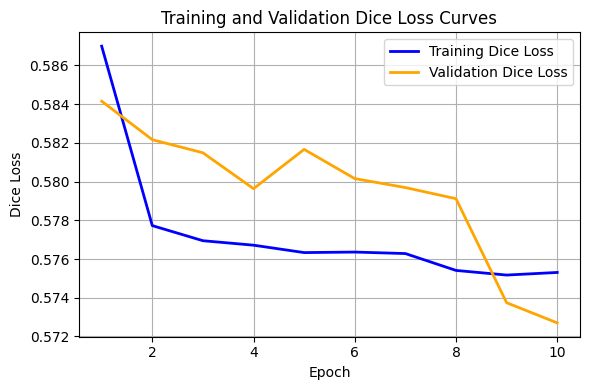

In [71]:
import matplotlib.pyplot as plt
import torch
import numpy as np

# Load the training history (adjust path/filename as needed)
history = torch.load('training_history.pt')  # Or use pickle.load if saved with pickle

# Extract losses (adjust key names if yours are different, e.g., 'train_loss', 'val_dice')
train_dice_losses = history.get('train_dice_loss', history.get('train_loss'))  # fallback to generic train_loss
val_dice_losses = history.get('val_dice_loss', history.get('val_loss'))

# If not lists already, convert if needed
train_dice_losses = np.array(train_dice_losses)
val_dice_losses = np.array(val_dice_losses)

epochs = range(1, len(train_dice_losses) + 1)

# Create the plot
plt.figure(figsize=(6, 4))
plt.plot(epochs, train_dice_losses, label='Training Dice Loss', color='blue', linewidth=2)
plt.plot(epochs, val_dice_losses, label='Validation Dice Loss', color='orange', linewidth=2)

plt.title('Training and Validation Dice Loss Curves')
plt.xlabel('Epoch')
plt.ylabel('Dice Loss')
plt.legend()
plt.grid(True)
plt.tight_layout()

# Save and/or show the plot
plt.savefig('dice_loss_curves.png')  # Saves to file for easy viewing
plt.show()  # Displays inline if in Jupyter/Colab

**Clinic DB Sequence Frame Correction**

**new metrics test set**

In [72]:
import torch
from torch.utils.data import DataLoader

# Assuming these are defined elsewhere:
# - DeepLabV3Plus (model class)
# - test_dataset (AZDataGenerator instance for test set)
# - dice_metric, iou_metric (functions to compute metrics)
# - ENCODER_NAME, BRIDGE_NAME, select_classes, DEVICE

# Initialize the model
# model = UltraLightCPS(encoder_name=ENCODER_NAME, bridge = BRIDGE_NAME, classes=2).to(DEVICE)
# model = EDANet().to(DEVICE)
# model = UNext_S(num_classes=2).to(DEVICE)
# model = LightAWNet().to(DEVICE)
# model = HarDMSEG().to(DEVICE)
# model =  PRANet(num_class=2).to(DEVICE)
# model = ColonSegNet().to(DEVICE)
# model = get_fast_scnn(num_classes=2, pretrained=False).to(DEVICE)
# model = ENet(C=2, shortcut="project", skips=True, max_dilation=8, refine_head=False,
#              upsample="interp", downsample="spd", fullres_ch=32).to(DEVICE)
# model = MALUNet().to(DEVICE)
# model = UNet(n_channels=3, n_classes=2).to(DEVICE)
# model = PolypPVT().to(DEVICE)
# model = LSCFNet(C=2).to(DEVICE)
# model = smp.DeepLabV3Plus(
#     encoder_name="efficientnet-b0", 
#     encoder_weights="imagenet", 
#     in_channels=3,  
#     classes=2, 
#     activation="sigmoid"
# ).to(DEVICE)
# model = smp.FPN(
#     encoder_name="efficientnet-b0", 
#     encoder_weights="imagenet", 
#     in_channels=3,  
#     classes=2, 
#     activation="sigmoid"
# ).to(DEVICE)
model = smp.Segformer(
    encoder_name="efficientnet-b0", 
    encoder_weights="imagenet", 
    in_channels=3,  
    classes=2, 
    activation="sigmoid"
).to(DEVICE)
# model = smp.DPT(
#     encoder_name="tu-maxvit_nano_rw_256", 
#     encoder_weights="imagenet", 
#     in_channels=3,  
#     classes=2, 
#     activation="sigmoid"
# ).to(DEVICE)


# Load the best saved model weights
model.load_state_dict(torch.load('best_model.pth', map_location=DEVICE))
print("Loaded best model weights from 'best_model.pth'")

# Set model to evaluation mode
model.eval()

# Create test data loader
test_loader = DataLoader(test_dataset, batch_size=1, shuffle=False, num_workers=4)

# ---------------------------
# Accumulators
# ---------------------------
test_dice = 0.0
test_iou = 0.0
test_precision = 0.0
test_recall = 0.0
test_f2 = 0.0
test_mae = 0.0

test_sensitivity = 0.0   # <-- added
test_specificity = 0.0   # <-- added

test_bf = 0.0
test_hd95 = 0.0

total_samples = 0

# Test loop
with torch.no_grad():
    for images, masks in test_loader:
        images, masks = images.to(DEVICE), masks.to(DEVICE)
        logits = model(images)
        preds = torch.sigmoid(logits)
        # ---- Fast Metrics ----
        test_dice      += dice_metric(preds, masks).item() * images.size(0)
        test_iou       += iou_metric(preds, masks).item() * images.size(0)
        test_precision += precision_metric(preds, masks).item() * images.size(0)
        test_recall    += recall_metric(preds, masks).item() * images.size(0)
        test_f2        += f2_metric(preds, masks).item() * images.size(0)
        test_mae       += mae_metric(preds, masks).item() * images.size(0)
        test_sensitivity += sensitivity_metric(preds, masks).item() * images.size(0) 
        test_specificity += specificity_metric(preds, masks).item() * images.size(0)


        
        # test_bf   += bf_metric(preds, masks).item() * images.size(0)
        # test_hd95 += hd95_metric(preds, masks).item() * images.size(0)
        total_samples += images.size(0)

# Compute average metrics
test_dice /= total_samples
test_iou /= total_samples
test_precision /= total_samples
test_recall /= total_samples
test_f2 /= total_samples
test_mae /= total_samples
test_bf /= total_samples
test_hd95 /= total_samples
test_sensitivity /= total_samples
test_specificity /= total_samples


# ---------------------------
# Print Summary
# ---------------------------
print("\n========== Test Results ==========")
print(f"Dice:       {test_dice:.4f}")
print(f"IoU:        {test_iou:.4f}")
print(f"Precision:  {test_precision:.4f}")
print(f"Recall:     {test_recall:.4f}")
print(f"F2 Score:   {test_f2:.4f}")
print(f"MAE:        {test_mae:.4f}")
print(f"Sensitivity: {test_sensitivity:.4f}")
print(f"Specificity: {test_specificity:.4f}")
print(f"BFScore:    {test_bf:.4f}")
print(f"HD95:       {test_hd95:.4f}")

print("=================================\n")

Loaded best model weights from 'best_model.pth'

========== Test Results ==========
Dice:       0.5253
IoU:        0.5000
Precision:  0.5000
Recall:     1.0000
F2 Score:   0.8333
MAE:        0.3928
Sensitivity: 1.0000
Specificity: 0.0000
BFScore:    0.0000
HD95:       0.0000



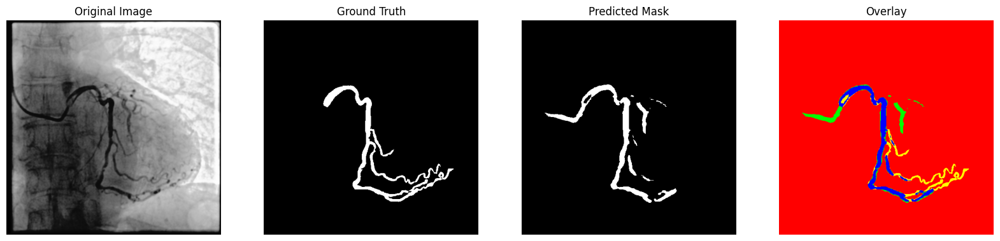

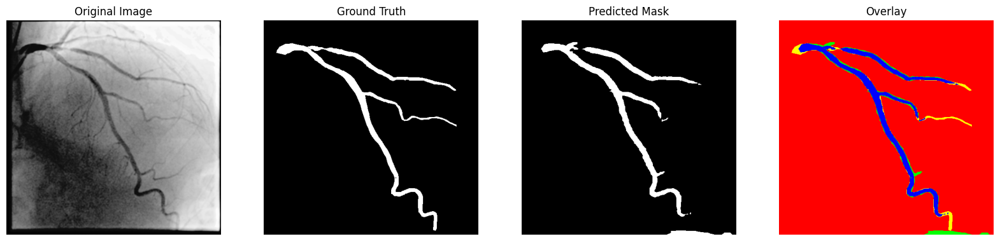

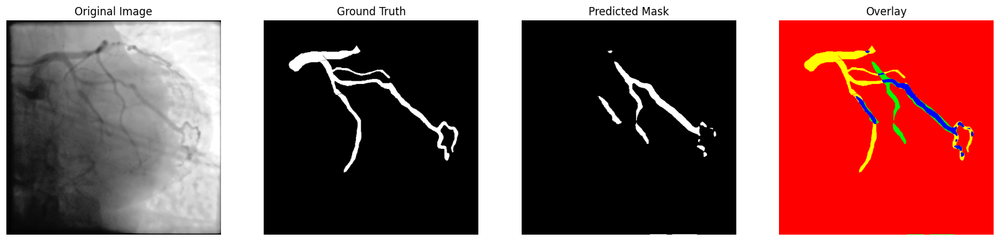

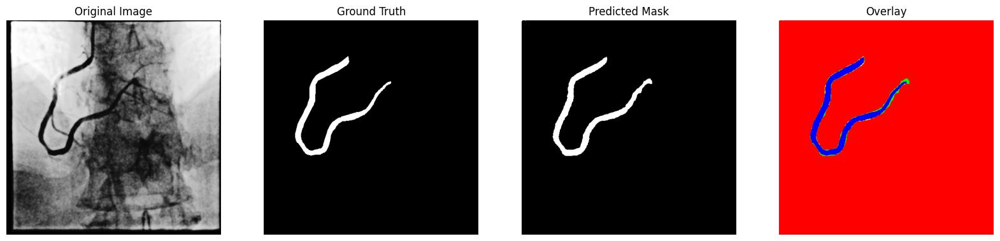

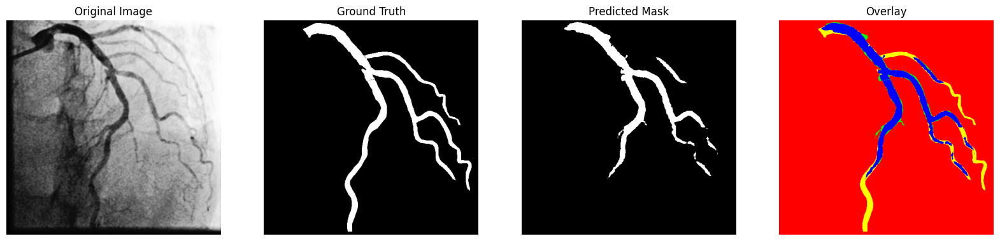

...

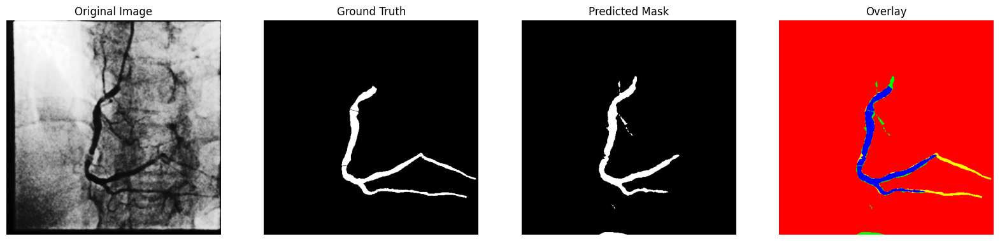

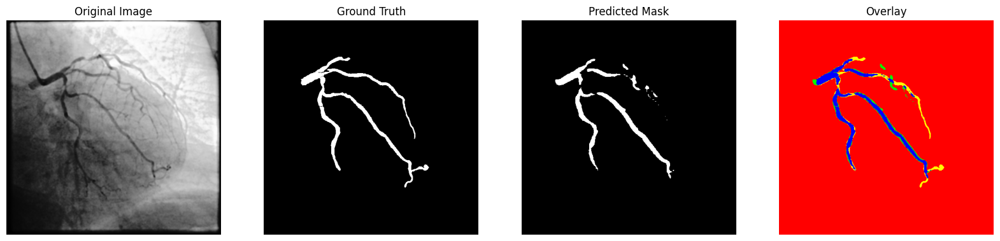

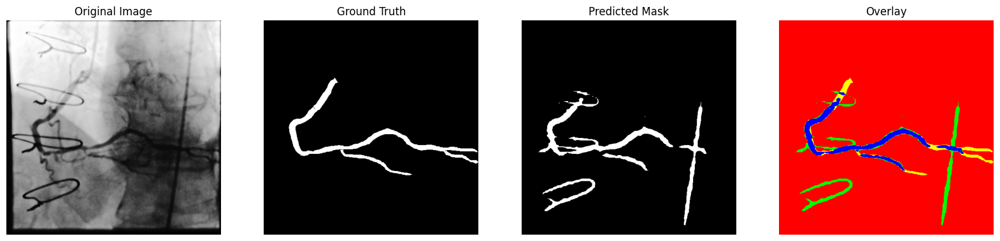

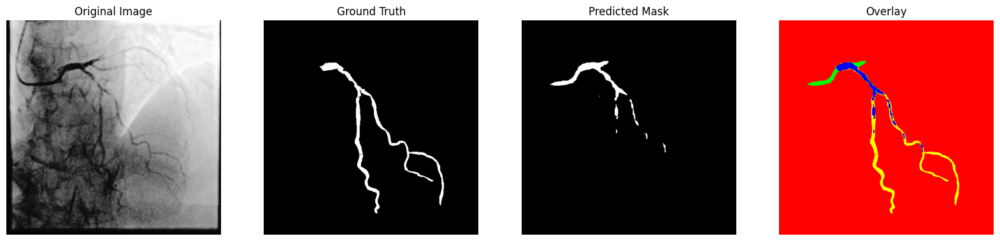

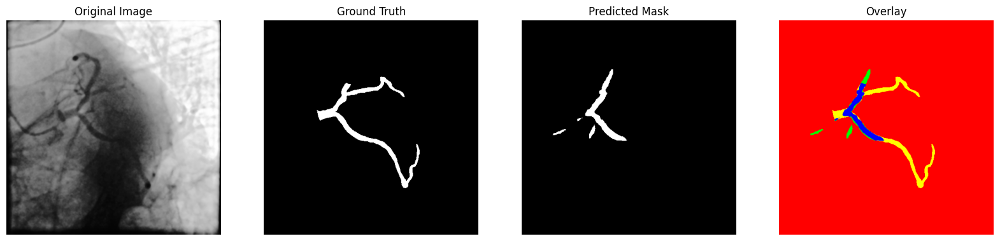

In [73]:
# Visualization on test set
test_dataset_vis = AZDataGenerator(test_df, select_class_rgb_values)  # No transforms for visualization
test_loader_vis = DataLoader(test_dataset, batch_size=1, shuffle=False)

model.load_state_dict(torch.load("best_model.pth"))
model.eval()

sample_preds_folder = 'sample_predictions/'
os.makedirs(sample_preds_folder, exist_ok=True)

max_samples = 20

for idx, (image, gt_mask) in enumerate(test_dataset):
    if idx >= max_samples:
        break

    image_vis = test_dataset_vis[idx][0].astype('uint8')
    true_dims = image_vis.shape[:2]

    x_tensor = torch.from_numpy(image).to(DEVICE).unsqueeze(0)
    
    logits = model(x_tensor)
    pred_mask = torch.sigmoid(logits).detach().squeeze().cpu().numpy()
    pred_mask = np.transpose(pred_mask, (1, 2, 0))

    pred_mask_argmax = np.argmax(pred_mask, axis=-1)
    pred_mask_grayscale = (pred_mask_argmax > 0).astype(np.uint8) * 255

    if pred_mask_grayscale.shape != true_dims:
        pred_mask_grayscale = cv2.resize(pred_mask_grayscale, (true_dims[1], true_dims[0]), interpolation=cv2.INTER_NEAREST)

    pred_mask_color = colour_code_segmentation(reverse_one_hot(pred_mask), select_class_rgb_values)
    if pred_mask_color.shape[:2] != true_dims:
        pred_mask_color = cv2.resize(pred_mask_color, (true_dims[1], true_dims[0]), interpolation=cv2.INTER_NEAREST)

    gt_mask = np.transpose(gt_mask, (1, 2, 0))
    gt_mask_argmax = np.argmax(gt_mask, axis=-1)
    gt_mask_grayscale = (gt_mask_argmax > 0).astype(np.uint8) * 255

    if gt_mask_grayscale.shape != true_dims:
        gt_mask_grayscale = cv2.resize(gt_mask_grayscale, (true_dims[1], true_dims[0]), interpolation=cv2.INTER_NEAREST)

    gt_mask_color = colour_code_segmentation(reverse_one_hot(gt_mask), select_class_rgb_values)
    if gt_mask_color.shape[:2] != true_dims:
        gt_mask_color = cv2.resize(gt_mask_color, (true_dims[1], true_dims[0]), interpolation=cv2.INTER_NEAREST)

    vis_img = np.hstack([image_vis, gt_mask_color, pred_mask_color])[:, :, ::-1]
    cv2.imwrite(os.path.join(sample_preds_folder, f"sample_pred_{idx}.png"), vis_img)

    _, gt_binary = cv2.threshold(gt_mask_grayscale, 127, 1, cv2.THRESH_BINARY)
    _, pred_binary = cv2.threshold(pred_mask_grayscale, 127, 1, cv2.THRESH_BINARY)

    if gt_binary.shape != pred_binary.shape:
        gt_binary = cv2.resize(gt_binary.astype(np.uint8), (pred_binary.shape[1], pred_binary.shape[0]), interpolation=cv2.INTER_NEAREST)

    tp = np.logical_and(pred_binary, gt_binary)
    tn = np.logical_and(~pred_binary, ~gt_binary)
    fp = np.logical_and(pred_binary, ~gt_binary)
    fn = np.logical_and(~pred_binary, gt_binary)

    vis_overlay = np.zeros((true_dims[0], true_dims[1], 3), dtype=np.uint8)
    vis_overlay[tp] = [255, 0, 0]       # Blue for TP
    vis_overlay[fp & ~tp] = [0, 255, 0] # Green for FP
    vis_overlay[tn & ~fp & ~tp] = [0, 0, 255] # Red for TN
    vis_overlay[fn & ~tp & ~fp] = [0, 255, 255] # Yellow for FN

    cv2.imwrite(os.path.join(sample_preds_folder, f"tp_tn_fp_fn_{idx}.png"), vis_overlay)

    vis_overlay_rgb = cv2.cvtColor(vis_overlay, cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(20, 5))

    plt.subplot(1, 4, 1)
    plt.title("Original Image")
    plt.imshow(image_vis)
    plt.axis('off')

    plt.subplot(1, 4, 2)
    plt.title("Ground Truth")
    plt.imshow(gt_mask_color)
    plt.axis('off')

    plt.subplot(1, 4, 3)
    plt.title("Predicted Mask")
    plt.imshow(pred_mask_color)
    plt.axis('off')

    plt.subplot(1, 4, 4)
    plt.title("Overlay")
    plt.imshow(vis_overlay_rgb)
    plt.axis('off')

    plt.show()

In [74]:
# # Visualization on test set
# test_dataset_vis = AZDataGenerator(test_df, select_class_rgb_values)

# model.load_state_dict(torch.load("best_model.pth"))
# model.eval()

# sample_preds_folder = 'sample_predictions/'
# os.makedirs(sample_preds_folder, exist_ok=True)

# max_samples = 10

# for idx, (image, gt_mask) in enumerate(test_dataset):

#     if idx >= max_samples:
#         break

#     image_vis = test_dataset_vis[idx][0].astype('uint8')
#     true_dims = image_vis.shape[:2]

#     # Prediction
#     x_tensor = torch.from_numpy(image).to(DEVICE).unsqueeze(0)

#     with torch.no_grad():
#         pred_mask = model(x_tensor).squeeze().cpu().numpy()

#     pred_mask = np.transpose(pred_mask, (1, 2, 0))

#     pred_mask_argmax = np.argmax(pred_mask, axis=-1)
#     pred_mask_grayscale = (pred_mask_argmax > 0).astype(np.uint8) * 255

#     if pred_mask_grayscale.shape != true_dims:
#         pred_mask_grayscale = cv2.resize(
#             pred_mask_grayscale,
#             (true_dims[1], true_dims[0]),
#             interpolation=cv2.INTER_NEAREST
#         )

#     pred_mask_color = colour_code_segmentation(
#         reverse_one_hot(pred_mask),
#         select_class_rgb_values
#     )

#     if pred_mask_color.shape[:2] != true_dims:
#         pred_mask_color = cv2.resize(
#             pred_mask_color,
#             (true_dims[1], true_dims[0]),
#             interpolation=cv2.INTER_NEAREST
#         )

#     # Ground Truth
#     gt_mask = np.transpose(gt_mask, (1, 2, 0))

#     gt_mask_argmax = np.argmax(gt_mask, axis=-1)
#     gt_mask_grayscale = (gt_mask_argmax > 0).astype(np.uint8) * 255

#     if gt_mask_grayscale.shape != true_dims:
#         gt_mask_grayscale = cv2.resize(
#             gt_mask_grayscale,
#             (true_dims[1], true_dims[0]),
#             interpolation=cv2.INTER_NEAREST
#         )

#     gt_mask_color = colour_code_segmentation(
#         reverse_one_hot(gt_mask),
#         select_class_rgb_values
#     )

#     if gt_mask_color.shape[:2] != true_dims:
#         gt_mask_color = cv2.resize(
#             gt_mask_color,
#             (true_dims[1], true_dims[0]),
#             interpolation=cv2.INTER_NEAREST
#         )

#     # Save combined image
#     vis_img = np.hstack([
#         image_vis,
#         gt_mask_color,
#         pred_mask_color
#     ])[:, :, ::-1]

#     cv2.imwrite(
#         os.path.join(sample_preds_folder, f"sample_pred_{idx}.png"),
#         vis_img
#     )

#     # Binary masks
#     _, gt_binary = cv2.threshold(
#         gt_mask_grayscale, 127, 1, cv2.THRESH_BINARY
#     )

#     _, pred_binary = cv2.threshold(
#         pred_mask_grayscale, 127, 1, cv2.THRESH_BINARY
#     )

#     if gt_binary.shape != pred_binary.shape:
#         gt_binary = cv2.resize(
#             gt_binary.astype(np.uint8),
#             (pred_binary.shape[1], pred_binary.shape[0]),
#             interpolation=cv2.INTER_NEAREST
#         )

#     # Confusion map
#     tp_mask = np.logical_and(pred_binary == 1, gt_binary == 1)
#     tn_mask = np.logical_and(pred_binary == 0, gt_binary == 0)
#     fp_mask = np.logical_and(pred_binary == 1, gt_binary == 0)
#     fn_mask = np.logical_and(pred_binary == 0, gt_binary == 1)

#     tp = np.sum(tp_mask)
#     tn = np.sum(tn_mask)
#     fp = np.sum(fp_mask)
#     fn = np.sum(fn_mask)

#     eps = 1e-7

#     dice = (2 * tp + eps) / (2 * tp + fp + fn + eps)
#     iou = (tp + eps) / (tp + fp + fn + eps)
#     precision = (tp + eps) / (tp + fp + eps)
#     recall = (tp + eps) / (tp + fn + eps)
#     specificity = (tn + eps) / (tn + fp + eps)
#     accuracy = (tp + tn + eps) / (tp + tn + fp + fn + eps)

#     gt_empty = np.sum(gt_binary) == 0
#     pred_empty = np.sum(pred_binary) == 0

#     print(
#         f"Sample {idx:03d} | "
#         f"GT Empty={gt_empty} | "
#         f"Pred Empty={pred_empty} | "
#         f"Dice={dice:.4f} | "
#         f"IoU={iou:.4f} | "
#         f"Precision={precision:.4f} | "
#         f"Recall={recall:.4f} | "
#         f"Specificity={specificity:.4f} | "
#         f"Accuracy={accuracy:.4f}"
#     )

#     # Overlay image
#     vis_overlay = np.zeros(
#         (true_dims[0], true_dims[1], 3),
#         dtype=np.uint8
#     )

#     vis_overlay[tp_mask] = [255, 0, 0]      # TP
#     vis_overlay[fp_mask] = [0, 255, 0]      # FP
#     vis_overlay[tn_mask] = [0, 0, 255]      # TN
#     vis_overlay[fn_mask] = [0, 255, 255]    # FN

#     cv2.imwrite(
#         os.path.join(sample_preds_folder, f"tp_tn_fp_fn_{idx}.png"),
#         vis_overlay
#     )

#     vis_overlay_rgb = cv2.cvtColor(
#         vis_overlay,
#         cv2.COLOR_BGR2RGB
#     )

#     # Plot
#     plt.figure(figsize=(24, 6))

#     plt.subplot(1, 4, 1)
#     plt.title("Original Image")
#     plt.imshow(image_vis)
#     plt.axis("off")

#     plt.subplot(1, 4, 2)
#     plt.title("Ground Truth")
#     plt.imshow(gt_mask_color)
#     plt.axis("off")

#     plt.subplot(1, 4, 3)
#     plt.title("Prediction")
#     plt.imshow(pred_mask_color)
#     plt.axis("off")

#     plt.subplot(1, 4, 4)
#     plt.title(
#         f"Overlay\n",
#         fontsize=10
#     )
#     plt.imshow(vis_overlay_rgb)
#     plt.axis("off")

#     plt.suptitle(
#         f"Sample {idx} | "
#         f"Acc={accuracy:.4f} | "
#         f"Spec={specificity:.4f}\n"
#         f"Dice={dice:.4f}\n"
#         f"IoU={iou:.4f}\n"
#         f"P={precision:.4f} R={recall:.4f}"
#         f"TP={tp} TN={tn} FP={fp} FN={fn}",
#         fontsize=30
#     )

#     plt.tight_layout()
#     plt.show()